# 材料別の温度シフト GPR（ARD Matern 5/2 ＋ 線形 ＋ ホワイトノイズ）：学習用

`05_材料ごとの機械学習データと予測検証データ` の材料ごとのデータ（**5data で学習し、3data で予測検証**）で、**温度のシフトファクターを表せる**ガウス過程回帰（GPR）の樹脂粘度モデルを作る。6月のノート（`GPR6月_ARD対応Matern52カーネル ＋ ホワイトノイズ.ipynb`）を基準にした。

**シフトファクターに使うデータ列と型は、実行の前に、設定エリアの `SHIFT_COL`・`SHIFT_FORM` で決める**（このノートは、その 1 つのモデルを学習して、図と表を一式作る。型は、選んだすべての材料に同じものを使う）。どの列と型が適しているかは、別のノート **シフトファクター検討用**（`../材料別_温度シフトファクター検討用コード/材料別_温度シフトファクターの検討_ARD対応Matern52＋線形＋ホワイトノイズ.ipynb`）で調べる（2026-10-27 に、このノートから分けた）。

- **目的変数**：樹脂粘度 η34 [Pa·s]（ln をとる）
- **説明変数**：せん断速度 γ34 [1/s]（ln）、流動中樹脂圧力 P3_3 [MPa]（Pa に直して ln）、流動中樹脂温度 Tff [℃]（K に直して ln。6月と同じ）、加熱シリンダ温度 Tset [℃]。**キャビティ厚み H は入れない**（ユーザー指定、2026-10-14）。γ̇・P3_3・Tff は、設定 `INPUT_MODE` で、ショットごとの値（`"shot"`。**既定**。6月のノートと同じ入れ方。1 ショットを 1 つのデータとして学習する。結果は `全ショット版/`）か、条件ごとの平均（`"cond"`。参考。結果は `条件ごとの平均版/`）かを選ぶ。注意：ショットごとの入力では、GP が同じ条件の中のゆれ（ショットごとの γ̇ と η が一緒に動く）に合わせるので、ln γ̇ の長さスケールが短くなり、曲線が波打って、3data の低速側の予測が外れやすい（10-15 の比較）
- **材料**：PP（01_バージンPP再々実験(データと結果)）、粉砕材混合 PP（02_粉砕材混合PP実験(データと結果)）、GPPS（03_GPPS実験(データと結果)）

**モデル**（記号は、ノートと結果のフォルダの名前で使う。本体の検討の B_1 などとは別物）

| 設定 `SHIFT_COL` | モデル（`SHIFT_FORM` が `"arrhenius"`／`"wlf"`） | 式 | 結果のフォルダ |
|---|---|---|---|
| `"加熱シリンダ温度[℃]"`（既定） | **B_Tset_Arr**／**B_Tset_WLF** | ln η = ln a_v(Tset) ＋ f( ln γ̇ ＋ ln a_h(Tset), ln P3_3, ln Tff ) | `B_Tset_Arr_アレニウス型の温度シフトに加熱シリンダ温度採用/`／`B_Tset_WLF_WLF型の…/` |
| `"流動中樹脂温度(℃)"` | **B_Tff_Arr**／**B_Tff_WLF** | ln η = ln a_v(Tff) ＋ f( ln γ̇ ＋ ln a_h(Tff), ln P3_3, Tset ) | `B_Tff_Arr_アレニウス型の温度シフトに型内樹脂温度採用/`／`B_Tff_WLF_WLF型の…/` |
| `None` | **C** | ln η = f( ln γ̇, ln P3_3, ln Tff, Tset ) | `C_温度シフトなし/` |

列名は、学習ファイルの列名のとおりに書く（GPPS のファイルの `"加熱シリンダ温度(℃)"` と書いてもよい。短い名前 `"Tset"`・`"Tff"` も使える）。温度でない列を書くと、エラーで止まる。`SHIFT_STRUCT = "A"` にすると、縦だけずらす対案（A_Tset_Arr など）になる。型内樹脂温度は、流動中樹脂温度 Tff のこと（発表資料では「金型内樹脂最高温度」）。

**学習する厚み**（設定 `THICKNESS`。2026-11-05 から）：`None`（既定）なら全厚みの 5data で 1 つのモデルを学習する。厚みの数（例：`0.5`）を書くと、**その厚みの 5data だけで学習し、同じ厚みの 3data で検証する**（結果は `<版>/厚みごと/厚み0.5mm/<モデルのフォルダ>/`）。厚みごとに、値を変えて 1 回ずつ実行する。

f は GP（ARD Matern 5/2 ＋ 線形項 ＋ ホワイトノイズ）。**横のシフト** a_h は「温度が変わると、同じ粘度になるせん断速度が a_h 倍ずれる」、**縦のシフト** a_v は「同じせん断速度で、粘度が a_v 倍になる」を表す（Tref で 1）。シフトファクターの型は、設定 `SHIFT_FORM` で選び、**選んだすべての材料に同じ型を使う**（2026-11-02 のユーザー決定。それまでは PP・粉砕材混合 PP がアレニウス型、GPPS が WLF 型だった）。
- `"arrhenius"`：**アレニウス型** ln a = (E/R)(1/T − 1/Tref)。θ = E_h・E_v [kJ/mol]（「見かけのシフトエネルギー」。文献の活性化エネルギーとは別物）。
- `"wlf"`：**WLF 型** ln a = −A1·[(T − D2)/(A2 + T − D2) − (Tref − D2)/(A2 + Tref − D2)]、A2 = 51.6 K、D2 = Tg（材料ごとに仮置き：PP・粉砕材混合 PP −10 ℃、GPPS 100 ℃）を固定し、θ = A1_h・A1_v を推定。

**推定**：θ はプロファイル尤度で決める（θ の格子の各点で GPR を学習し、対数周辺尤度 LML が最大の θ を採る。最大から 1.92 以内をおおよその 95% 区間とする）。粗い格子で全体を見て、最良の点を中心に細かい格子を取り、最良の点が動いたら（斜めの尾根の上で、細かい格子の端に当たったとき）、その点を中心に取り直す（最大 `MAX_REFINE` 回）。その後、すべての点を最良の点の解から見直し、95% 区間の端が決まるまで細かい格子を足す（2026-11-03。「5.1 プロファイル尤度」）。横と縦のシフトは、別々には決まりにくく、**差 θ_v − θ_h** が最もよく決まる（尤度の山が斜めの帯になる）。標準化と中心化は、学習データ（5data）だけで、θ によらない定数で行う。θ = 0（シフトなし）との LML の差が、B は 3.0 以上、A は 1.92 以上なら、足した係数の効果が、尤度比検定の 5% 基準（B は 2·ΔLML > 5.99、A は 2·ΔLML > 3.84）で認められる。

**読むときの注意**：P3_3 と Tff は、流れの結果として測られる量で、成形の前には分からない。このモデルは「成形条件 → 粘度」ではなく、「**測った流れの状態（γ̇・P3_3・Tff）と設定温度 → 粘度**」のモデル。3data の予測にも、3data で測った P3_3・Tff を使う。

## 使い方（このノートを一人で実行して、結果を判断するために）

**初めての人へ**：1 つ上のフォルダ（`材料別_温度シフトファクター検討/`）の説明書 `説明書_材料別温度シフトGPRのノート.pdf` に、3 つのノートの目的・関係・使えるデータ（学習ファイルの条件）・使い方をまとめてある。先に読む。

1. **実行の前に**、最初の「設定エリア」のセルで、シフトファクターに使う列 `SHIFT_COL` と型 `SHIFT_FORM` を決める（上の表。迷ったら、先にシフトファクター検討用のノートを実行し、最後のまとめに出る「SHIFT_COL・SHIFT_STRUCT・SHIFT_FORM の候補」を見る）。**注意：`SHIFT_FORM` の型は、`MATERIALS` のすべての材料に同じものを使う。材料ごとに型を変えたいとき（例：PP はアレニウス型、GPPS は WLF 型）は、`MATERIALS` を 1 つの材料にして、材料ごとに分けて実行する**（学習結果フォルダは材料ごとに別なので、結果は混ざらない）。入力の取り方 `INPUT_MODE` と、学習する材料 `MATERIALS` も、ここで決める。**厚みごとに学習するときは、`THICKNESS` に厚み（例：`0.5`）を書く**（全厚みなら `None`。厚みごとに、値を変えて 1 回ずつ実行する。その厚みのデータがない材料〔GPPS の 0.5 mm など〕は、その回は学習しない）。ほかの設定を変えるときも、このセルだけを直して、最初から実行し直す（時間を短くする：`PROFILE_RESTARTS = 0` など）。
2. メニューの「すべて実行」で、上から順に実行する。カーネルは、このプロジェクトの `.venv` を選ぶ。
3. **実行の始めに（「2. データ」のセルで）、材料ごとにダイアログが 3 回開く**：①学習データ（5data）の CSV、②検証データ（3data）の CSV、③学習結果フォルダ（結果を保存するフォルダ。新しく作るときは、ダイアログの「新しいフォルダー」で作る。**材料ごとに別のフォルダ**を選ぶ）。3 材料なら 9 回。全部選ぶと、あとは最後まで自動で進む（目安：3 材料で、ショットごとの入力は約 35 分、条件平均の入力は約 60 分〔2026-11-03 にプロファイル尤度の見直しと区間の延長を足した後の見積もり。要確認〕。大部分は「5. プロファイル尤度」。C は約 10 分）。
   - ダイアログが見当たらないときは、VS Code の後ろに隠れているので、タスクバーで探す。キャンセルすると、そこで止まる（そのセルから実行し直す）。
   - 毎回同じファイルを使うときは、設定 `FILES` に書くと、ダイアログは出ない（プロジェクトの外のファイルは、ここに書かずにダイアログで選ぶ）。
4. 結果は、選んだ学習結果フォルダの中に、次の形で保存される（同じフォルダを選んで実行し直すと、上書きされる）。
   - `データ確認/`：データの概要・外れ値の検知・P3_3 の性質（入力の取り方によらない）
   - `全ショット版/`（`INPUT_MODE = "shot"`）または `条件ごとの平均版/`（`"cond"`）の下の **`全厚み総合/<モデルの記号_説明>/`**（例：`B_Tset_Arr_アレニウス型の温度シフトに加熱シリンダ温度採用/`。型ごとに別のフォルダなので、型を変えて実行しても上書きしない）：このノートの結果のすべて（図・表・判定の一覧・まとめ・学習済みモデル）。中に `せん断速度_粘度/`・`せん断速度_粘度_拡張版/`・`依存性グラフ_セル9-2/`・`3次元グラフ/`。
   - `THICKNESS` で厚みを選んだときは、`全厚み総合/` の代わりに **`厚みごと/厚み<厚み>mm/<モデルの記号_説明>/`**（例：`厚みごと/厚み0.5mm/A_Tset_Arr_…/`）に、同じものを書く（厚みごとに別のフォルダなので、互いに上書きしない）。
   - 同じ版の `全厚み総合/シフトファクターの検討/` には、シフトファクター検討用のノートの結果、`厚みごと/` には、厚みごとの比較のノート（`../材料別_温度シフトファクター検討用コード/材料別_厚みごとの比較_温度シフトファクターの検討_ARD対応Matern52＋線形＋ホワイトノイズ.ipynb`）の結果が入る。
   - **図は、すべて 600 dpi の 1 枚だけ**（報告書・発表資料にそのまま使える。設定 `FIG_DPI`）。
5. 各節の最後に、**判定**が出る（`>> 判定：OK` か `>> 判定：★要確認`）。OK は「想定どおり」、★ は「想定と違う、または結果を読むときに注意が要る点」。基準は、判定の文の中に書いてある。★ が出ても、エラーではない。最後の「まとめ」に一覧が出る。
6. **データを取り直したとき・入れ替えたとき**：新しい CSV を、ダイアログで選ぶ（ファイルの名前と場所は自由。列名は今のまま）。問題のあるデータは `05_材料ごとの機械学習データと予測検証データ/問題データ一覧.csv` に 1 行ずつ書く（どの場所のファイルを選んでも、この一覧を使う。区分「除外」の行は、ノートが除く。「ショット」列にショット番号を書くと、そのショットだけ。`2;3` のように複数書ける）。その後、最初から実行し直す。
7. 外れ値：「3. 外れ値の検知」で、規則 f（条件平均が、ほかの条件からの予測と大きく違う）で拾った条件が一覧に未登録なら ★ が出る。PP・粉砕材混合 PP は、一覧に「除外」で登録して実行し直す（4 件以上なら相談）。GPPS は参考表示だけ。
8. **せん断速度 ― 粘度のグラフ**（6月のノートのセル9-2 と同じ見せ方）と **3次元グラフ**のセルは、セルの先頭に設定エリアがあり、**そこだけを直して、そのセルだけを実行し直せる**（全体を一度実行した後で。学習はやり直さない）。
9. 用語や図の見方は、説明書 `05_材料ごとの機械学習データと予測検証データ/05_学習結果説明書/学習結果説明_材料別温度シフトGPR.pdf` にある（10-26 までの結果で書いたもの。結果のフォルダの名前は、そのときの構成のまま）。

## 1. 設定

In [ ]:
# セル1：設定エリア  ▼▼▼ 変えてよいのは、ここだけ ▼▼▼
from pathlib import Path      # （下の REPO で、フォルダをたどるのに使う）
SHIFT_COL = "加熱シリンダ温度[℃]"   # シフトファクターに使うデータ列（学習ファイルの列名）："加熱シリンダ温度[℃]"（Tset。GPPS のファイルの書き方 "加熱シリンダ温度(℃)" でもよい）／"流動中樹脂温度(℃)"（Tff。型内樹脂温度）／None（シフトなし。4 変数を並べた通常の GPR〔C〕）。どれが適しているかは、シフトファクター検討用のノートで調べる
SHIFT_STRUCT = "A"            # シフトの形："B"＝横・縦を別々に推定／"A"＝縦だけ（対案）
SHIFT_FORM = "arrhenius"      # シフトファクターの型："arrhenius"＝アレニウス型／"wlf"＝WLF 型。選んだすべての材料に、この型を使う（2026-11-02。どちらが適しているかは、シフトファクター検討用のノートで調べる）。材料ごとに型を変えたいときは、MATERIALS を 1 つの材料にして、材料ごとに分けて実行する
SEED = 42                     # 乱数シード
NOISE_LB = 1e-6               # ノイズ分散の下限（6月のノートは 1e-3）
USE_LINEAR = True             # True：6月のカーネル（ARD Matern 5/2 ＋ ホワイトノイズ）に線形項（DotProduct）を足す（3data は射出速度の両端の外挿のため）／False：6月と同じ
INPUT_MODE = "shot"           # "shot"：γ̇・P3_3・Tff をショットごとの値で入れる（6月のノートと同じ入れ方。既定。ユーザー決定、10-23。結果は 全ショット版/）／"cond"：条件（設定温度・厚み・射出速度）ごとの平均で入れる（参考。結果は 条件ごとの平均版/）
THICKNESS = None              # 学習する厚み [mm]：None＝全厚み（既定。結果は <版>/全厚み総合/<モデルのフォルダ>/）／0.5・1.0・1.5・2.0 のどれか＝その厚みの 5data だけで学習し、同じ厚みの 3data で検証する（結果は <版>/厚みごと/厚み<厚み>mm/<モデルのフォルダ>/。2026-11-05 のユーザー依頼）。厚みごとに、値を変えて 1 回ずつ実行する。データの確認（外れ値・P3_3）は、どちらでも全厚みで行う
N_RESTARTS = 20               # 最終モデルの学習での、最適化のやり直し回数（6月は 5 回。ハイパーパラメータの尤度の面に局所解が多く、5 回では、尤度の高い解に着かないことがあったので 20 回にした。LML が最大の解を採る）
PROFILE_RESTARTS = 1          # プロファイル尤度の格子の各点での、やり直し回数（0 にすると約半分の時間。尤度の面ががたつきやすい）
USE_EXCLUSIONS = True         # True：問題データ一覧（05 フォルダ）の「除外」を除く／False：全部使う（0 以下の値の行だけは、対数がとれないので除く）
REPO = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "04_補助スクリプト").is_dir()))   # リポジトリ直下（このノートの場所から上へたどって、04_補助スクリプト があるフォルダを探す）
MATERIALS = ["MIX"]    # 学習する材料（PP：バージン PP、MIX：粉砕材混合 PP、GPPS）。材料ごとに、実行の始めにダイアログで、学習データ・検証データの CSV と、学習結果フォルダを選ぶ
MAT_FOLDERS = {"PP": "01_バージンPP再々実験(データと結果)", "MIX": "02_粉砕材混合PP実験(データと結果)", "GPPS": "03_GPPS実験(データと結果)"}   # 05 フォルダの中の材料フォルダ名（ダイアログの最初のフォルダ）
FILES = {}                    # ダイアログを使わずに決めるとき：{"PP": {"学習": r"…\結合_03_pp_max_5data_外れ値なし.csv", "検証": r"…", "結果": r"…"}}（相対パスはリポジトリ直下から）。書いていないものは、ダイアログで選ぶ
SHIFT_CFG = {                # 材料ごとの基準温度 Tref [℃]（None なら中央の設定温度）と、WLF 型の D2 = Tg [℃]（仮置き。分かれば直す。アレニウス型では使わない）
    "PP":   {"Tref": 210.0, "Tg": -10.0},      # Tg：Moldflow の PP でよく使われる D2 = 263.15 K
    "MIX":  {"Tref": 210.0, "Tg": -10.0},
    "GPPS": {"Tref": 220.0, "Tg": 100.0},
}
FORM_CFG = {                  # 型ごとの、尤度を調べる範囲（粗い格子：(下限, 上限, 刻み)。h が横、v が縦）と、細かい格子 "fine"（±幅, 刻み。書いた型だけ、下の FINE_B・FINE_A の代わりに使う）
    "arrhenius": {"h_grid": (-20.0, 40.0, 5.0), "v_grid": (-20.0, 60.0, 5.0)},                            # θ = E [kJ/mol]
    "wlf":       {"A2": 51.6, "h_grid": (-20.0, 40.0, 5.0), "v_grid": (-20.0, 40.0, 5.0), "fine": (2.0, 0.25)},   # θ = A1 [−]、A2 [K] は固定。A1 の 1 は、粘度の比にして E の 1 kJ/mol より大きい（GPPS で約 3.5 倍）ので、刻みを 0.25 にする
}
FINE_B = (4.0, 1.0)           # B の細かい格子：最良の点の ±4 を 1 刻み
FINE_A = (4.5, 0.5)           # A の細かい格子：最良の点の ±4.5 を 0.5 刻み（粗い格子の刻み 5 の、隣の点の手前まで）
MAX_REFINE = 4                # 最良の点が細かい格子の端に当たったとき、その点を中心に細かい格子を取り直す回数の上限（取り直しても動かなければ、そこで終わり）
MAX_EXTEND = 20               # 95% 区間の端が細かい格子の中で決まるまで、区間の外側に細かい格子の点を 1 列ずつ足す回数の上限（2026-11-03）
OUTLIER_REGISTER = ["PP", "MIX"]   # 外れ値（規則 f）を問題データ一覧に登録して除く材料（GPPS は参考表示だけ。ユーザー決定、10-14）
CWLF_T = "Tff"                # 参考の Cross-WLF に使う温度（6月と同じく流動中樹脂温度。"Tset" も可）
CWLF_STARTS = 12              # 参考の Cross-WLF の当てはめの初期値の数（6月に近い値 1 つ ＋ 乱数。残差が最小のものを採る）
CWLF_FIXED = {                # Cross-WLF の係数（D3 = 0）。数＝固定、None＝5data で探索。D2 は K
    "PP":   {"n": None, "tau_star": None, "D1": None, "D2": None, "A1": 30.9, "A2": 43.4486},     # 6月のノートと同じ固定値
    "MIX":  {"n": None, "tau_star": None, "D1": None, "D2": None, "A1": 30.9, "A2": 43.4486},
    "GPPS": {"n": None, "tau_star": None, "D1": None, "D2": 373.15, "A1": None, "A2": 51.6},      # D2 = Tg（仮置き 100 ℃）
}
N_JOBS = 8                    # プロファイル尤度を並列に計算する数（CPU の数に合わせる）
FIG_DPI = 600                 # 保存する図の解像度（すべての図を、この解像度の 1 枚だけで保存する。報告書・発表資料用）
SHOW_FIGS = True              # True：図をノートにも表示する（False：保存だけ）
# ▲▲▲ 設定エリア終了 ▲▲▲

In [50]:
# セル2：ライブラリ、フォント
%matplotlib inline
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.tri as mtri
from IPython.display import display

plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
try:
    fm.findfont("IPAexGothic", fallback_to_default=False)
except ValueError:
    raise RuntimeError("日本語フォント IPAexGothic が見つかりません。インストールしてからカーネルを再起動してください。")
plt.rcParams["font.family"] = ["IPAexGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("Python:", sys.executable, "/", sys.version.split()[0])

Python: c:\Users\0uh2j\Desktop\vscodeで\修士研究作業_樹脂粘度モデル構築\08_機械学習\01_ガウス過程回帰2_202610から\ガウス過程回帰2_機械学習\.venv\Scripts\python.exe / 3.12.12


### 共通の部品

ファイルを選ぶダイアログ、データの読み込み（加熱シリンダ温度の列がないファイルは、元ファイル名から取る）、問題データ一覧の「除外」、結果の置き場所、シフトファクター（アレニウス型・WLF 型）、モデルの学習と予測、プロファイル尤度、評価、外れ値の検知、Cross-WLF、図の保存。中身は `04_補助スクリプト/mat_common.py` と同じ。

In [51]:
# セル：共通の部品（読み込み・問題データ一覧・シフトファクター・モデル・評価・図）。04_補助スクリプト/mat_common.py の中身。直すときは、そのファイルを直して、ノートを作り直す
import glob
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, DotProduct, Matern, Sum, WhiteKernel
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------------- 設定（ノートの設定エリアの値があれば、それを使う）
SEED = globals().get("SEED", 42)
NOISE_LB = globals().get("NOISE_LB", 1e-6)                  # ノイズ分散の下限（6月のノートは 1e-3）
N_RESTARTS = globals().get("N_RESTARTS", 20)                # 最終モデルの学習での、最適化のやり直し回数（ハイパーパラメータの局所解が多いので、6月の 5 回より多くする）
PROFILE_RESTARTS = globals().get("PROFILE_RESTARTS", 1)     # プロファイル尤度の格子の各点での、やり直し回数（前の点の解も初期値に使う）
USE_LINEAR = globals().get("USE_LINEAR", True)              # True：6月のカーネルに線形項（DotProduct）を足す
USE_EXCLUSIONS = globals().get("USE_EXCLUSIONS", True)      # 問題データ一覧の「除外」を使うか
REPO = globals().get("REPO", os.environ.get("NB_REPO", ".."))
N_JOBS = globals().get("N_JOBS", 8)
FIG_DPI = globals().get("FIG_DPI", 600)                     # 保存する図の解像度。すべての図を、この解像度の 1 枚だけで保存する（報告書・発表資料用。2026-10-27 から）
SHOW_FIGS = globals().get("SHOW_FIGS", True)                # 図をノートに表示するか（False なら保存だけ）
INPUT_MODE = globals().get("INPUT_MODE", "shot")            # "shot"：γ̇・P3_3・Tff をショットごとの値で入れる（6月のノートと同じ。既定）／"cond"：条件（設定温度・厚み・射出速度）ごとの平均で入れる（参考）
MAX_REFINE = globals().get("MAX_REFINE", 4)                 # プロファイル尤度で、最良の点が細かい格子の端に当たったとき、その点を中心に細かい格子を取り直す回数の上限
MAX_EXTEND = globals().get("MAX_EXTEND", 20)                # プロファイル尤度で、95% 区間の端が細かい格子の中で決まるまで、区間の外側に細かい格子の点を 1 列ずつ足す回数の上限（2026-11-03）
FINE_B = globals().get("FINE_B", (4.0, 1.0))               # 構造 B の細かい格子：最良の点の ±4 を 1 刻み
FINE_A = globals().get("FINE_A", (4.5, 0.5))                # 構造 A の細かい格子：最良の点の ±4.5 を 0.5 刻み（粗い格子の刻み 5 の、隣の点の手前まで。2026-11-02）
OUTLIER_Z = globals().get("OUTLIER_Z", 3.5)                 # 規則 f：|z| がこれを超え、かつ |残差|（ln η）が次の値を超える条件
OUTLIER_RESID = globals().get("OUTLIER_RESID", 0.1)
P33_DEV = globals().get("P33_DEV", 0.2)                     # 規則 g：P3_3 が条件の中央値から、この割合以上離れたショットを候補にする
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # 下限・上限への張り付きは、ハイパーパラメータの表に記録する

# ---------------------------------------------------------------- データの場所と列
DATA_ROOT = os.path.join(REPO, "05_材料ごとの機械学習データと予測検証データ")
PROBLEM_CSV = os.path.join(DATA_ROOT, "問題データ一覧.csv")
MAT_FOLDERS = globals().get("MAT_FOLDERS", {"PP": "01_バージンPP再々実験", "MIX": "02_粉砕材混合PP実験", "GPPS": "03_GPPS実験"})
MAT_NAMES = {"PP": "PP", "MIX": "粉砕材混合PP", "GPPS": "GPPS"}     # 問題データ一覧の「材料」列の名前
DATA_SUB = "*_学習・検証データ"                                     # 材料フォルダの中の、学習データと検証データのフォルダをまとめたフォルダ（2026-11-03 のユーザーのフォルダの整理〔a4ad4b8〕で、01_学習・検証データ/ などができた）
GROUP_DIRS = {"5data": "学習データ_*", "3data": "検証データ_*"}      # DATA_SUB の中の、学習データと検証データのフォルダ（CSV が 1 つずつ）
COLS = {"元ファイル": "file", "キャビ厚": "H", "射出速度[mm/s]": "v", "樹脂粘度η34(Pa・s)": "eta", "せん断速度γ34(1/s)": "gd",
        "流動中樹脂圧力P3_1(MPa)": "P31", "流動中樹脂圧力P3_2(MPa)": "P32", "流動中樹脂圧力P3_3(MPa)": "P33",
        "加熱シリンダ温度[℃]": "Tset", "加熱シリンダ温度(℃)": "Tset", "流動中樹脂温度(℃)": "Tff"}
REQUIRED = ["file", "H", "v", "eta", "gd", "P33", "Tff"]          # 加熱シリンダ温度の列がなければ、元ファイル名から取る
RE_SRC = r"^(\d{3})_(\d+)℃_(\d{3})_([\d.]+)mm[A-Za-z]*\.csv$"     # ショット_設定温度_射出速度_厚み（GPPS は末尾に NR が付く）
R_GAS = 8.314                                                      # 気体定数 [J/mol/K]
D = {}             # (材料, 組) → DataFrame。組は "5data"（学習）と "3data"（検証）
FILE_INFO = {}     # (材料, 組) → 読んだファイルの情報
REMOVED = {}       # (材料, 組) → 一覧の「除外」で除いた行（元ファイルと ID）
INVALID = {}       # (材料, 組) → 0 以下の値（η・γ̇・P3_3）で対数がとれず、一覧に登録がないまま除いた行
JUDGES = []        # 判定の記録（まとめの表に使う）
SOURCES = {}       # 材料 → {"5data": 学習データの CSV, "3data": 検証データの CSV, "結果": 学習結果フォルダ}（choose_inputs で決める）

# ---------------------------------------------------------------- 結果の置き場所（2026-10-27 からの構成）
VERSION_DIRS = {"cond": "条件ごとの平均版", "shot": "全ショット版"}   # 学習結果フォルダの直下の分け方（入力の取り方 INPUT_MODE ごと）。図のタイトルと、表の「入力」の列にも使う
THICK_TOTAL, THICK_EACH = "全厚み総合", "厚みごと"   # その下の分け方：全厚みの 5data で 1 つのモデルを学習した結果（学習用・シフトファクター検討用のノート）／厚みごとの比較のノートの結果
STUDY_DIR = "シフトファクターの検討"                  # 全厚み総合/ の下の、シフトファクター検討用ノートの結果のフォルダ
MODE_JA = {"shot": "ショットごとの入力", "cond": "条件平均の入力"}   # 10-26 までの結果のフォルダの名前（<材料フォルダ>/<番号>_学習結果/<材料フォルダ>_学習結果(5all学習データ)/ の下。その結果は、この構成のまま残す。発表資料・ポスターのスクリプトが読む）
DATA_KINDS = {"5data": ("学習", "学習データ（5data）の CSV"), "3data": ("検証", "検証データ（3data）の CSV")}   # 組 → (設定 FILES での名前, ダイアログの説明)
PATH_MAX = 260     # Windows のパスの長さの上限（文字）
DEEPEST = 105      # 学習結果フォルダの下の、最も長いファイルの場所の長さ（文字）の目安（せん断速度_粘度_拡張版/ の英語の凡例の図など。2026-11-02 にモデルのフォルダの名前に型が入って長くなった）


def show_path(p):
    """表や記録に書く場所：リポジトリの中なら、リポジトリ直下からの相対パス。外なら、そのまま（絶対パス）"""
    a, r = os.path.abspath(p), os.path.abspath(REPO)
    try:
        inside = os.path.normcase(os.path.commonpath([a, r])) == os.path.normcase(r)
    except ValueError:                                       # ドライブが違う
        inside = False
    return os.path.relpath(a, r) if inside else a


def full_path(p):
    """設定や記録に書いた場所 → 絶対パス（相対パスは、リポジトリ直下から）"""
    return os.path.abspath(p if os.path.isabs(p) else os.path.join(REPO, p))


def ask_path(title, kind="file", initialdir=None):
    """ダイアログで、CSV ファイル（kind = "file"）かフォルダ（kind = "dir"）を選ぶ（tkinter）。選んだ場所を返す。
    キャンセルしたら止める（例外）。ダイアログは、ほかのウィンドウの手前に出す（VS Code の後ろに隠れたら、タスクバーで探す）"""
    import tkinter as tk
    from tkinter import filedialog
    print(f"ダイアログを開きます：{title}", flush=True)
    root = tk.Tk()
    root.withdraw()                                          # 空の親ウィンドウは見せない
    root.attributes("-topmost", True)                       # ダイアログを、ほかのウィンドウの手前に出す
    root.update()
    start = initialdir if initialdir and os.path.isdir(initialdir) else None
    try:
        if kind == "file":
            p = filedialog.askopenfilename(parent=root, title=title, initialdir=start, filetypes=[("CSV ファイル", "*.csv"), ("すべてのファイル", "*.*")])
        else:
            p = filedialog.askdirectory(parent=root, title=title, initialdir=start, mustexist=False)
    finally:
        root.destroy()
    if not p:
        raise RuntimeError(f"選ばれなかったので止めました（{title}）。もう一度、このセルから実行してください")
    return os.path.normpath(p)


def choose_inputs(mats, files=None, need_data=True):
    """材料ごとに、学習データ（5data）・検証データ（3data）の CSV と、学習結果フォルダを決めて、SOURCES に記録する（実行の始めに、まとめて聞く）。
    files（ノートの設定 FILES）：{材料: {"学習": CSV, "検証": CSV, "結果": フォルダ}}。書いてあるものはそれを使い、ないものはダイアログで選ぶ（相対パスは、リポジトリ直下から）。
    need_data = False なら、学習結果フォルダだけを決める（データの場所は、学習済みモデルの記録から取る。data_from_model）。
    同じ学習結果フォルダを 2 つの材料で選ぶと、結果が上書きされるので止める。決めたものの表を返す"""
    files = files or {}
    rows = []
    for mat in mats:
        f, src = files.get(mat, {}), SOURCES.setdefault(mat, {})
        start = os.path.join(DATA_ROOT, MAT_FOLDERS.get(mat, ""))   # ダイアログの最初のフォルダ（05 フォルダの材料フォルダ）
        for grp, (name, what) in DATA_KINDS.items():
            if not (f.get(name) or need_data):
                continue
            p = full_path(f[name]) if f.get(name) else ask_path(f"【{MAT_NAMES[mat]}】{what} を選んでください", "file", start)
            if not os.path.isfile(p):
                raise FileNotFoundError(f"{MAT_NAMES[mat]}：{what} が見つかりません（{p}）")
            src[grp] = p
        d = full_path(f["結果"]) if f.get("結果") else ask_path(
            f"【{MAT_NAMES[mat]}】学習結果フォルダを選んでください（この下に「{VERSION_DIRS['shot']}」「{VERSION_DIRS['cond']}」などを作ります）", "dir", start)
        os.makedirs(d, exist_ok=True)
        src["結果"] = d
        if len(os.path.abspath(d)) + DEEPEST > PATH_MAX:
            print(f"★ 注意：{MAT_NAMES[mat]} の学習結果フォルダの場所が長い（{len(os.path.abspath(d))} 文字）ので、中に作るファイルの場所が、"
                  f"Windows の上限 {PATH_MAX} 文字を超えるおそれがあります。もっと浅いフォルダを選ぶと安全です")
        rows.append({"材料": MAT_NAMES[mat], **{f"{DATA_KINDS[g][0]}データ": show_path(src[g]) for g in DATA_KINDS if src.get(g)}, "学習結果フォルダ": show_path(d)})
    roots = [os.path.normcase(os.path.abspath(SOURCES[m]["結果"])) for m in mats]
    dup = sorted({r for r in roots if roots.count(r) > 1})
    if dup:
        raise ValueError("2 つ以上の材料で、同じ学習結果フォルダが選ばれました（結果が上書きされます）。材料ごとに別のフォルダを選んでください：" + "、".join(dup))
    return pd.DataFrame(rows)


def data_from_model(mat, obj):
    """学習済みモデル（joblib の中身 obj）に記録した、学習データ・検証データの場所を SOURCES に入れる（設定 FILES で決めたものは、そのまま使う）。
    記録の場所にファイルがなければ、ダイアログで選ぶ"""
    src = SOURCES.setdefault(mat, {})
    for grp, (name, what) in DATA_KINDS.items():
        if src.get(grp):
            continue
        rec = obj.get(f"{name}データのファイル")
        p = full_path(rec) if rec else None
        if not (p and os.path.isfile(p)):
            print(f"【{MAT_NAMES[mat]}】学習済みモデルに記録された{what} が見つかりません（{rec}）")
            p = ask_path(f"【{MAT_NAMES[mat]}】{what} を選んでください", "file", os.path.join(DATA_ROOT, MAT_FOLDERS.get(mat, "")))
        src[grp] = p


def result_root(mat):
    """学習結果フォルダ（choose_inputs で決めたもの）"""
    d = SOURCES.get(mat, {}).get("結果")
    if not d:
        raise RuntimeError(f"{MAT_NAMES[mat]}：学習結果フォルダが決まっていません（先に choose_inputs で決める）")
    return d


def result_dir(mat, *parts, make=True):
    """学習結果フォルダの下の場所。parts の中のモデルの記号（B_Tset など）は、フォルダの名前（MODEL_DIRS）に直す。
    make が True なら、フォルダがなければ作る（読むだけのときは False）。
    例：result_dir(mat, "データ確認")、result_dir(mat, VERSION_DIRS[INPUT_MODE], THICK_TOTAL, "B_Tset")"""
    d = os.path.join(result_root(mat), *[MODEL_DIRS.get(p, p) for p in parts])
    if make:
        os.makedirs(d, exist_ok=True)
    return d


def path_of(mat, grp):
    """読む CSV：choose_inputs で決めたもの。決めていなければ（ノートの外のスクリプト）、05 フォルダの材料フォルダの DATA_SUB の中から探す（2026-11-03 から。
    それまでは材料フォルダの直下）。そのときは、名前に「温度適切」を含むフォルダ（2026-11-02 に増えた温度適切版）を除き、通常版（10-26 までの結果に使ったデータ）を使う"""
    if SOURCES.get(mat, {}).get(grp):
        return SOURCES[mat][grp]
    fs = [f for f in sorted(glob.glob(os.path.join(DATA_ROOT, MAT_FOLDERS[mat], DATA_SUB, GROUP_DIRS[grp], "*.csv"))) if "温度適切" not in os.path.basename(os.path.dirname(f))]
    assert len(fs) == 1, f"{MAT_FOLDERS[mat]}/{DATA_SUB}/{GROUP_DIRS[grp]} に CSV が 1 つだけあるはず（見つかったもの: {fs}）"
    return fs[0]


# ---------------------------------------------------------------- 問題データ一覧
def read_problem_list(path=None):
    """問題データ一覧.csv（05 フォルダ）を読む（空欄は空文字）"""
    return pd.read_csv(path or PROBLEM_CSV, encoding="utf-8-sig", dtype=str).fillna("")


def problem_mask(df, mat, grp, plist, kinds):
    """区分が kinds のどれかで、再測定が「済み」でない一覧の行のうち、この材料・組・条件に当てはまる行の真偽値と、その ID を返す。
    「ショット」列は、空欄なら条件全体、数字ならそのショット（元ファイル名の先頭 3 桁）。"2;3" のように複数書ける"""
    mask = np.zeros(len(df), bool)
    ids = [[] for _ in range(len(df))]
    for _, r in plist.iterrows():
        if r["区分"] not in kinds or r["再測定"] == "済み" or r["データ"] not in ("新", ""):
            continue
        if r["材料"] not in ("すべて", "", MAT_NAMES[mat]) or r["組"] not in ("", grp):
            continue
        m = np.ones(len(df), bool)
        if r["設定温度"] != "":
            m &= df["Tset"].to_numpy() == float(r["設定温度"])
        if r["厚み"] != "":
            m &= np.isclose(df["H"].to_numpy(), float(r["厚み"]))
        if r["射出速度"] != "":
            m &= df["v"].to_numpy() == float(r["射出速度"])
        if r.get("ショット", "") != "":
            shots = [int(s) for s in re.split(r"[;；,、]", r["ショット"]) if s.strip()]
            m &= np.isin(df["shot"].to_numpy(), shots) if "shot" in df.columns else np.zeros(len(df), bool)
        mask |= m
        for i in np.flatnonzero(m):
            ids[i].append(r["ID"])
    return mask, [";".join(x) for x in ids]


# ---------------------------------------------------------------- 読み込み
def load(mat, grp, plist=None, exclude=None):
    """結合ファイル（path_of：choose_inputs で選んだ CSV）を読み、形式を確かめ、問題データ一覧の「除外」を除く。
    加熱シリンダ温度の列がないファイル（PP の 3data）は、元ファイル名から設定温度を取る。列があれば、ファイル名と一致するかを確かめる。
    η・γ̇・P3_3 が 0 以下の行は対数がとれないので、一覧に登録がなくても除き、INVALID に記録する（判定で ★）。
    列 sens には「感度確認」の ID が入る（なければ空文字）。圧力は Pa に直してから ln をとる。Tff の ln は K で"""
    exclude = USE_EXCLUSIONS if exclude is None else exclude
    path = path_of(mat, grp)
    raw = pd.read_csv(path, encoding="utf-8-sig")
    unknown = [c for c in raw.columns if c not in COLS]
    assert not unknown, f"想定にない列がある: {unknown}（mat_common.py の COLS に足す）"
    df = raw.rename(columns=COLS)
    missing = [c for c in REQUIRED if c not in df.columns]
    assert not missing, f"必要な列がない: {missing}（{path}）"
    assert df[REQUIRED].isna().sum().sum() == 0, f"欠損がある（{path}）"
    p = df["file"].str.extract(RE_SRC)
    assert p.notna().all().all(), f"元ファイル名の形式に合わない行がある（{path}）"
    assert np.allclose(p[2].astype(float), df["v"]) and np.allclose(p[3].astype(float), df["H"]), "元ファイル名と、厚み・射出速度の列が一致しない"
    has_tset = "Tset" in df.columns
    if has_tset:
        assert np.allclose(p[1].astype(float), df["Tset"].astype(float)), "元ファイル名と、加熱シリンダ温度の列が一致しない"
    else:
        df["Tset"] = p[1].astype(float)
    df["Tset"] = df["Tset"].astype(float)
    df["shot"] = p[0].astype(int)
    plist = read_problem_list() if plist is None else plist
    n_raw = len(df)
    if exclude:
        drop, ids = problem_mask(df, mat, grp, plist, ("除外",))
        REMOVED[(mat, grp)] = pd.DataFrame({"元ファイル": df.loc[drop, "file"].to_numpy(), "ID": np.array(ids, dtype=object)[drop]})
        df = df[~drop].reset_index(drop=True)
    else:
        REMOVED[(mat, grp)] = pd.DataFrame(columns=["元ファイル", "ID"])
    bad = (df[["eta", "gd", "P33"]] <= 0).any(axis=1).to_numpy()
    INVALID[(mat, grp)] = df.loc[bad, ["file", "Tset", "H", "v", "shot", "eta", "gd", "P33"]].reset_index(drop=True)
    df = df[~bad].reset_index(drop=True)
    _, df["sens"] = problem_mask(df, mat, grp, plist, ("感度確認",))
    df["is_sens"] = df["sens"] != ""
    df["cond"] = df["Tset"].astype(int).astype(str) + "_" + df["H"].astype(str) + "_" + df["v"].astype(int).astype(str)
    df["ln_eta"], df["ln_gd"], df["ln_H"], df["ln_v"] = np.log(df["eta"]), np.log(df["gd"]), np.log(df["H"]), np.log(df["v"])
    df["ln_P33"] = np.log(df["P33"] * 1e6)                 # CSV の圧力は MPa。Pa に直してから ln をとる
    df["ln_Tff"] = np.log(df["Tff"] + 273.15)               # 流動中樹脂温度 [K] の ln（6月のノートと同じ）
    for c in ["gd", "P33", "Tff"]:                          # 条件ごとの平均（INPUT_MODE = "cond" の入力、図の予測線、外れ値の検知に使う）
        df[f"ln_{c}_cm"] = df.groupby("cond")[f"ln_{c}"].transform("mean")
    df["Tff_cm"] = np.exp(df["ln_Tff_cm"]) - 273.15
    df["grp"] = grp
    FILE_INFO[(mat, grp)] = {"材料": MAT_NAMES[mat], "組": grp, "ファイル": show_path(path), "読んだ行数": n_raw,
                             "一覧で除外": n_raw - len(df) - int(bad.sum()), "0以下で除外（未登録）": int(bad.sum()), "使う行数": len(df),
                             "条件数": df["cond"].nunique(), "ショット/条件": f"{df.groupby('cond').size().min()}〜{df.groupby('cond').size().max()}",
                             "設定温度": "・".join(str(int(t)) for t in sorted(df["Tset"].unique())), "設定温度の取り方": "列" if has_tset else "元ファイル名",
                             "厚み": "・".join(f"{h:g}" for h in sorted(df["H"].unique())), "射出速度": "・".join(str(int(v)) for v in sorted(df["v"].unique())),
                             "感度確認の行": int(df["is_sens"].sum())}
    return df


def load_all(mats, exclude=None):
    """材料ごとに 5data（学習）と 3data（検証）を読む。学習と検証で条件が重ならないことも確かめる"""
    plist = read_problem_list()
    out = {(mat, grp): load(mat, grp, plist, exclude) for mat in mats for grp in ["5data", "3data"]}
    for mat in mats:
        both = set(out[(mat, "5data")]["cond"]) & set(out[(mat, "3data")]["cond"])
        assert not both, f"{MAT_NAMES[mat]}：学習と検証で条件が重なっている: {sorted(both)}"
    return out


def add_groups(tr, te):
    """検証の行を、学習データの射出速度の範囲より遅い側（低速側）・速い側（高速側）・範囲内に分ける（列 group）"""
    te = te.copy()
    vmin, vmax = tr["v"].min(), tr["v"].max()
    te["group"] = np.where(te["v"] < vmin, "低速側", np.where(te["v"] > vmax, "高速側", "範囲内"))
    return te


# ---------------------------------------------------------------- 温度のシフトファクター
# 2026-11-02（ユーザー決定）：型を材料ごとに分けず、どの材料にも両方の型を当てはめられるようにした。材料ごとの設定 SHIFT_CFG は基準温度と WLF 型の Tg、
# 型ごとの設定 FORM_CFG は係数を調べる格子。モデルに使う設定（cfg）は、2 つを合わせたもの（shift_cfg）
FORMS = {"arrhenius": "Arr", "wlf": "WLF"}          # シフトファクターの型 → モデルの記号の末尾（例：B_Tset_Arr）
FORM_JA = {"arrhenius": "アレニウス型", "wlf": "WLF型"}
DEFAULT_SHIFT_CFG = {     # 材料ごとの基準温度 Tref [℃]（None なら中央の設定温度）と、WLF 型の D2 = Tg [℃]（PP・粉砕材混合 PP の −10 ℃ は、Moldflow の PP でよく使われる D2 = 263.15 K。GPPS の 100 ℃ とも仮置き）
    "PP": {"Tref": 210.0, "Tg": -10.0},
    "MIX": {"Tref": 210.0, "Tg": -10.0},
    "GPPS": {"Tref": 220.0, "Tg": 100.0},
}
DEFAULT_FORM_CFG = {      # 型ごとの、尤度を調べる粗い格子（下限, 上限, 刻み。h が横、v が縦のシフトの係数）と、細かい格子 fine（±幅, 刻み。書いた型だけ、FINE_A・FINE_B の代わりに使う）
    "arrhenius": {"h_grid": (-20.0, 40.0, 5.0), "v_grid": (-20.0, 60.0, 5.0)},                            # θ = E [kJ/mol]。細かい格子は FINE_B・FINE_A
    "wlf": {"A2": 51.6, "h_grid": (-20.0, 40.0, 5.0), "v_grid": (-20.0, 40.0, 5.0), "fine": (2.0, 0.25)},   # θ = A1 [−]、A2 [K] は固定。A1 の 1 は、粘度の比にして E の 1 kJ/mol より大きい（GPPS で約 3.5 倍）ので、0.25 刻み
}
SHIFT_CFG = globals().get("SHIFT_CFG", DEFAULT_SHIFT_CFG)
FORM_CFG = globals().get("FORM_CFG", DEFAULT_FORM_CFG)


def shift_cfg(mat, form, tr=None):
    """材料 mat に型 form（"arrhenius"・"wlf"）を当てはめるときの設定（shift_ln・run_profile などに渡す cfg）。Tref が None なら、学習データ tr の中央の設定温度"""
    if form not in FORMS:
        raise ValueError(f"シフトファクターの型は {list(FORMS)} のどれかです（指定：{form}）")
    cfg = {**FORM_CFG[form], **SHIFT_CFG[mat], "type": form}
    if cfg.get("Tref") is None:
        lv = sorted(tr["Tset"].unique())
        cfg["Tref"] = float(lv[len(lv) // 2])
    return cfg


def key_form(key):
    """モデルの記号 → シフトファクターの型（末尾が Arr・WLF の記号だけ。C と、型の付かない 10-26 までの記号〔B_Tset など〕は None）"""
    p = str(key).split("_")
    return next((f for f, s in FORMS.items() if len(p) == 3 and p[2] == s), None)


def shift_ln(T_c, theta, cfg):
    """ln a(T)（T は ℃。Tref で 0）。
    アレニウス型：ln a = (E/R)(1/T − 1/Tref)、theta = E [kJ/mol]。
    WLF 型：ln a = −A1·[(T − D2)/(A2 + T − D2) − (Tref − D2)/(A2 + Tref − D2)]、theta = A1 [−]、D2 = Tg、A2 は固定"""
    T = np.asarray(T_c, float) + 273.15
    Tr = float(cfg["Tref"]) + 273.15
    if cfg["type"] == "arrhenius":
        return float(theta) * 1000.0 / R_GAS * (1.0 / T - 1.0 / Tr)
    D2, A2 = float(cfg["Tg"]) + 273.15, float(cfg["A2"])
    return -float(theta) * ((T - D2) / (A2 + T - D2) - (Tr - D2) / (A2 + Tr - D2))


def theta_names(cfg):
    """(横の名前, 縦の名前, 単位)"""
    return ("E_h", "E_v", "kJ/mol") if cfg["type"] == "arrhenius" else ("A1_h", "A1_v", "−")


# ---------------------------------------------------------------- モデル
MODEL_JA = {"B_Tset": "B_Tset（設定温度 Tset で横・縦にシフト）", "B_Tff": "B_Tff（流動中樹脂温度 Tff で横・縦にシフト）",
            "A_Tset": "A_Tset（Tset で縦だけシフト）", "A_Tff": "A_Tff（Tff で縦だけシフト）",
            "C": "C（シフト構造なし。4 変数を並べた通常の GPR）"}
MODEL_DIRS = {"B_Tset": "B_Tset_温度シフトに加熱シリンダ温度採用", "B_Tff": "B_Tff_温度シフトに型内樹脂温度採用",
              "A_Tset": "A_Tset_縦だけの温度シフトに加熱シリンダ温度採用", "A_Tff": "A_Tff_縦だけの温度シフトに型内樹脂温度採用",
              "C": "C_温度シフトなし"}     # モデルの結果のフォルダの名前（記号_学習方法の短い説明。型内樹脂温度＝流動中樹脂温度 Tff。2026-10-27 のユーザー依頼）
for _k in ["B_Tset", "B_Tff", "A_Tset", "A_Tff"]:      # 型の付いた記号（2026-11-02。例：B_Tset_Arr）。型の付かない記号は、10-26 までの結果を読むスクリプトのために残す
    for _f, _s in FORMS.items():
        MODEL_JA[f"{_k}_{_s}"] = f"{_k}_{_s}" + MODEL_JA[_k][len(_k):-1] + f"。{FORM_JA[_f]}）"
        MODEL_DIRS[f"{_k}_{_s}"] = f"{_k}_{_s}_{FORM_JA[_f]}の" + MODEL_DIRS[_k].split("_", 2)[2]
COL_JA = {"ln_gd": "ln γ̇", "ln_P33": "ln P3_3", "ln_Tff": "ln Tff", "Tset": "Tset"}


def shift_key(col, struct="B", form=None):
    """シフトファクターに使うデータ列 → モデルの記号。col：学習ファイルの列名（"加熱シリンダ温度[℃]"・"加熱シリンダ温度(℃)"・"流動中樹脂温度(℃)"）か、
    短い名前（"Tset"・"Tff"）。None（または空の文字）なら、シフトなしの "C"。struct："B"（横・縦を別々にずらす）か "A"（縦だけ）。温度でない列はエラー。
    form：シフトファクターの型（"arrhenius"・"wlf"）。書くと、記号の末尾に型が付く（B_Tset_Arr など。2026-11-02）"""
    if col is None or str(col).strip() == "":
        return "C"
    t = COLS.get(str(col).strip(), str(col).strip())
    if t not in ("Tset", "Tff"):
        raise ValueError(f"シフトファクターに使える列は、温度の列（加熱シリンダ温度・流動中樹脂温度）だけです（指定された列：{col}）")
    if struct not in ("A", "B"):
        raise ValueError(f"シフトの形は \"B\"（横・縦を別々）か \"A\"（縦だけ）です（指定：{struct}）")
    if form is not None and form not in FORMS:
        raise ValueError(f"シフトファクターの型は {list(FORMS)} のどれかです（指定：{form}）")
    return f"{struct}_{t}" + (f"_{FORMS[form]}" if form else "")


def model_keys(cols, structs=("B",), forms=(None,)):
    """比べるモデルの記号の一覧（シフトの形 structs、列 cols、型 forms の組み合わせ。同じものは 1 つにする）"""
    out = []
    for s in structs:
        for c in cols:
            for f in forms:
                k = shift_key(c, s, f)
                if k not in out:
                    out.append(k)
    return out


def layout(key):
    """GP の入力の列（シフト前の名前）と、シフトに使う温度の列（C は None）。
    B_Tset・A_Tset：(ln γ̇ + ln a_h(Tset), ln P3_3, ln Tff)、B_Tff・A_Tff：(ln γ̇ + ln a_h(Tff), ln P3_3, Tset)、C：(ln γ̇, ln P3_3, ln Tff, Tset)"""
    if key == "C":
        return ["ln_gd", "ln_P33", "ln_Tff", "Tset"], None
    temp = key.split("_")[1]
    return (["ln_gd", "ln_P33", "ln_Tff"], "Tset") if temp == "Tset" else (["ln_gd", "ln_P33", "Tset"], "Tff")


def model_title(key, mode=None):
    """図のタイトルに使うモデルの名前（版〔入力の取り方〕つき）"""
    return f"{MODEL_JA[key]}・{VERSION_DIRS[INPUT_MODE if mode is None else mode]}"


def input_labels(key):
    cols, tcol = layout(key)
    lab = [COL_JA[c] for c in cols]
    if tcol is not None and key.startswith("B"):
        lab[0] = f"ln γ̇ + ln a_h({tcol})"
    return lab


def kernel_for(d, linear=None):
    """6月のノートのカーネル（ARD Matern 5/2 ＋ ホワイトノイズ）。linear=True なら線形項（DotProduct）を足す（射出速度の両端の外挿のため）"""
    linear = USE_LINEAR if linear is None else linear
    k = C(1.0, (1e-3, 1e3)) * Matern(length_scale=[1.0] * d, length_scale_bounds=(1e-2, 1e2), nu=2.5)
    if linear:
        k = k + C(1.0, (1e-3, 1e3)) * DotProduct(sigma_0=1.0, sigma_0_bounds=(1e-5, 1e3))
    return k + WhiteKernel(noise_level=0.1, noise_level_bounds=(NOISE_LB, 1e1))


def mode_col(df, c, mode):
    """入力の列名。mode = "cond" で、条件平均の列（<名前>_cm）があればそれを使う（予測用に組み立てた表には _cm がないので、そのまま）"""
    return f"{c}_cm" if mode == "cond" and f"{c}_cm" in df.columns else c


def design(df, key, cfg, th=0.0, tv=0.0, mode=None):
    """データ → (標準化の定数を決めるための入力 X0〔シフト前〕、実際の入力 Xs〔シフト後〕、出力のシフト量 ysh = ln a_v(T))。
    mode（既定 INPUT_MODE）が "cond" なら、γ̇・P3_3・Tff は条件ごとの平均を使う"""
    mode = INPUT_MODE if mode is None else mode
    cols, tcol = layout(key)
    X0 = np.column_stack([df[mode_col(df, c, mode)].to_numpy(float) for c in cols])
    Xs, ysh = X0.copy(), np.zeros(len(df))
    if tcol is not None:
        T = df[mode_col(df, tcol, mode)].to_numpy(float)
        Xs[:, 0] = X0[:, 0] + shift_ln(T, th, cfg)
        ysh = shift_ln(T, tv, cfg)
    return X0, Xs, ysh


class LossRecorder:
    """6月のノートのカスタムオプティマイザと同じ（L-BFGS-B）。各ステップの損失（負の対数周辺尤度）を、最適化 1 回ごとに runs に記録する"""

    def __init__(self):
        self.runs = []

    def __call__(self, obj_func, initial_theta, bounds):
        from scipy.optimize import minimize
        hist = []
        res = minimize(obj_func, initial_theta, bounds=bounds, method="L-BFGS-B", jac=True,
                       callback=lambda xk: hist.append(float(obj_func(xk, eval_gradient=False))))
        self.runs.append(hist)
        return res.x, res.fun


def fit_gp(key, tr, cfg, th=0.0, tv=0.0, restarts=None, theta0=None, record=False, mode=None):
    """学習。標準化・中心化は、シフトの量によらない定数（シフト前の入力の平均・標準偏差、ln η の平均。学習データだけで計算）。
    出力の自動標準化（normalize_y）は使わない（シフトの量ごとに尤度が比べられなくなるため）。theta0：カーネルの初期値（最初の最適化はここから、
    残りの restarts 回は、探索範囲の中の乱数の初期値から。対数周辺尤度が最大の解を採る）。record=True なら、損失の推移を戻り値の loss_runs に入れる。
    mode：入力の取り方（既定 INPUT_MODE。"shot" か "cond"）。予測にも同じ取り方を使う"""
    mode = INPUT_MODE if mode is None else mode
    X0, Xs, ysh = design(tr, key, cfg, th, tv, mode)
    mu_x, sd_x = X0.mean(axis=0), X0.std(axis=0)
    y = tr["ln_eta"].to_numpy()
    y0 = float(y.mean())
    k = kernel_for(X0.shape[1])
    if theta0 is not None:
        k = k.clone_with_theta(theta0)
    rec = LossRecorder() if record else None
    gp = GaussianProcessRegressor(kernel=k, n_restarts_optimizer=N_RESTARTS if restarts is None else restarts, random_state=SEED,
                                  optimizer=rec if record else "fmin_l_bfgs_b")
    gp.fit((Xs - mu_x) / sd_x, y - ysh - y0)
    gp.optimizer = "fmin_l_bfgs_b"                          # 保存（joblib）できるように戻す
    out = {"gp": gp, "mu_x": mu_x, "sd_x": sd_x, "y0": y0, "key": key, "cfg": dict(cfg), "th": float(th), "tv": float(tv), "cols": layout(key)[0], "mode": mode}
    if record:
        out["loss_runs"] = [list(h) for h in rec.runs]
    return out


def fit_job(key, tr, cfg, th, tv, restarts, theta0, mode, record=False):
    """fit_gp を並列に動かすための仕事（joblib から呼ぶ。設定は引数で渡す）"""
    warnings.simplefilter("ignore")
    return fit_gp(key, tr, cfg, th, tv, restarts, theta0, record, mode)


def predict(fit, df):
    """予測平均（ln η）、予測標準偏差（ノイズ込み）、潜在関数の標準偏差、ノイズの標準偏差"""
    _, Xs, ysh = design(df, fit["key"], fit["cfg"], fit["th"], fit["tv"], fit.get("mode", "shot"))
    mu, sd = fit["gp"].predict((Xs - fit["mu_x"]) / fit["sd_x"], return_std=True)
    noise = fit["gp"].kernel_.k2.noise_level
    return mu + fit["y0"] + ysh, sd, np.sqrt(np.maximum(sd ** 2 - noise, 0.0)), float(np.sqrt(noise))


def kernel_parts(gp):
    """学習したカーネルを、(Matern の部分〔振幅² × Matern〕, 線形の部分〔なければ None〕, ノイズ) に分ける"""
    k = gp.kernel_
    if isinstance(k.k1, Sum):
        return k.k1.k1, k.k1.k2, k.k2
    return k.k1, None, k.k2


def kernel_row(fit):
    """ハイパーパラメータ（振幅、長さスケール、線形項、ノイズ、対数周辺尤度、下限・上限への張り付き）"""
    gp = fit["gp"]
    prod, lin, white = kernel_parts(gp)
    ls = np.atleast_1d(prod.k2.length_scale)
    th_n, tv_n, _ = theta_names(fit["cfg"])
    row = {"model": fit["key"], th_n: fit["th"] if fit["key"].startswith("B") else np.nan, tv_n: fit["tv"] if fit["key"] != "C" else np.nan,
           "LML": float(gp.log_marginal_likelihood_value_), "amplitude": float(np.sqrt(prod.k1.constant_value)),
           "noise_var": float(white.noise_level), "noise_sd": float(np.sqrt(white.noise_level)),
           "noise_at_lower_bound": bool(white.noise_level < NOISE_LB * 1.05), "ls_at_bound": bool(np.any(ls > 99) or np.any(ls < 0.0105))}
    if lin is not None:
        row.update({"lin_amplitude": float(np.sqrt(lin.k1.constant_value)), "lin_sigma0": float(lin.k2.sigma_0)})
    row.update({f"ls_{c}": float(l) for c, l in zip(input_labels(fit["key"]), ls)})
    return row


# ---------------------------------------------------------------- プロファイル尤度（本体の手順5と同じ考え方）
def grid_of(lo, hi, step):
    return np.round(np.arange(lo, hi + step / 2.0, step), 6)


def fine_of(key, cfg):
    """細かい格子 (±幅, 刻み)：型の設定に "fine" があればそれ、なければ構造 A は FINE_A、B は FINE_B"""
    return cfg.get("fine") or (FINE_A if key.split("_")[0] == "A" else FINE_B)


def prof_row(f, th, tv):
    """格子の 1 点の結果（表の 1 行）。theta はその点で学習したカーネルの値（次の点や、最終モデルの学習の初期値に使う）"""
    return {"th": float(th), "tv": float(tv), "LML": float(f["gp"].log_marginal_likelihood_value_),
            "noise_sd": float(np.sqrt(f["gp"].kernel_.k2.noise_level)), "theta": f["gp"].kernel_.theta.tolist()}


def prof_chain(key, tr, cfg, points, restarts, mode, theta0=None):
    """格子の点 points = [(θ_h, θ_v), …] を順に学習して LML を返す。前の点の解を初期値にする（局所解でがたつくのを減らす）。
    最初の点は theta0 から（None なら、カーネルの既定の初期値から）"""
    warnings.simplefilter("ignore")
    out, theta = [], theta0
    for th, tv in points:
        f = fit_gp(key, tr, cfg, th, tv, restarts, theta, mode=mode)
        theta = f["gp"].kernel_.theta
        out.append(prof_row(f, th, tv))
    return out


def prof_points(key, tr, cfg, items, mode):
    """格子の点を 1 つずつ、決めた初期値から学習して LML を返す（見直しと、区間の延長に使う）。items = [(θ_h, θ_v, やり直しの回数, 初期値), …]"""
    warnings.simplefilter("ignore")
    return [prof_row(fit_gp(key, tr, cfg, th, tv, r, t0, mode=mode), th, tv) for th, tv, r, t0 in items]


def interval_gaps(pts, key, cfg):
    """LML が最大から 1.92 以内の点（おおよその 95% 区間）の隣（細かい格子の刻みだけ離れた点。粗い格子の範囲の中）のうち、まだ計算していない点。
    返り値：{(θ_h, θ_v): 隣の計算済みの点の theta}。空なら、区間の端が、計算した点の中で決まっている（区間の外側の隣の点まで計算済み）"""
    step = fine_of(key, cfg)[1]
    hg, vg = grid_of(*cfg["h_grid"]), grid_of(*cfg["v_grid"])
    is_b = key.split("_")[0] == "B"
    have = set(zip(np.round(pts["th"], 6), np.round(pts["tv"], 6)))
    dirs = [(0.0, step), (0.0, -step)] + ([(step, 0.0), (-step, 0.0)] if is_b else [])
    need = {}
    for r in pts[pts["LML"] >= pts["LML"].max() - 1.92].itertuples():
        for dh, dv in dirs:
            k = (round(float(r.th + dh), 6), round(float(r.tv + dv), 6))
            inside_range = (hg.min() - 1e-9 <= k[0] <= hg.max() + 1e-9 if is_b else k[0] == 0.0) and vg.min() - 1e-9 <= k[1] <= vg.max() + 1e-9
            if inside_range and k not in have and k not in need:
                need[k] = getattr(r, "theta", None)
    return need


def run_profile(key, tr, cfg, n_jobs=None, restarts=None, mode=None, extend=True):
    """θ の格子の各点で GPR を学習し、対数周辺尤度（LML）を求める（プロファイル尤度）。構造 A は θ_h = 0 の 1 次元、B は (θ_h, θ_v) の 2 次元。
    1. 粗い格子で全体を見る（θ_h ごとの列を、θ_v の小さい順にたどり、前の点の解を初期値にする。列を並列に計算する）。
    2. 最良の点を中心に、細かい格子を取る。新しい点は、θ_h ごとに、最良の点の θ_v から上と下へ（外へ向かって）たどり、最良の点の解から始める
       （2026-11-03。それまでは、列の端から既定の初期値で始めていたので、最初の点がノイズの大きい悪い解に入り、それが列の中で引き継がれることがあった）。
       最良の点が動いたら（細かい格子の端に当たったとき）、新しい最良の点を中心に取り直す（MAX_REFINE 回まで。斜めの尾根の上では、
       尤度がほとんど変わらないまま最良の点が動くことがある）。
    3. 見直し（2026-11-03）：すべての点を、最良の点の解を初期値にして最適化し直し（やり直しなし）、LML が上がった点は、その値に置き換える。
       最良の点が動いたら 2 へ戻る。
    4. 区間の延長（extend = True のとき。2026-11-03）：おおよその 95% 区間（最大から 1.92 以内）の点の隣に、まだ計算していない点があれば（interval_gaps）、
       隣の点の解から計算し、見直しもして、区間の端が細かい格子の中で決まるまで 1 列ずつ足す（MAX_EXTEND 回まで。粗い格子の範囲の外には出ない）。
       最良の点が動いたら 2 へ戻る。
    mode（既定 INPUT_MODE）は、並列の計算にも引数で渡す。
    返すもの：(表, 収束したか)。表の列：th, tv, LML, noise_sd, theta（カーネルの値。CSV には入れない）, stage（粗い／細かい／区間の延長）,
    review_gain（見直しで LML が上がった量。上がらなければ 0）。
    収束したか：最良の点の周り（±細かい格子の幅）の点がすべて計算済みで、見直しと区間の延長でも、最良の点が動かなかったか"""
    from joblib import Parallel, delayed
    n_jobs = N_JOBS if n_jobs is None else n_jobs
    restarts = PROFILE_RESTARTS if restarts is None else restarts
    mode = INPUT_MODE if mode is None else mode
    struct = key.split("_")[0]
    hg, vg = grid_of(*cfg["h_grid"]), grid_of(*cfg["v_grid"])
    rng, step = fine_of(key, cfg)
    P = {}                                                   # (θ_h, θ_v) → その点の結果（表の 1 行）

    def kp(th, tv):
        return (round(float(th), 6), round(float(tv), 6))

    def best():
        return max(P.values(), key=lambda r: r["LML"])

    def add(rows, stage):
        for r in rows:
            k = kp(r["th"], r["tv"])
            P[k] = {**r, "th": k[0], "tv": k[1], "stage": stage, "review_gain": 0.0}

    def chains(chs):
        """列 chs = [(点の並び, 最初の点の初期値), …] を並列に計算する"""
        res = Parallel(n_jobs=min(n_jobs, len(chs)))(delayed(prof_chain)(key, tr, cfg, ch, restarts, mode, t0) for ch, t0 in chs) if chs else []
        return [r for rr in res for r in rr]

    def points(items):
        """点を 1 つずつ（items = [(θ_h, θ_v, やり直しの回数, 初期値), …]）、並列に計算する"""
        n = min(n_jobs, len(items))
        res = Parallel(n_jobs=n)(delayed(prof_points)(key, tr, cfg, items[i::n], mode) for i in range(n)) if items else []
        return [r for rr in res for r in rr]

    def outward(b, new):
        """細かい格子の新しい点を、θ_h ごとに、最良の点の θ_v から上と下へ（外へ向かって）たどる列にする。どの列も、最良の点の解から始める"""
        by = {}
        for th, tv in new:
            by.setdefault((th, tv > b["tv"]), []).append((th, tv))
        t0 = np.asarray(b["theta"], float)
        return [(sorted(ps, key=lambda p: abs(p[1] - b["tv"])), t0) for _, ps in sorted(by.items())]

    def review(keys):
        """見直し：点 keys を、最良の点の解から最適化し直し（やり直しなし）、LML が上がった点を、その値に置き換える"""
        b = best()
        t0 = np.asarray(b["theta"], float)
        for r in points([(P[k]["th"], P[k]["tv"], 0, t0) for k in keys if k != kp(b["th"], b["tv"])]):
            q = P[kp(r["th"], r["tv"])]
            if r["LML"] > q["LML"] + 1e-3:                    # 計算の誤差ほどの差は、置き換えない
                q.update(LML=r["LML"], noise_sd=r["noise_sd"], theta=r["theta"], review_gain=q["review_gain"] + r["LML"] - q["LML"])

    def same(a, b):
        return kp(a["th"], a["tv"]) == kp(b["th"], b["tv"])

    add(chains([([(float(h), float(v)) for v in vg], None) for h in ([0.0] if struct == "A" else hg)]), "粗い")   # 1. 粗い格子
    refines, extends, converged = 0, 0, False
    while True:
        moved = True
        while refines < MAX_REFINE:                          # 2. 細かい格子（最良の点が動かなくなるまで）
            b = best()
            hs = [0.0] if struct == "A" else grid_of(b["th"] - rng, b["th"] + rng, step)
            new = [kp(h, v) for h in hs for v in grid_of(b["tv"] - rng, b["tv"] + rng, step) if kp(h, v) not in P]
            if new:
                add(chains(outward(b, new)), "細かい")
            refines += 1
            if same(best(), b):
                moved = False
                break
        if moved:                                            # 取り直しの回数の上限まで、最良の点が動き続けた（収束せず）
            break
        b = best()
        review(list(P))                                      # 3. 見直し
        if not same(best(), b):
            continue
        while extend and extends < MAX_EXTEND:               # 4. 区間の延長
            need = interval_gaps(pd.DataFrame(list(P.values())), key, cfg)
            if not need:
                break
            add(points([(h, v, restarts, np.asarray(t, float)) for (h, v), t in need.items()]), "区間の延長")
            review(list(need))
            extends += 1
            if not same(best(), b):
                break
        if not same(best(), b):
            continue
        converged = True
        break
    pts = pd.DataFrame(list(P.values())).sort_values(["th", "tv"]).reset_index(drop=True)
    return pts, converged


# 尤度比検定の目安（5% 基準）：θ = 0 との LML の差 ΔLML が、これ以上なら、足した係数の効果が認められる。
# 係数 1 つ（構造 A。B と A の比べ方にも使う）：2·ΔLML > 3.84（自由度 1 のカイ二乗分布の 95% 点）→ ΔLML > 1.92（95% 区間〔最大から 1.92 以内〕と同じ値）。
# 係数 2 つ（構造 B）：2·ΔLML > 5.99（自由度 2）→ ΔLML > 3.0
LRT_DLML_1 = 1.92
LRT_DLML = 3.0


def lrt_limit(key):
    """モデル key の、θ = 0 との LML の差 ΔLML の基準：構造 A（係数 1 つ）は LRT_DLML_1（1.92）、構造 B（係数 2 つ）は LRT_DLML（3.0）。
    2026-11-03 のユーザー決定（それまでは A にも 3.0 を使っていて、A の 95% 区間が 0 を含まないのに「支持されない」ことがあった）"""
    return LRT_DLML_1 if str(key).split("_")[0] == "A" else LRT_DLML


def profile_best(pts, key, cfg, converged=True, lml_zero=None):
    """最良の θ と、LML が最大から 1.92 以内の範囲（おおよその 95% 区間）。at_edge：最良の点が粗い格子の端。refine_converged：細かい格子の取り直しが収束したか。
    範囲は、計算した点の中だけで決まる（斜めの尾根の上では、実際の範囲はもっと長い）。尾根に沿った方向は決まりにくく、差 θ_v − θ_h（diff_*）が最もよく決まる。
    interval_closed：範囲の点の隣（細かい格子の刻み）が、すべて計算済み（範囲の端が、細かい格子の中で決まった）。interval_at_range：範囲が粗い格子の範囲の端に届いた
    （その外は計算しないので、範囲はもっと広いかもしれない）。n_review_up：見直しで LML が上がった点の数。review_gain_max：その上がり方の最大"""
    r = pts.loc[pts["LML"].idxmax()]
    inside = pts[pts["LML"] >= r["LML"] - 1.92]
    hg, vg = grid_of(*cfg["h_grid"]), grid_of(*cfg["v_grid"])
    z = pts[np.isclose(pts["th"], 0.0) & np.isclose(pts["tv"], 0.0)]
    lz = float(z["LML"].iloc[0]) if len(z) else (np.nan if lml_zero is None else lml_zero)
    diff = inside["tv"] - inside["th"]
    edge = bool(r["tv"] in (vg.min(), vg.max()) or (key.startswith("B") and r["th"] in (hg.min(), hg.max())))
    rim = bool(np.isclose(inside["tv"], vg.min()).any() or np.isclose(inside["tv"], vg.max()).any()
               or (key.startswith("B") and (np.isclose(inside["th"], hg.min()).any() or np.isclose(inside["th"], hg.max()).any())))
    gain = pts["review_gain"] if "review_gain" in pts.columns else pd.Series(0.0, index=pts.index)
    return {"th_best": float(r["th"]), "tv_best": float(r["tv"]), "diff_best": float(r["tv"] - r["th"]), "LML_best": float(r["LML"]),
            "LML_at_0": lz, "dLML_vs_0": float(r["LML"]) - lz, "th_lo": float(inside["th"].min()), "th_hi": float(inside["th"].max()),
            "tv_lo": float(inside["tv"].min()), "tv_hi": float(inside["tv"].max()), "diff_lo": float(diff.min()), "diff_hi": float(diff.max()),
            "n_in_95": int(len(inside)), "n_points": int(len(pts)), "at_edge": edge, "refine_converged": bool(converged),
            "interval_closed": not interval_gaps(pts, key, cfg), "interval_at_range": rim,
            "n_review_up": int((gain > 0).sum()), "review_gain_max": float(gain.max()) if len(gain) else 0.0,
            "theta_best": np.asarray(r["theta"], float) if "theta" in pts.columns else None,
            "theta_zero": np.asarray(z["theta"].iloc[0], float) if (len(z) and "theta" in pts.columns) else None}


def profile_careful(pts, b, key, cfg, fit_best, fit_zero):
    """念入りな最適化（最良の θ と θ = 0 の 2 点。fit_best・fit_zero）の LML を、格子の表 pts に入れ（格子の値と大きいほうを残す）、
    ΔLML と 95% 区間を、どちらもその表から出し直す（2026-11-03 のユーザー決定。それまでは、95% 区間は格子の値、ΔLML は念入りな最適化の値から出していて、
    θ = 0 が区間の外なのに ΔLML が 1.92 未満、のような食い違いが起きることがあった）。
    b：profile_best の結果（格子の値）。格子の値は LML_best_grid・LML_at_0_grid・dLML_vs_0_grid に残す。最良の点（th_best・tv_best）と theta_* は b のまま
    （最良の θ の学習が、そのまま最終モデルになるため）。表の列 careful は、念入りな最適化の値に置き換えた点。返り値：(新しい表, 新しい b)"""
    pts = pts.copy()
    pts["careful"] = pts["careful"] if "careful" in pts.columns else False
    lml = {}
    for name, (th, tv), f in [("best", (b["th_best"], b["tv_best"]), fit_best), ("zero", (0.0, 0.0), fit_zero)]:
        v, nz = float(f["gp"].log_marginal_likelihood_value_), float(np.sqrt(f["gp"].kernel_.k2.noise_level))
        m = np.isclose(pts["th"], th) & np.isclose(pts["tv"], tv)
        if not m.any():                                      # θ = 0 が格子にない（FORM_CFG の範囲に 0 を含めなかった）とき
            pts = pd.concat([pts, pd.DataFrame([{"th": float(th), "tv": float(tv), "LML": v, "noise_sd": nz, "stage": "念入り", "careful": True}])], ignore_index=True)
            m = np.isclose(pts["th"], th) & np.isclose(pts["tv"], tv)
        up = m & (pts["LML"] < v)
        pts.loc[up, "LML"], pts.loc[up, "noise_sd"], pts.loc[up, "careful"] = v, nz, True
        lml[name] = float(pts.loc[m, "LML"].max())
    nb = profile_best(pts, key, cfg, b["refine_converged"])
    out = {**b, **{k: nb[k] for k in ("th_lo", "th_hi", "tv_lo", "tv_hi", "diff_lo", "diff_hi", "n_in_95", "n_points", "interval_closed", "interval_at_range")}}
    out.update(LML_best_grid=b["LML_best"], LML_at_0_grid=b["LML_at_0"], dLML_vs_0_grid=b["dLML_vs_0"],
               LML_best=lml["best"], LML_at_0=lml["zero"], dLML_vs_0=lml["best"] - lml["zero"])
    return pts, out


def shift_candidates(rows):
    """シフトファクター検討用のノートのまとめで、1 つの材料の、学習用のノートの SHIFT_COL・SHIFT_STRUCT・SHIFT_FORM の候補を選ぶ（2026-11-03 のユーザー決定）。
    rows：シフトのあるモデルごとの {"モデル", "LML", "dLML_vs_0"}（LML・ΔLML は念入りな最適化の値）。
    1. 列（Tset・Tff）と型（Arr・WLF）の組ごとに：A が θ = 0 より基準 lrt_limit（1.92）以上大きければ、その組の温度シフトは支持される。
       支持されたら、B が A より LRT_DLML_1（1.92）以上大きいときだけ B、そうでなければ A（B は A に横の係数を 1 つ足したもの。B − A が負になるのは、
       B の格子が A より粗いためで、0 と同じ扱い）。A が支持されなくても、B が θ = 0 より LRT_DLML（3.0）以上大きければ、B が A より 1.92 以上大きいときは B、
       そうでなければ ★（どちらとも決まらない）。A・B の片方だけを学習したときは、その片方だけで決める。
    2. 残った組どうしは、LML の大きいものを選ぶ（θ = 0 のモデルが列ごとに違うので、ΔLML ではなく LML で比べる）。係数の数が違う（A と B の）組が残ったら ★。
    3. どの組も残らなければ、None（シフトなしの C）。
    返り値：(候補のモデルの記号〔None は C〕, 組ごとの表, 注意〔★ の理由。なければ空のリスト〕)"""
    by = {}
    for r in rows:
        s, t = str(r["モデル"]).split("_")[:2]
        by.setdefault((t, key_form(r["モデル"])), {})[s] = r
    tab, keep, notes = [], [], []
    for (t, form), g in by.items():
        a, b = g.get("A"), g.get("B")
        a_ok = a is not None and a["dLML_vs_0"] >= lrt_limit(a["モデル"])
        b_ok = b is not None and b["dLML_vs_0"] >= lrt_limit(b["モデル"])
        gain = (b["LML"] - a["LML"]) if (a is not None and b is not None) else np.nan
        if a is not None and b is not None:
            pick = (b if gain >= LRT_DLML_1 else a) if a_ok else ((b if gain >= LRT_DLML_1 else "★") if b_ok else None)
        else:
            pick = (a if a_ok else None) if a is not None else (b if b_ok else None)
        name = f"{t}・{FORM_JA.get(form, form)}"
        if pick == "★":
            notes.append(f"{name}：B は θ = 0 より {b['dLML_vs_0']:.2f} 大きい（基準 {LRT_DLML:.1f} 以上）が、A は {a['dLML_vs_0']:.2f}（基準 {LRT_DLML_1:g} 未満）で、"
                         f"B と A の差 {gain:.2f} も {LRT_DLML_1:g} 未満なので、A か B かが決まらない（この組は候補から外した）")
        elif pick is not None:
            keep.append(pick)
        tab.append({"シフトに使う温度": t, "型": FORM_JA.get(form, form),
                    "A の ΔLML": a["dLML_vs_0"] if a is not None else np.nan, f"A は支持（{LRT_DLML_1:g} 以上）": a_ok if a is not None else None,
                    "B の ΔLML": b["dLML_vs_0"] if b is not None else np.nan, f"B は支持（{LRT_DLML:.1f} 以上）": b_ok if b is not None else None,
                    "B − A の LML": gain, "この組の結論": "決まらない（★）" if pick == "★" else (pick["モデル"] if pick is not None else "支持されない")})
    if not keep:
        return None, pd.DataFrame(tab), notes
    win = max(keep, key=lambda r: r["LML"])
    n_coef = {str(r["モデル"]).split("_")[0] for r in keep}
    if len(n_coef) > 1:
        notes.append("係数の数が違うモデル（" + "、".join(f"{r['モデル']} LML {r['LML']:.1f}" for r in keep)
                     + f"）が残った。LML の最も大きい {win['モデル']} を候補にしたが、係数の多い B は LML が大きく出やすいので、確かめる")
    return win["モデル"], pd.DataFrame(tab), notes


# ---------------------------------------------------------------- 評価
def evaluate(y, mu, sd):
    """ln η の指標：R2、RMSE、95% 予測区間の被覆率、NLPD、予測標準偏差の平均。R2_real は粘度の実数値での R2（6月のノートと同じ）"""
    z = (y - mu) / sd
    return {"R2": r2_score(y, mu) if len(y) > 1 else np.nan, "RMSE": float(np.sqrt(mean_squared_error(y, mu))),
            "coverage95": float(np.mean(np.abs(z) <= 1.96)), "NLPD": float(np.mean(0.5 * np.log(2 * np.pi * sd ** 2) + 0.5 * z ** 2)),
            "mean_sd": float(np.mean(sd)), "R2_real": r2_score(np.exp(y), np.exp(mu)) if len(y) > 1 else np.nan}


def metrics_rows(mat, key, te, mu, sd, sd_f, extra=None):
    """検証の指標を、全体・低速側・高速側（と、感度確認の条件を除いたもの）ごとに返す"""
    subsets = {"全体": np.ones(len(te), bool)}
    for g in ["低速側", "高速側", "範囲内"]:
        if (te["group"] == g).any():
            subsets[g] = (te["group"] == g).to_numpy()
    if te["is_sens"].any():
        subsets.update({s + "（感度確認を除く）": m & ~te["is_sens"].to_numpy() for s, m in list(subsets.items())})
    rows = []
    y = te["ln_eta"].to_numpy()
    for s, m in subsets.items():
        if m.sum() == 0:
            continue
        rows.append({"材料": MAT_NAMES[mat], "モデル": key, "範囲": s, "行数": int(m.sum()), "条件数": int(te.loc[m, "cond"].nunique()),
                     **evaluate(y[m], mu[m], sd[m]), "mean_sd_latent": float(np.nanmean(sd_f[m])) if np.isfinite(sd_f[m]).any() else np.nan, **(extra or {})})
    return rows


def judge(ok, text, mat=None, section=""):
    """結果の判定を 1 行で表示し、記録する。ok が True なら「OK」、False なら「★要確認」"""
    head = f"[{MAT_NAMES[mat]}] " if mat else ""
    print(f">> 判定：{'OK' if ok else '★要確認'}　{head}{text}")
    JUDGES.append({"節": section, "材料": MAT_NAMES[mat] if mat else "", "判定": "OK" if ok else "★要確認", "内容": text})


def to_csv(df, path):
    df.to_csv(path, index=False, encoding="utf-8-sig")


# ---------------------------------------------------------------- 外れ値の検知（本体の check_data.py と同じ規則。05 のデータ用）
def cond_means(df):
    """条件ごとの平均（ln η と ln γ̇ をショットで平均した点）"""
    g = df.groupby("cond", sort=False)
    t = g.agg(Tset=("Tset", "first"), H=("H", "first"), v=("v", "first"), ln_eta=("ln_eta", "mean"), ln_gd=("ln_gd", "mean"),
              n=("ln_eta", "size"), grp=("grp", "first")).reset_index()
    t["ln_H"] = np.log(t["H"])
    return t


def outlier_scan(df):
    """規則 f：条件平均が、ほかの条件から予測した値と大きく違う条件を拾う（本体の nb_common.outlier_scan と同じ）。
    条件平均の GPR（入力 ln γ̇（条件平均）・ln H・Tset、線形項あり）の、条件を 1 つずつ抜いた予測（閉じた式）との残差を、予測標準偏差で割って z とする。
    ※ この検知だけは、データの確認のための道具なので、本体と同じく H を使う（モデルの説明変数ではない）"""
    t = cond_means(df)
    X, y = t[["ln_gd", "ln_H", "Tset"]].to_numpy(), t["ln_eta"].to_numpy()
    Xs, yc = StandardScaler().fit_transform(X), y - y.mean()
    gp = GaussianProcessRegressor(kernel=kernel_for(3, True), n_restarts_optimizer=N_RESTARTS, random_state=SEED).fit(Xs, yc)
    Kinv = np.linalg.inv(gp.kernel_(Xs))
    d = np.diag(Kinv)
    t["resid"], t["sd"] = (Kinv @ yc) / d, np.sqrt(1.0 / d)       # 条件 i を抜いた予測：平均 = y_i − (K⁻¹y)_i / K⁻¹_ii、分散 = 1 / K⁻¹_ii
    t["z"] = t["resid"] / t["sd"]
    t["flag"] = (t["z"].abs() > OUTLIER_Z) & (t["resid"].abs() > OUTLIER_RESID)
    return t[["cond", "grp", "Tset", "H", "v", "n", "resid", "sd", "z", "flag"]]


def registered(mat, grp, row, plist):
    """一覧の「除外」「感度確認」に、この条件（row に shot があれば、そのショット）が登録されているか（ID を返す）"""
    one = pd.DataFrame({"Tset": [float(row["Tset"])], "H": [float(row["H"])], "v": [float(row["v"])], "shot": [row.get("shot", -1)]})
    if pd.isna(one["shot"].iloc[0]):
        one["shot"] = -1
    _, ids = problem_mask(one, mat, grp, plist, ("除外", "感度確認"))
    return ids[0]


def candidates(mat, pool, plist):
    """問題の候補（見直しの候補であって、外れ値と判定したものではない。一覧に載せるかはユーザーが決める）。
    a 温度の間で γ̇ が 1.3 倍を超えて違う／b 最低温度の粘度が最高温度より小さい（順序が逆）／c 同じ条件内の ln η の標準偏差 > 0.1／
    e 別のショットと値が完全に同じ行／g P3_3 が条件の中央値から P33_DEV 以上離れたショット"""
    cand = []
    g = pool.groupby(["H", "v", "Tset"]).agg(gd=("gd", "mean"), eta=("eta", "mean"), grp=("grp", "first")).reset_index()
    t_lo, t_hi = pool["Tset"].min(), pool["Tset"].max()
    for (h, v), s in g.groupby(["H", "v"]):
        if len(s) < 3:
            continue
        lg = np.log(s["gd"].to_numpy())
        if np.exp(lg.max() - lg.min()) > 1.3:
            odd = s.iloc[np.argmax(np.abs(lg - np.median(lg)))]
            cand.append({"規則": "a 温度の間でせん断速度が1.3倍超違う", "組": odd["grp"], "設定温度": int(odd["Tset"]), "厚み": h, "射出速度": int(v), "ショット": "",
                         "内容": f"γ̇ の最大/最小 = {np.exp(lg.max() - lg.min()):.2f}"})
        e = s.set_index("Tset")["eta"]
        if t_lo in e.index and t_hi in e.index and e[t_lo] / e[t_hi] < 0.95:
            cand.append({"規則": "b 粘度の順序が温度と逆", "組": s["grp"].iloc[0], "設定温度": int(t_lo), "厚み": h, "射出速度": int(v), "ショット": "",
                         "内容": f"η({int(t_lo)})/η({int(t_hi)}) = {e[t_lo] / e[t_hi]:.2f}"})
    sd = pool.groupby(["Tset", "H", "v"]).agg(std=("ln_eta", "std"), size=("ln_eta", "size"), grp=("grp", "first")).reset_index()
    for _, r in sd[(sd["size"] >= 2) & (sd["std"] > 0.1)].iterrows():
        cand.append({"規則": "c 同じ条件内のばらつきが大きい", "組": r["grp"], "設定温度": int(r["Tset"]), "厚み": r["H"], "射出速度": int(r["v"]), "ショット": "",
                     "内容": f"ln η の標準偏差 = {r['std']:.3f}（{int(r['size'])} ショット）"})
    key = [c for c in ["eta", "gd", "P31", "P32", "P33"] if c in pool.columns and pool[c].notna().all()]
    for grp, df in pool.groupby("grp"):
        dup = df[df.duplicated(key, keep=False)]
        for _, gg in dup.groupby(key):
            if gg["file"].nunique() < 2:
                continue
            r0 = gg.sort_values("file").iloc[0]
            cand.append({"規則": "e 別のショットと同じ値の行", "組": grp, "設定温度": int(r0["Tset"]), "厚み": r0["H"], "射出速度": int(r0["v"]), "ショット": str(int(r0["shot"])),
                         "内容": f"{' と '.join(gg['file'])} の {'・'.join(key)} が完全に一致"})
    med = pool.groupby("cond")["P33"].transform("median")
    n = pool.groupby("cond")["P33"].transform("size")
    dev = (pool["P33"] / med - 1.0).abs()
    for _, r in pool[(n >= 3) & (dev >= P33_DEV)].iterrows():
        cand.append({"規則": f"g P3_3 が条件の中央値から{int(P33_DEV * 100)}%以上離れている", "組": r["grp"], "設定温度": int(r["Tset"]), "厚み": r["H"], "射出速度": int(r["v"]),
                     "ショット": str(int(r["shot"])), "内容": f"P3_3 = {r['P33']:.2f} MPa（条件の中央値 {med[r.name]:.2f}、{(r['P33'] / med[r.name] - 1) * 100:+.0f}%）"})
    out = pd.DataFrame(cand, columns=["規則", "組", "設定温度", "厚み", "射出速度", "ショット", "内容"])
    out.insert(0, "材料", MAT_NAMES[mat])
    out["一覧の ID"] = [registered(mat, r["組"], {"Tset": r["設定温度"], "H": r["厚み"], "v": r["射出速度"],
                                                   "shot": int(r["ショット"]) if r["ショット"] != "" else np.nan}, plist) for _, r in out.iterrows()]
    return out


# ---------------------------------------------------------------- Cross-WLF（6月のノートのセル10.5・11。D3 = 0）
CWLF_NAMES = ["n", "tau_star", "D1", "D2", "A1", "A2"]


def cross_wlf_ln(T_c, gd, n, ln_tau, ln_D1, D2, A1, A2):
    """ln η（Cross-WLF。D3 = 0 なので T* = D2）。数値の安定のため、τ* と D1 は ln で受け取る。T は ℃、D2 は K"""
    diff = np.maximum(np.asarray(T_c, float) + 273.15 - D2, 1.0)
    ln_eta0 = ln_D1 - A1 * diff / (A2 + diff)
    return ln_eta0 - np.logaddexp(0.0, (1.0 - n) * (ln_eta0 + np.log(gd) - ln_tau))


CWLF_STARTS = globals().get("CWLF_STARTS", 12)            # Cross-WLF の当てはめの初期値の数（局所解を避けるため、乱数の初期値を何度か試して、残差が最小のものを採る）


def fit_cross_wlf(tr, t_col, fixed):
    """Cross-WLF の係数を、学習データ（ln η の最小二乗）で当てはめる。fixed：{名前: 値 または None（探索）}。
    初期値は、6月のノートに近い値と、探索範囲の中の乱数（SEED で固定）の CWLF_STARTS 個で、残差が最小のものを採る。
    返す辞書：係数（実数）、学習データでの残差の標準偏差"""
    from scipy.optimize import curve_fit
    init = {"n": 0.3, "tau_star": np.log(3e4), "D1": np.log(1e12), "D2": 263.15, "A1": 25.0, "A2": 51.6}
    lo = {"n": 0.0, "tau_star": np.log(1e2), "D1": np.log(1e3), "D2": 150.0, "A1": 0.5, "A2": 10.0}
    hi = {"n": 0.95, "tau_star": np.log(1e7), "D1": np.log(1e30), "D2": 450.0, "A1": 80.0, "A2": 200.0}
    conv = {k: (np.log(v) if k in ("tau_star", "D1") and v is not None else v) for k, v in fixed.items()}
    free = [k for k in CWLF_NAMES if conv.get(k) is None]

    def full(args):
        vals = dict(conv)
        vals.update(dict(zip(free, args)))
        return [vals[k] for k in CWLF_NAMES]

    T, gd, y = tr[t_col].to_numpy(float), tr["gd"].to_numpy(float), tr["ln_eta"].to_numpy()
    f = lambda X, *args: cross_wlf_ln(X[0], X[1], *full(args))
    rs = np.random.RandomState(SEED)
    starts = [[init[k] for k in free]] + [[rs.uniform(lo[k], hi[k]) for k in free] for _ in range(max(CWLF_STARTS - 1, 0))]
    best = None
    for p0 in starts:
        try:
            p, _ = curve_fit(f, np.vstack([T, gd]), y, p0=p0, bounds=([lo[k] for k in free], [hi[k] for k in free]), maxfev=20000)
        except Exception:
            continue
        sse = float(np.sum((y - f(np.vstack([T, gd]), *p)) ** 2))
        if best is None or sse < best[0]:
            best = (sse, p)
    if best is None:
        raise RuntimeError("Cross-WLF の当てはめがすべての初期値で失敗しました")
    popt = best[1]
    vals = full(popt)
    resid = y - cross_wlf_ln(T, gd, *vals)
    at_bound = [k for k, v in zip(free, popt) if np.isclose(v, lo[k], rtol=0, atol=1e-6 * max(1.0, abs(lo[k]))) or np.isclose(v, hi[k], rtol=0, atol=1e-6 * max(1.0, abs(hi[k])))]
    out = dict(zip(CWLF_NAMES, vals))
    out["tau_star"], out["D1"] = float(np.exp(out["tau_star"])), float(np.exp(out["D1"]))
    return {"params": out, "free": free, "at_bound": at_bound, "resid_sd": float(np.sqrt(np.mean(resid ** 2))), "t_col": t_col}


def predict_cross_wlf(cw, df):
    p = cw["params"]
    mu = cross_wlf_ln(df[cw["t_col"]].to_numpy(float), df["gd"].to_numpy(float), p["n"], np.log(p["tau_star"]), np.log(p["D1"]), p["D2"], p["A1"], p["A2"])
    return mu, np.full(len(df), cw["resid_sd"])


# ---------------------------------------------------------------- 予測の入力を組み立てる（依存性グラフ・3次元グラフ・保存したモデルの使い方）
VAR_JA = {"gd": ("せん断速度 γ̇", "(1/s)", True), "P33": ("流動中樹脂圧力 P3_3", "(MPa)", True),
          "Tff": ("流動中樹脂温度 Tff", "(℃)", False), "Tset": ("加熱シリンダ温度 Tset", "(℃)", False),
          "Tboth": ("Tset と Tff を同時に", "(℃。横軸は Tset)", False)}     # (名前, 単位, 対数軸か)。Tboth：設定温度を上げると、流動中樹脂温度も同じだけ上がるとして、2 つを一緒に動かす


def model_inputs(gd, P33, Tff, Tset):
    """説明変数の実数値（γ̇ [1/s]、P3_3 [MPa]、Tff [℃]、Tset [℃]。配列でも数でもよい）→ predict に渡せる表"""
    gd, P33, Tff, Tset = (np.asarray(a, float).ravel() for a in np.broadcast_arrays(gd, P33, Tff, Tset))
    return pd.DataFrame({"gd": gd, "ln_gd": np.log(gd), "P33": P33, "ln_P33": np.log(P33 * 1e6), "Tff": Tff, "ln_Tff": np.log(Tff + 273.15), "Tset": Tset})


def base_point(tr, cfg):
    """依存性グラフで固定する値：学習データの中央値（γ̇・P3_3 は対数の中央値）。設定温度は基準温度 Tref"""
    return {"gd": float(np.exp(tr["ln_gd"].median())), "P33": float(np.exp(tr["ln_P33"].median()) / 1e6),
            "Tff": float(np.exp(tr["ln_Tff"].median()) - 273.15), "Tset": float(cfg["Tref"])}


def var_grid(pool, var, n, pad=0.1):
    """動かす説明変数の格子（データの範囲を少し広げる。対数軸の変数は対数で等間隔。設定温度は ±10 ℃）"""
    if var in ("Tset", "Tboth"):
        return np.linspace(pool["Tset"].min() - 10.0, pool["Tset"].max() + 10.0, n)
    x = pool[var].to_numpy(float)
    if VAR_JA[var][2]:
        lo, hi = np.log(x.min()), np.log(x.max())
        return np.exp(np.linspace(lo - pad * (hi - lo), hi + pad * (hi - lo), n))
    lo, hi = x.min(), x.max()
    return np.linspace(lo - pad * (hi - lo), hi + pad * (hi - lo), n)


def superpose_rmse(t):
    """重ね合わせの目安：厚みごとに、条件平均の点（x = ln γ̇〔換算〕、y = ln η〔換算〕）を 3 次式で当てはめた残差の RMSE（全温度をまとめて）。
    温度のシフトで曲線が重なるほど小さくなる"""
    res = []
    for _, g in t.groupby("H"):
        if len(g) < 6:
            continue
        c = np.polyfit(g["x"], g["y"], 3)
        res += list(g["y"] - np.polyval(c, g["x"]))
    return float(np.sqrt(np.mean(np.square(res)))) if res else np.nan


def shifted_cond_means(df, key, cfg, th, tv):
    """条件平均の、換算した ln γ̇（x）と ln η（y）。key が None ならシフト前。Tff 版はショットごとの Tff でずらしてから平均する"""
    x, y = df["ln_gd"].to_numpy(), df["ln_eta"].to_numpy()
    if key is not None:
        T = df[layout(key)[1]].to_numpy(float)
        x = x + shift_ln(T, th, cfg)
        y = y - shift_ln(T, tv, cfg)
    return df.assign(x=x, y=y).groupby("cond").agg(x=("x", "mean"), y=("y", "mean"), Tset=("Tset", "first"), H=("H", "first")).reset_index()


# ---------------------------------------------------------------- 図の保存と、色・記号
H_COLORS = {0.5: "#d62728", 1.0: "#1f77b4", 1.5: "#f0b400", 2.0: "#2ca02c"}       # 厚みごとの色（6月のノートと同じ並び）
H_MARKS = {0.5: "o", 1.0: "s", 1.5: "^", 2.0: "D"}
T_PALETTE = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]               # 設定温度ごとの色（低い順）
T_MARKS = ["o", "s", "^", "D", "v"]


def t_style(levels):
    """設定温度の水準 → (色, 記号) の辞書（低い順に青・緑・赤）"""
    lv = sorted(levels)
    return {t: (T_PALETTE[i % len(T_PALETTE)], T_MARKS[i % len(T_MARKS)]) for i, t in enumerate(lv)}


def log_ticks(ax, axis="xy"):
    """対数軸の目盛りを、数字が重ならない形にする（軸の範囲を決めた後で呼ぶ）。範囲が 2.5 桁以下なら、1・2・5 × 10^n を普通の数で、
    それより広ければ、10 の累乗だけ。小さい目盛りには数字を付けない"""
    import matplotlib.ticker as ticker
    for name in axis:
        a = ax.xaxis if name == "x" else ax.yaxis
        lo, hi = ax.get_xlim() if name == "x" else ax.get_ylim()
        if hi > lo > 0 and np.log10(hi / lo) <= 2.5:
            a.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0, 2.0, 5.0)))
            a.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        else:
            a.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0,)))
            a.set_major_formatter(ticker.LogFormatterSciNotation())
        a.set_minor_formatter(ticker.NullFormatter())


def tick_labels_overlap(fig, axis, gap=0.4):
    """軸 axis の大きい目盛りの数字のうち、グラフの範囲の中のものが、隣どうしで重なるか（間が、数字の高さの gap 倍より狭いか）。図を一度描いて確かめる"""
    fig.canvas.draw()
    x = axis.axis_name == "x"
    ab = axis.axes.get_window_extent()
    lo, hi = (ab.x0, ab.x1) if x else (ab.y0, ab.y1)
    boxes = [t.get_window_extent() for t in axis.get_majorticklabels() if t.get_text()]
    spans = sorted((b.x0, b.x1) if x else (b.y0, b.y1) for b in boxes)
    spans = [s for s in spans if lo - 1 <= (s[0] + s[1]) / 2 <= hi + 1]
    pad = gap * max((b.height for b in boxes), default=0.0)
    return any(a[1] + pad > b[0] for a, b in zip(spans, spans[1:]))


def save_fig(fig, out_dir, stem, show=None):
    """図を out_dir に PNG で保存する（解像度 FIG_DPI。既定 600 dpi の 1 枚だけ。報告書・発表資料にそのまま使える。2026-10-27 から、低い解像度の版は作らない）。
    show（既定 SHOW_FIGS）なら表示し、閉じる。保存したファイルの一覧を返す"""
    import matplotlib.pyplot as plt
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"{stem}.png")
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    if SHOW_FIGS if show is None else show:
        plt.show()
    plt.close(fig)
    return [path]


DEP92_STYLE = {0.5: ("#d62728", "o", 14), 1.0: ("#1f77b4", "s", 13), 1.5: ("#ffd30ed9", "^", 12), 2.0: ("#41ea4f", "D", 11)}      # 6月のノートのセル9-2 の style_dict（色・形・zorder）
DEP92_VARS = [("gd", "せん断速度", r"$\gamma$", "(1/s)", True, "Shear_Rate"), ("P33", "流動中樹脂圧力", r"$P_{3\_3}$", "(MPa)", True, "P33"),
              ("Tff", "流動中樹脂温度", r"$T_{ff}$", "(℃)", False, "Tff"), ("Tset", "加熱シリンダ温度", r"$T_{set}$", "(℃)", False, "Tset")]      # (変数, 名前, 記号, 単位, 対数軸か, ファイル名)


def dependency_plots_92(fit, mat, tr, out_dir, stem="依存性グラフ", **kw):
    """GPR6月ノートのセル9-2（目的変数に対する各説明変数の依存性グラフ）と同じ図を、学習データ（tr）と学習済みモデルで作る。
    説明変数ごとに 1 枚：その変数だけを動かし、ほかは学習データの平均（対数の変数は、対数の平均）に固定した、予測平均（赤線）と 95% 区間（帯）に、
    学習データ全部の点（色・形は厚み）を重ねる。図の大きさ・文字・点・目盛り（対数軸は 10 の累乗）・凡例・タイトルは、6月のセル9-2 と同じ。
    設定（kw）：figsize、dpi（保存の解像度。None なら FIG_DPI）、axis_fs・legend_fs・title_fs・tick_fs、plot_marker・legend_marker、show_xlabel・show_ylabel、ylim、
    xlim（変数 → (下限, 上限)）、n_grid、formats、show。保存したファイルの一覧を返す"""
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    cfg = dict(figsize=(12, 10), dpi=None, axis_fs=24, legend_fs=24, title_fs=24, tick_fs=28, plot_marker=300, legend_marker=300, show_xlabel=False, show_ylabel=False,
               ylim=(0.1, 10000.0), xlim={"gd": (10.0, 100000.0)}, n_grid=100, formats=["png"], show=None)
    cfg.update(kw)
    dpi = cfg["dpi"] or FIG_DPI
    base = {"gd": float(np.exp(tr["ln_gd"].mean())), "P33": float(np.exp(tr["ln_P33"].mean()) / 1e6), "Tff": float(np.exp(tr["ln_Tff"].mean()) - 273.15), "Tset": float(tr["Tset"].mean())}
    saved = []
    for var, name, sym, unit, logx, fname in DEP92_VARS:
        fig, ax = plt.subplots(figsize=cfg["figsize"])
        x = tr[var].to_numpy(float)
        lim = cfg["xlim"].get(var)
        if lim is None:                                           # 6月と同じ：データの範囲を、両側に 10% 広げる（対数軸の変数は、対数で）
            lo, hi = (np.log(x.min()), np.log(x.max())) if logx else (x.min(), x.max())
            lo, hi = lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)
            grid = np.exp(np.linspace(lo, hi, cfg["n_grid"])) if logx else np.linspace(lo, hi, cfg["n_grid"])
        else:
            grid = np.exp(np.linspace(np.log(lim[0]), np.log(lim[1]), cfg["n_grid"])) if logx else np.linspace(lim[0], lim[1], cfg["n_grid"])
        mu, sd, _, _ = predict(fit, model_inputs(**{**base, var: grid}))
        lower, upper = np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd)
        line = ax.plot(grid, np.exp(mu), color="red", linewidth=2, label="予測平均値", zorder=20)
        fill = ax.fill_between(grid, lower, upper, color="red", alpha=0.25, label="95% 信頼区間", zorder=15)
        ax.plot(grid, lower, color="red", linewidth=0.5, alpha=0.6, zorder=16)
        ax.plot(grid, upper, color="red", linewidth=0.5, alpha=0.6, zorder=16)
        hs, labs = [], []
        for h in sorted(tr["H"].unique()):
            m = np.isclose(tr["H"].to_numpy(), h)
            col, mk, z = DEP92_STYLE.get(float(h), ("gray", "x", 10))
            sc = ax.scatter(x[m], tr.loc[m, "eta"], color=col, s=cfg["plot_marker"], marker=mk, alpha=0.8, edgecolors="k", linewidths=0.5, zorder=z)
            hs.append(sc)
            labs.append(f"{h:g} mm")
        scale = np.sqrt(cfg["legend_marker"] / cfg["plot_marker"])
        ax.legend([line[0], fill, Patch(color="none", label="")] + hs, ["予測平均値", "95% 信頼区間", "キャビティ厚み"] + labs, loc="upper right", fontsize=cfg["legend_fs"],
                  framealpha=1.0, edgecolor="black", markerscale=scale)
        ax.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=cfg["tick_fs"], pad=8)
        ax.set_title("ガウス過程回帰による予測モデル\n（せん断速度と粘度の関係）" if var == "gd" else f"樹脂粘度の {name} 依存性", fontsize=cfg["title_fs"], fontweight="bold", pad=15)
        if cfg["show_xlabel"]:
            ax.set_xlabel(f"{name} {sym} {unit}", fontsize=cfg["axis_fs"], fontweight="bold", labelpad=15)
        if cfg["show_ylabel"]:
            ax.set_ylabel("樹脂粘度 (Pa·s)", fontsize=cfg["axis_fs"], fontweight="bold", labelpad=15)
        ax.set_yscale("log")
        if cfg["ylim"] is not None:
            ax.set_ylim(*cfg["ylim"])
        ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0,)))
        ax.yaxis.set_major_formatter(ticker.LogFormatterSciNotation())
        if lim is not None:
            ax.set_xlim(*lim)
        if logx:
            ax.set_xscale("log")
            ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0,)))
            ax.xaxis.set_major_formatter(ticker.LogFormatterSciNotation())
            ax.xaxis.set_minor_formatter(ticker.NullFormatter())
            ax.tick_params(axis="x", which="both", direction="in", top=True, labelsize=cfg["tick_fs"], pad=8)
        ax.grid(True, which="major", linestyle="-", alpha=0.6, color="gray", zorder=1)
        ax.grid(True, which="minor", linestyle=":", alpha=0.4, zorder=1)
        fig.tight_layout()
        os.makedirs(out_dir, exist_ok=True)
        for fmt in cfg["formats"]:
            path = os.path.join(out_dir, f"{stem}_{fname}.{fmt}")
            fig.savefig(path, bbox_inches="tight", dpi=dpi)
            saved.append(path)
        if SHOW_FIGS if cfg["show"] is None else cfg["show"]:
            plt.show()
        plt.close(fig)
    return saved


def flow_inputs(sub, lg, h, t):
    """予測線の入力（ln γ̇ = lg の点）。P3_3・Tff は、同じ設定温度・厚みの条件平均を ln γ̇ で内挿する（範囲の外は端の値のまま）"""
    cm = sub.groupby("cond").agg(lg=("ln_gd", "mean"), p=("ln_P33", "mean"), tf=("ln_Tff", "mean")).sort_values("lg")
    ip = lambda c: np.interp(lg, cm["lg"], cm[c])
    ln_tff = ip("tf")
    return pd.DataFrame({"ln_gd": lg, "gd": np.exp(lg), "ln_P33": ip("p"), "ln_Tff": ln_tff, "Tff": np.exp(ln_tff) - 273.15, "Tset": float(t), "H": float(h)})


FLOW_DEFAULT = dict(layouts=["temperature", "thickness"], band="predict", points="cond", show_test=True, mark_sens=True, x_range=None, extend=1.3,
                    xlim={"thickness": None, "temperature": None}, ylim={"thickness": None, "temperature": None}, figsize=(12, 10), dpi=None,
                    font={"axis": 24, "legend": 24, "title": 24, "tick": 28}, marker=300, marker_shot=70, line=2.0, show_title=True,
                    show_xlabel=False, show_ylabel=False, formats=["png"], n_grid=120, show=None,
                    legend_separate=False, point_color=True, point_edge=None, point_fill="white", point_fill_alpha=1.0)
# point_edge：点の枠線の太さ [pt]。数なら、色付き・色なしとも、すべての点（学習・検証・全厚み共通の図）をその太さにする（2026-11-09 のユーザーの依頼）。
#   None なら今までどおり（色付き：学習 0.6・検証 2.5・全厚み共通の図 0.5、色なし：1.5）
# legend_separate：True なら、グラフ本体に凡例を付けず、凡例だけを別の画像（<図の名前>_凡例）に保存する（2026-11-08 追加。既定は今までどおり）
# point_color：False なら、データ点を色なし（塗りつぶしの色 point_fill〔既定は白〕と黒い枠線。検証〔3data〕の点は灰色の枠線）にする。枠線の太さは point_edge（2026-11-08 追加。同日、ユーザーの依頼で、塗りつぶしなし → 白の塗りつぶしに変えた）
# point_fill・point_fill_alpha：色なしのときの、点の塗りつぶしの色と濃さ（0〜1。1 で不透明。枠線は不透明のまま。2026-11-09 のユーザーの依頼で追加）
POINT_TEST_EDGE = "0.55"            # 色なしのときの、検証（3data）の点の枠線の色（灰色）


def fill_rgba(color, alpha):
    """塗りつぶしの色（名前・"#rrggbb"・"0.8" などの灰色）と濃さ alpha を、RGBA の組にする（枠線の濃さは変えないため、塗りつぶしだけに濃さを付ける）"""
    from matplotlib.colors import to_rgba
    return to_rgba(color, alpha)


def edge_width(cfg, default):
    """点の枠線の太さ：cfg["point_edge"] が数ならそれ、None なら default（今までの太さ）"""
    return default if cfg["point_edge"] is None else cfg["point_edge"]


def point_kw(cfg, col, test=False):
    """データ点の scatter の引数（色・枠）。cfg["point_color"] が True なら今までどおりの色付き、False なら塗りつぶし（色 point_fill・濃さ point_fill_alpha）と枠線（学習は黒、検証は灰色）。
    枠線の太さは point_edge（None なら今までどおり：色付きの学習 0.6・検証 2.5、色なし 1.5）"""
    if not cfg["point_color"]:
        return dict(facecolors=[fill_rgba(cfg["point_fill"], cfg["point_fill_alpha"])], edgecolors=POINT_TEST_EDGE if test else "k", linewidths=edge_width(cfg, 1.5))
    if test:
        return dict(facecolors="white", edgecolors=col, linewidths=edge_width(cfg, 2.5))
    return dict(color=col, alpha=0.85, edgecolors="k", linewidths=edge_width(cfg, 0.6))


def point_handle_kw(cfg, col, test=False, edge=0.6):
    """凡例の点の記号の引数（point_kw と同じ見た目。edge は、point_edge が None で色付きのときの、学習の点の縁の太さ）"""
    if not cfg["point_color"]:
        return dict(markerfacecolor=fill_rgba(cfg["point_fill"], cfg["point_fill_alpha"]), markeredgecolor=POINT_TEST_EDGE if test else "k", markeredgewidth=edge_width(cfg, 1.5))
    if test:
        return dict(markerfacecolor="white", markeredgewidth=edge_width(cfg, 2.5))
    return dict(markerfacecolor=col, markeredgecolor="k", markeredgewidth=edge_width(cfg, edge))


def save_legend(handles, out_dir, base, formats, dpi, fontsize, ncol=1, facecolor=None, framealpha=1.0):
    """凡例だけを別の画像（out_dir/<base>.<形式>）に保存する。facecolor：凡例の背景の色（None なら matplotlib の既定〔白〕）。保存したファイルの一覧を返す"""
    import matplotlib.pyplot as plt
    os.makedirs(out_dir, exist_ok=True)
    lf, paths = plt.figure(figsize=(6, 6)), []
    lf.legend(handles=handles, loc="center", fontsize=fontsize, framealpha=framealpha, edgecolor="black", ncol=ncol, **({} if facecolor is None else {"facecolor": facecolor}))
    for fmt in formats:
        path = os.path.join(out_dir, f"{base}.{fmt}")
        lf.savefig(path, bbox_inches="tight", dpi=dpi)
        paths.append(path)
    plt.close(lf)
    return paths


PARITY_DEFAULT = dict(figsize=(9.5, 9), dpi=None, font={"axis": 10, "legend": 10, "title": 12, "tick": 10},
                      groups={"低速側": ("#1f77b4", "o"), "高速側": ("#d62728", "s"), "範囲内": ("#2ca02c", "^")},
                      marker=6, alpha=0.8, point_color=True, point_edge=1.5, point_edge_color="black", point_fill="white", point_fill_alpha=1.0,
                      errbar=True, err_color="0.3", err_line=1.2, err_alpha=1.0, err_on_top=False, capsize=3, diag_line=1.0,
                      lim=None, margin=1.3, aspect="equal", legend_separate=False, legend_loc="upper left", legend_face="white", legend_alpha=1.0,
                      show_title=True, show_xlabel=True, show_ylabel=True,
                      xlabel=r"実測の粘度 $\eta$ (Pa·s)", ylabel=r"予測の粘度 $\eta$ (Pa·s)", grid=True, tick_dir="in", tick_mirror=False, formats=["png"],
                      same_style=None, same_label="3data", area_only=False, area_tick_labels=False)
# 3data のパリティ図（学習用のノートのセル14）の見た目の既定（2026-11-08 追加）。
# 2026-11-09 のユーザーの依頼で：95% 予測区間の縦線は、点の種類によらず同じ色 err_color（既定は濃い灰色 "0.3"）・同じ太さ err_line にした。
# 縦線は既定で点の後ろに描く（err_on_top = False。ユーザーの指定）。高速側は区間が狭く〔上限/下限 約 1.03〜1.5 倍〕、縦線が点に隠れることがある。True なら点の上に描く。
# same_style＝(色, 形) を渡すと、低速側・高速側を区別せず、すべての点を同じ形で描く。
# 点は、色付き・色なしとも、枠線（色 point_edge_color・太さ point_edge）を付ける（2026-11-09 のユーザーの依頼。それまで色付きの点には枠線がなかった）。
# aspect：グラフエリアの縦横比。"equal"＝両軸の 1 桁を同じ長さにする（範囲が同じなので正方形。今まで）／数＝縦 ÷ 横 の比（例 0.75）／None＝図の大きさいっぱい
# 2026-11-09 のユーザーの依頼で：軸の目盛り線をグラフエリアの内側に向け（tick_dir = "in"。"out" で今までの外向き、"inout" で両側）、凡例の背景を白の塗りつぶし（legend_face・legend_alpha。
# それまでは半透明〔matplotlib の既定 0.8〕で、補助線が透けていた）にした。tick_mirror が True なら、上と右の辺にも目盛りを付ける（セル16 の図と同じ）
# 2026-11-09 のユーザーの依頼で：area_only が True なら、グラフエリア（軸の枠の中）だけの画像 <base>_グラフエリアのみ も保存する。タイトル・軸名・凡例・目盛りの数字は付けず
# （area_tick_labels が True なら目盛りの数字は残す）、軸の枠に合わせて余白を切る。グラフエリアの大きさは、通常の図と同じ（資料で重ねて使えるように）


def parity_plot(p, title, out_dir, base, show=None, **kw):
    """3data の予測のパリティ図（横軸：実測の粘度、縦軸：予測の粘度、縦線：95% 予測区間）を 1 枚保存する。
    p は予測値の表（列 eta・予測η・下限95・上限95・group）。見た目は kw（PARITY_DEFAULT のキー）で変えられる：
    点には、色付き・色なしとも、枠線（色 point_edge_color・太さ point_edge）を付ける。
    point_color が False なら、点を塗りつぶし（色 point_fill・濃さ point_fill_alpha。既定は白）と枠線にする（低速側・高速側は点の形で見分ける）。
    aspect は、グラフエリアの縦横比（"equal"・縦 ÷ 横 の数・None）。tick_dir は目盛り線の向き（既定 "in"＝グラフエリアの内側）、tick_mirror は上と右の辺の目盛り。
    凡例の背景は、色 legend_face（既定は白）・濃さ legend_alpha（既定 1＝不透明）で塗る。
    区間の縦線は、点の種類によらず、色 err_color・太さ err_line・濃さ err_alpha で、err_on_top が True なら点の上に描く。
    same_style が (色, 形) なら、低速側・高速側を区別せず、すべての点をその色と形で描く（凡例の名前は same_label）。
    legend_separate が True なら、凡例をグラフに付けず、凡例だけを <base>_凡例 に保存する。
    area_only が True なら、グラフエリアだけ（タイトル・軸名・凡例・目盛りの数字なし）の画像 <base>_グラフエリアのみ も保存する。保存したファイルの一覧を返す"""
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    unknown = set(kw) - set(PARITY_DEFAULT)
    if unknown:
        raise ValueError(f"パリティ図の設定に、知らない名前があります：{sorted(unknown)}")
    cfg = {**PARITY_DEFAULT, **kw}
    ft = {**PARITY_DEFAULT["font"], **(cfg["font"] or {})}
    dpi = cfg["dpi"] or FIG_DPI
    fig, ax = plt.subplots(figsize=cfg["figsize"])
    same = cfg["same_style"] is not None
    groups = {cfg["same_label"]: cfg["same_style"]} if same else cfg["groups"]
    for g, (col, mk) in groups.items():
        m = np.ones(len(p), dtype=bool) if same else (p["group"] == g).to_numpy()
        if not m.any():
            continue
        x, y = p.loc[m, "eta"], p.loc[m, "予測η"]
        if cfg["point_color"]:                  # 色付き：その組の色（濃さ alpha）で塗る
            face = fill_rgba(col, cfg["alpha"])
        else:                                   # 色なし：塗りつぶし（既定は白）
            face = fill_rgba(cfg["point_fill"], cfg["point_fill_alpha"])
        ax.plot(x, y, ls="none", marker=mk, ms=cfg["marker"], markerfacecolor=face, markeredgecolor=cfg["point_edge_color"], markeredgewidth=cfg["point_edge"],
                zorder=3, label=f"{g}（{int(m.sum())} ショット）")     # どの点にも枠線（色 point_edge_color・太さ point_edge）を付ける
        if cfg["errbar"]:                       # 95% 予測区間の縦線（点の種類によらず同じ色・太さ）
            ax.errorbar(x, y, yerr=[y - p.loc[m, "下限95"], p.loc[m, "上限95"] - y], fmt="none", ecolor=cfg["err_color"], elinewidth=cfg["err_line"],
                        capsize=cfg["capsize"], capthick=cfg["err_line"], alpha=cfg["err_alpha"], zorder=4 if cfg["err_on_top"] else 2)
    if cfg["lim"] is not None:
        lim = list(cfg["lim"])
    else:
        lim = [min(p["eta"].min(), p["下限95"].min()) / cfg["margin"], max(p["eta"].max(), p["上限95"].max()) * cfg["margin"]]
    ax.plot(lim, lim, "k--", lw=cfg["diag_line"], label="予測 = 実測")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    if cfg["aspect"] == "equal":                # 両軸の 1 桁を同じ長さに（範囲が同じなので、グラフエリアは正方形）
        ax.set_aspect("equal")
    elif cfg["aspect"] is not None:             # グラフエリアの 縦 ÷ 横 の比を指定
        ax.set_box_aspect(float(cfg["aspect"]))
    log_ticks(ax)
    ax.tick_params(axis="both", which="major", labelsize=ft["tick"])
    ax.tick_params(axis="both", which="both", direction=cfg["tick_dir"], top=cfg["tick_mirror"], right=cfg["tick_mirror"])   # 目盛り線の向き（主・補助とも）
    if cfg["show_xlabel"]:
        ax.set_xlabel(cfg["xlabel"], fontsize=ft["axis"])
    if cfg["show_ylabel"]:
        ax.set_ylabel(cfg["ylabel"], fontsize=ft["axis"])
    if cfg["show_title"]:
        ax.set_title(title, fontsize=ft["title"])
    if cfg["grid"]:
        ax.grid(True, which="both", ls="--", alpha=0.4)
    handles, _ = ax.get_legend_handles_labels()
    if cfg["errbar"]:                           # 凡例に、区間の縦線の記号を足す
        handles.append(Line2D([], [], ls="none", marker="|", ms=cfg["marker"] * 1.6, mew=cfg["err_line"], color=cfg["err_color"], alpha=cfg["err_alpha"], label="95% 予測区間"))
    if not cfg["legend_separate"]:
        ax.legend(handles=handles, loc=cfg["legend_loc"], fontsize=ft["legend"], facecolor=cfg["legend_face"], framealpha=cfg["legend_alpha"])
    os.makedirs(out_dir, exist_ok=True)
    saved = []
    for fmt in cfg["formats"]:
        path = os.path.join(out_dir, f"{base}.{fmt}")
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        saved.append(path)
    if SHOW_FIGS if show is None else show:
        plt.show()
    if cfg["area_only"]:                        # グラフエリアだけの画像（同じ図から、文字と凡例を外して、軸の枠に合わせて切る）
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        ax.set_title("")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if not cfg["area_tick_labels"]:
            ax.tick_params(axis="both", which="both", labelbottom=False, labelleft=False, labeltop=False, labelright=False)
        for fmt in cfg["formats"]:
            path = os.path.join(out_dir, f"{base}_グラフエリアのみ.{fmt}")
            fig.savefig(path, dpi=dpi, bbox_inches="tight", pad_inches=0.02)
            saved.append(path)
    plt.close(fig)
    if cfg["legend_separate"]:
        saved += save_legend(handles, out_dir, base + "_凡例", cfg["formats"], dpi, ft["legend"], facecolor=cfg["legend_face"], framealpha=cfg["legend_alpha"])
    return saved


T_CURVE_COLORS = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd", "#8c564b"]       # 総合図の、加熱シリンダ温度ごとの線・帯の色（低い温度から：赤・青・緑）。点の色は厚みごと（赤・青・黄・緑）なので、色は同じでも、点は形で見分ける


def flow_plot_common(fit, mat, pool, train_conds, out_dir, stem, tr=None, **kw):
    """6月のノートのセル9-2 と同じ仕様（図の大きさ〔既定 12 × 10 インチ。6月は 15 × 10〕、文字の大きさ、点の大きさ〔既定 300〕、軸の目盛り〔両軸とも 10 の累乗〕、凡例の並べ方）で、
    全キャビティ厚みの**学習データ**の点（色・形は厚み）を重ね、**厚みによらない共通の平均関数と 95% 区間**を描く。検証（3data）の点は描かない。
    曲線は、せん断速度だけを動かし、ほかの入力を固定したもの：P3_3 は学習データ（tr）の中央値、Tff は、その設定温度の学習データの中央値、Tset はその温度。
    曲線の範囲は、その設定温度の学習データの範囲を extend 倍に延ばしたもの（x_range があればそれ）。軸の範囲は、common_xlim・common_ylim（None なら、データを含む 10 の累乗の範囲）。
    2 種類の図を保存する：①加熱シリンダ温度ごとに 1 枚（…_全厚み共通_<温度>C）、②全温度を 1 枚に重ね、温度ごとに線・帯の色を変えた総合図（…_全厚み共通_全温度）。
    保存したファイルの一覧を返す"""
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    cfg = {**FLOW_DEFAULT, "common_xlim": None, "common_ylim": None, "legend_ncol": 1, **kw}
    dpi = cfg["dpi"] or FIG_DPI
    tr = pool if tr is None else tr
    ft, saved = cfg["font"], []
    band_name = "95% 予測区間" if cfg["band"] == "predict" else "95% 信頼区間"
    p_med = float(np.exp(tr["ln_P33"].median()) / 1e6)
    levels = sorted(tr["Tset"].unique())
    tcol = {float(t): T_CURVE_COLORS[i % len(T_CURVE_COLORS)] for i, t in enumerate(levels)}
    curves = {}
    for t, sub in tr.groupby("Tset"):
        lgc = sub.groupby("cond")["ln_gd"].mean()
        lo, hi = (np.log(cfg["x_range"][0]), np.log(cfg["x_range"][1])) if cfg["x_range"] else (lgc.min() - np.log(cfg["extend"]), lgc.max() + np.log(cfg["extend"]))
        lg = np.linspace(lo, hi, cfg["n_grid"])
        tff_med = float(np.exp(sub["ln_Tff"].median()) - 273.15)
        mu, sd, sdf, _ = predict(fit, model_inputs(np.exp(lg), p_med, tff_med, float(t)))
        curves[float(t)] = (np.exp(lg), mu, sd if cfg["band"] == "predict" else sdf, tff_med)

    def points_of(sub):
        """学習データの点（px, py, 面積）。cfg["points"] が "cond" なら条件平均、"shot" ならショットごと"""
        if cfg["points"] == "cond":
            a = sub.groupby("cond").agg(lg=("ln_gd", "mean"), le=("ln_eta", "mean")).reset_index()
            return np.exp(a["lg"].to_numpy()), np.exp(a["le"].to_numpy()), cfg["marker"]
        return sub["gd"].to_numpy(), sub["eta"].to_numpy(), cfg["marker_shot"]

    def thickness_points(ax, sub, xs, ys, z=14):
        """厚みごとに色・形を変えて、点を描く（6月のセル9-2 と同じ：alpha 0.8、黒い縁）。凡例用の記号の一覧を返す"""
        hs = []
        for h in sorted(sub["H"].unique()):
            px, py, ms = points_of(sub[np.isclose(sub["H"], h)])
            col, mk = H_COLORS.get(float(h), "gray"), H_MARKS.get(float(h), "x")
            xs += list(px)
            ys += list(py)
            if cfg["point_color"]:
                ax.scatter(px, py, s=ms, color=col, marker=mk, alpha=0.8, edgecolors="k", linewidths=edge_width(cfg, 0.5), zorder=z)
            else:                                                 # 色なし：塗りつぶし（既定は白）と黒い枠線（太さ point_edge）
                ax.scatter(px, py, s=ms, marker=mk, zorder=z, **point_kw(cfg, col))
            hs.append(Line2D([], [], color=col, ls="none", marker=mk, markersize=np.sqrt(cfg["marker"]), label=f"{h:g} mm", **point_handle_kw(cfg, col, edge=0.5)))
        return hs

    def decade_lim(v, user):
        if user is not None:
            return user
        return 10.0 ** np.floor(np.log10(min(v))), 10.0 ** np.ceil(np.log10(max(v)))

    def save(fg, base):
        os.makedirs(out_dir, exist_ok=True)
        for fmt in cfg["formats"]:
            path = os.path.join(out_dir, f"{base}.{fmt}")
            fg.savefig(path, bbox_inches="tight", dpi=dpi)
            saved.append(path)

    def draw_curve(ax, t, tff_med, col, lw, xl):
        """平均関数と 95% 区間を、グラフエリアの端（横軸の範囲 xl）まで描く（6月のセル9-2 と同じ。軸の範囲を変えても、常に端まで描く）"""
        lg = np.linspace(np.log(xl[0]), np.log(xl[1]), max(cfg["n_grid"], 400))
        mu, sd, sdf, _ = predict(fit, model_inputs(np.exp(lg), p_med, tff_med, float(t)))
        s, x = (sd if cfg["band"] == "predict" else sdf), np.exp(lg)
        ax.fill_between(x, np.exp(mu - 1.96 * s), np.exp(mu + 1.96 * s), color=col, alpha=0.25, zorder=15)
        ax.plot(x, np.exp(mu - 1.96 * s), color=col, lw=0.5, alpha=0.6, zorder=16)
        ax.plot(x, np.exp(mu + 1.96 * s), color=col, lw=0.5, alpha=0.6, zorder=16)
        ax.plot(x, np.exp(mu), color=col, lw=lw, zorder=20)

    def finish(fig, ax, xs, ys, base, title, handles, separate_legend=False, handles_en=None, draw=None, keep_title=False):
        """軸・目盛り・凡例・タイトルを整えて保存する。separate_legend が True なら、グラフには凡例とタイトルを付けず（keep_title が True ならタイトルは付ける）、凡例だけを別の画像（base + "_凡例"）に保存する。
        draw：軸の範囲を決めた後で、曲線と帯をその範囲いっぱいに描く関数 draw(ax, 横軸の範囲)"""
        ax.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=ft["tick"], pad=8)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(*decade_lim(xs, cfg["common_xlim"]))
        ax.set_ylim(*decade_lim(ys, cfg["common_ylim"]))
        if draw is not None:
            xl, yl = ax.get_xlim(), ax.get_ylim()
            draw(ax, xl)
            ax.set_xlim(*xl)
            ax.set_ylim(*yl)
        for axis in (ax.xaxis, ax.yaxis):                        # 6月のセル9-2 と同じ：両軸とも 10 の累乗の目盛り
            axis.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0,)))
            axis.set_major_formatter(ticker.LogFormatterSciNotation())
            axis.set_minor_formatter(ticker.NullFormatter())
        ax.grid(True, which="major", linestyle="-", alpha=0.6, color="gray", zorder=1)
        ax.grid(True, which="minor", linestyle=":", alpha=0.4, zorder=1)
        if not separate_legend:
            ax.legend(handles=handles, loc="lower left", fontsize=ft["legend"], framealpha=1.0, edgecolor="black", ncol=cfg["legend_ncol"])
        if (not separate_legend or keep_title) and cfg["show_title"] and title:
            ax.set_title(title, fontsize=ft["title"], fontweight="bold", pad=15)
        if cfg["show_xlabel"]:
            ax.set_xlabel(r"せん断速度 $\dot{\gamma}$ (1/s)", fontsize=ft["axis"], fontweight="bold", labelpad=15)
        if cfg["show_ylabel"]:
            ax.set_ylabel(r"樹脂粘度 $\eta$ (Pa·s)", fontsize=ft["axis"], fontweight="bold", labelpad=15)
        fig.tight_layout()
        save(fig, base)
        if SHOW_FIGS if cfg["show"] is None else cfg["show"]:
            plt.show()
        plt.close(fig)
        if separate_legend:                                       # 凡例だけの画像
            lf = plt.figure(figsize=(6, 6))
            lf.legend(handles=handles, loc="center", fontsize=ft["legend"], framealpha=1.0, edgecolor="black", ncol=cfg["legend_ncol"])
            save(lf, base + "_凡例")
            plt.close(lf)
            if handles_en is not None:                            # 凡例の日本語を英語にした版（…_凡例_English）
                lf = plt.figure(figsize=(6, 6))
                lf.legend(handles=handles_en, loc="center", fontsize=ft["legend"], framealpha=1.0, edgecolor="black", ncol=cfg["legend_ncol"])
                save(lf, base + "_凡例_English")
                plt.close(lf)

    # ① 加熱シリンダ温度ごと（曲線は赤。6月のセル9-2 と同じ）
    for t, (x, mu, s, tff_med) in curves.items():
        fig, ax = plt.subplots(figsize=cfg["figsize"])
        xs, ys = list(x), list(np.exp(mu))                       # 軸の範囲を決めるための値（データの範囲の曲線と点）。曲線そのものは、finish が軸の端まで描く
        hs = thickness_points(ax, tr[tr["Tset"] == t], xs, ys)
        head = [Line2D([], [], color="red", lw=cfg["line"], label="予測平均値"), Patch(facecolor="red", alpha=0.25, label=band_name), Patch(color="none", label="キャビティ厚み")]
        note = []
        if cfg["legend_separate"]:                               # 凡例を別の画像にするときは、固定した値も凡例の画像に書く（グラフ本体には何も重ねない）
            note = [Patch(color="none", label="固定した値（学習データの中央値）"), Patch(color="none", label=f"　P3_3：{p_med:.2f} MPa"),
                    Patch(color="none", label=f"　Tff：{tff_med:.1f} ℃")]
        else:
            ax.text(0.98, 0.97, f"固定した値\nP3_3：{p_med:.2f} MPa\nTff：{tff_med:.1f} ℃", transform=ax.transAxes, ha="right", va="top", fontsize=ft["legend"] * 0.75,
                    bbox=dict(boxstyle="round", facecolor="white", edgecolor="black"), zorder=30)
        finish(fig, ax, xs, ys, f"{stem}_全厚み共通_{int(t)}C",
               f"{MAT_NAMES[mat]}　せん断速度と粘度の関係（設定温度 {int(t)} ℃）\n{model_title(fit['key'], fit.get('mode'))}", head + hs + note,
               separate_legend=cfg["legend_separate"], keep_title=True,
               draw=lambda a, xl, t=t, tm=tff_med: draw_curve(a, t, tm, "red", cfg["line"], xl))

    # ② 全温度を 1 枚に重ねた総合図（線・帯の色は温度、点の色・形は厚み）
    fig, ax = plt.subplots(figsize=cfg["figsize"])
    xs, ys = [], []
    for t, (x, mu, s, tff_med) in curves.items():
        xs += list(x)
        ys += list(np.exp(mu))
    hs = thickness_points(ax, tr, xs, ys)
    head = [Line2D([], [], color=tcol[t], lw=cfg["line"], label=f"予測平均値_{int(t)} ℃") for t in curves]
    head += [Patch(facecolor=tcol[t], alpha=0.25, label=f"{band_name}_{int(t)} ℃") for t in curves]
    head += [Patch(color="none", label="キャビティ厚み")]
    note = [Patch(color="none", label="固定した値（学習データの中央値）"), Patch(color="none", label=f"　P3_3：{p_med:.2f} MPa")]
    note += [Patch(color="none", label=f"　Tff（{int(t)} ℃）：{v[3]:.1f} ℃") for t, v in curves.items()]
    band_en = "95% prediction interval" if cfg["band"] == "predict" else "95% confidence interval"           # 凡例の英語版（hs の「0.5 mm」などは、そのまま）
    head_en = [Line2D([], [], color=tcol[t], lw=cfg["line"], label=f"Predicted mean_{int(t)} °C") for t in curves]
    head_en += [Patch(facecolor=tcol[t], alpha=0.25, label=f"{band_en}_{int(t)} °C") for t in curves]
    head_en += [Patch(color="none", label="Cavity thickness")]
    note_en = [Patch(color="none", label="Fixed values (median of training data)"), Patch(color="none", label=f"  P3_3: {p_med:.2f} MPa")]
    note_en += [Patch(color="none", label=f"  Tff ({int(t)} °C): {v[3]:.1f} °C") for t, v in curves.items()]
    finish(fig, ax, xs, ys, f"{stem}_全厚み共通_全温度", None, head + hs + note, separate_legend=True, handles_en=head_en + hs + note_en,
           draw=lambda a, xl: [draw_curve(a, t, v[3], tcol[t], cfg["line"], xl) for t, v in curves.items()])
    return saved


def flow_plot(fit, mat, pool, train_conds, out_dir, stem, **kw):
    """せん断速度 ― 粘度の学習結果グラフ（6月のノートのセル9-2 と同じ見せ方。本体の nb_common.hr_flow を、このデータ用に直したもの）。
    "temperature"：設定温度ごとに 1 枚（厚みごとの線）／"thickness"：厚みごとに 1 枚（設定温度ごとの線）。
    塗りつぶしの点は学習（5data）、白抜きは検証（3data）、× は問題データ一覧の「感度確認」。保存したファイルの一覧を返す"""
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    cfg = {**FLOW_DEFAULT, **kw}
    dpi = cfg["dpi"] or FIG_DPI
    ts = t_style(pool["Tset"].unique())
    curves = {}
    for (h, t), sub in pool.groupby(["H", "Tset"]):
        lgc = sub.groupby("cond")["ln_gd"].mean()
        if len(lgc) < 2:
            continue
        lo, hi = (np.log(cfg["x_range"][0]), np.log(cfg["x_range"][1])) if cfg["x_range"] else (lgc.min() - np.log(cfg["extend"]), lgc.max() + np.log(cfg["extend"]))
        lg = np.linspace(lo, hi, cfg["n_grid"])
        mu, sd, sdf, _ = predict(fit, flow_inputs(sub, lg, h, t))
        curves[(float(h), float(t))] = (np.exp(lg), mu, sd if cfg["band"] == "predict" else sdf)
    saved, ft = [], cfg["font"]
    band_name = "95% 予測区間" if cfg["band"] == "predict" else "95% 信頼区間"
    for layout_ in cfg["layouts"]:
        by_h = layout_ == "thickness"
        for gv in sorted({k[0] if by_h else k[1] for k in curves}):
            fig, ax = plt.subplots(figsize=cfg["figsize"])
            series, any_test, any_sens, xs, ys, pend = [], False, False, [], [], []
            for sv in sorted({(k[1] if by_h else k[0]) for k in curves if (k[0] if by_h else k[1]) == gv}):
                h, t = (gv, sv) if by_h else (sv, gv)
                col, mk = ts[t] if by_h else (H_COLORS.get(h, "gray"), H_MARKS.get(h, "x"))
                x, mu, s = curves[(float(h), float(t))]             # データの範囲の曲線。軸の範囲を決めるのに使う（曲線そのものは、軸の範囲が決まってから、端まで描く）
                sub = pool[np.isclose(pool["H"], h) & (pool["Tset"] == t)]
                pend.append((h, t, col, sub))
                if cfg["points"] == "cond":
                    a = sub.groupby("cond").agg(lg=("ln_gd", "mean"), le=("ln_eta", "mean"), sens=("is_sens", "max")).reset_index()
                    px, py, sens, ms = np.exp(a["lg"].to_numpy()), np.exp(a["le"].to_numpy()), a["sens"].to_numpy().astype(bool), cfg["marker"]
                    trm = a["cond"].isin(train_conds).to_numpy()
                else:
                    px, py, sens, ms = sub["gd"].to_numpy(), sub["eta"].to_numpy(), sub["is_sens"].to_numpy().astype(bool), cfg["marker_shot"]
                    trm = sub["cond"].isin(train_conds).to_numpy()
                xs += list(x) + list(px)
                ys += list(np.exp(mu)) + list(py)
                ax.scatter(px[trm], py[trm], s=ms, marker=mk, zorder=14, **point_kw(cfg, col))
                if cfg["show_test"] and (~trm).any():
                    ax.scatter(px[~trm], py[~trm], s=ms, marker=mk, zorder=14, **point_kw(cfg, col, test=True))
                    any_test = True
                if cfg["mark_sens"] and sens.any():
                    ax.scatter(px[sens], py[sens], s=ms * 1.3, color="k", marker="x", linewidths=3, zorder=25)
                    any_sens = True
                series.append((sv, col, mk))
            head = "キャビティ厚み" if not by_h else "設定温度"
            handles = [Patch(facecolor="gray", alpha=0.3, label=band_name), Patch(color="none", label=head)]
            handles += [Line2D([], [], color=c, lw=cfg["line"], marker=m, markersize=np.sqrt(cfg["marker"]) * 0.8, **point_handle_kw(cfg, c),
                               label=(f"{sv:g} mm" if not by_h else f"{int(sv)} ℃")) for sv, c, m in series]
            if any_test:
                test_lab = "検証（3data。白抜き）" if cfg["point_color"] else "検証（3data。灰色の枠）"
                handles.append(Line2D([], [], color="gray", ls="none", marker="o", markersize=np.sqrt(cfg["marker"]) * 0.8, label=test_lab, **point_handle_kw(cfg, "gray", test=True)))
            if any_sens:
                handles.append(Line2D([], [], color="k", ls="none", marker="x", markersize=np.sqrt(cfg["marker"]) * 0.8, markeredgewidth=3, label="感度確認の条件"))
            if cfg["band"] not in ("predict", "latent"):
                handles = handles[1:]
            if not cfg["legend_separate"]:
                ax.legend(handles=handles, loc="upper right", fontsize=ft["legend"], framealpha=1.0, edgecolor="black")
            ax.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=ft["tick"], pad=8)
            ax.set_xscale("log")
            ax.set_yscale("log")
            xl = cfg["xlim"][layout_] if isinstance(cfg["xlim"], dict) else cfg["xlim"]
            yl = cfg["ylim"][layout_] if isinstance(cfg["ylim"], dict) else cfg["ylim"]
            ax.set_xlim(*((min(xs) / 1.4, max(xs) * 1.4) if xl is None else xl))
            ax.set_ylim(*((min(ys) / 1.5, max(ys) * 1.5) if yl is None else yl))
            xlim_now, ylim_now = ax.get_xlim(), ax.get_ylim()
            lg_full = np.linspace(np.log(xlim_now[0]), np.log(xlim_now[1]), max(cfg["n_grid"], 400))       # 平均関数と 95% 区間を、グラフエリアの端まで描く（軸の範囲を変えても追従）
            for h, t, col, sub in pend:
                mu_f, sd_f, sdf_f, _ = predict(fit, flow_inputs(sub, lg_full, h, t))
                s_f, x_f = (sd_f if cfg["band"] == "predict" else sdf_f), np.exp(lg_full)
                if cfg["band"] in ("predict", "latent"):
                    ax.fill_between(x_f, np.exp(mu_f - 1.96 * s_f), np.exp(mu_f + 1.96 * s_f), color=col, alpha=0.22, zorder=15)
                ax.plot(x_f, np.exp(mu_f), color=col, lw=cfg["line"], zorder=20)
            ax.set_xlim(*xlim_now)
            ax.set_ylim(*ylim_now)
            for axis, auto in ((ax.xaxis, xl is None), (ax.yaxis, yl is None)):
                lo_, hi_ = axis.get_view_interval()
                fine = auto and np.log10(hi_ / lo_) <= 2.5                 # 範囲を自動で決めた軸で、2.5 桁以下なら 1・2・5 × 10ⁿ の目盛り（log_ticks と同じ基準）
                if fine:
                    axis.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0, 2.0, 5.0)))
                    axis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
                    fine = not tick_labels_overlap(fig, axis)            # それでも目盛りの数字が重なるなら、10ⁿ だけにする
                if not fine:
                    axis.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0,)))
                    axis.set_major_formatter(ticker.LogFormatterSciNotation())
                axis.set_minor_formatter(ticker.NullFormatter())
            ax.grid(True, which="major", linestyle="-", alpha=0.6, color="gray", zorder=1)
            ax.grid(True, which="minor", linestyle=":", alpha=0.4, zorder=1)
            gtxt = f"厚み {gv:g} mm" if by_h else f"設定温度 {int(gv)} ℃"
            if cfg["show_title"]:
                ax.set_title(f"{MAT_NAMES[mat]}　せん断速度と粘度の関係（{gtxt}）\n{model_title(fit['key'], fit.get('mode'))}", fontsize=ft["title"], pad=15)
            if cfg["show_xlabel"]:
                ax.set_xlabel(r"せん断速度 $\dot{\gamma}$ (1/s)", fontsize=ft["axis"], labelpad=15)
            if cfg["show_ylabel"]:
                ax.set_ylabel(r"樹脂粘度 $\eta$ (Pa·s)", fontsize=ft["axis"], labelpad=15)
            fig.tight_layout()
            base = f"{stem}_{'厚みごと' if by_h else '設定温度ごと'}_{(f'{gv:g}mm') if by_h else (str(int(gv)) + 'C')}"
            os.makedirs(out_dir, exist_ok=True)
            for fmt in cfg["formats"]:
                path = os.path.join(out_dir, f"{base}.{fmt}")
                fig.savefig(path, bbox_inches="tight", dpi=dpi)
                saved.append(path)
            if SHOW_FIGS if cfg["show"] is None else cfg["show"]:
                plt.show()
            plt.close(fig)
            if cfg["legend_separate"]:                             # 凡例だけの画像（<図の名前>_凡例）
                saved += save_legend(handles, out_dir, base + "_凡例", cfg["formats"], dpi, ft["legend"])
    return saved

### 学習するモデルと、結果の置き場所

設定 `SHIFT_COL`・`SHIFT_STRUCT`・`SHIFT_FORM` から、学習するモデル（1 つ）を決める。結果は、学習結果フォルダの `<版>/全厚み総合/<モデルのフォルダ>/` にまとめる（版は `INPUT_MODE` で決まる：`全ショット版` か `条件ごとの平均版`）。`THICKNESS` で厚みを選んだときは、`<版>/厚みごと/厚み<厚み>mm/<モデルのフォルダ>/`。

In [52]:
# セル2b：学習するモデルと、結果の置き場所
KEY = shift_key(SHIFT_COL, SHIFT_STRUCT, SHIFT_FORM)   # シフトファクターに使う列と型 → モデルの記号（加熱シリンダ温度・アレニウス型 → B_Tset_Arr、流動中樹脂温度・WLF 型 → B_Tff_WLF、None → C）
KEYS = [KEY]                                   # このノートで学習するモデル（1 つ）
SHIFT_KEYS = [k for k in KEYS if k != "C"]     # そのうち、シフトのあるモデル（C なら空）
MAIN_KEY = KEY                                 # 図をノートに表示するモデル
assert THICKNESS is None or (isinstance(THICKNESS, (int, float)) and THICKNESS > 0), f"THICKNESS は None か、厚みの数（例：0.5）を書く（今：{THICKNESS!r}）"
THICK_PARTS = [THICK_TOTAL] if THICKNESS is None else [THICK_EACH, f"厚み{THICKNESS:g}mm"]   # 全厚み総合/、または 厚みごと/厚み<厚み>mm/（2026-11-05）


def out_dir(mat, key=None, sub=None):
    """このノートの結果の置き場所：<学習結果フォルダ>/<版>/全厚み総合/<モデルのフォルダ>/（THICKNESS で厚みを選んだときは <版>/厚みごと/厚み<厚み>mm/<モデルのフォルダ>/。
    sub があれば、その下のフォルダ）。モデルが 1 つなので、key によらず同じフォルダ（モデルの表・Cross-WLF との比較・判定の一覧・まとめも、ここに置く）"""
    return result_dir(mat, VERSION_DIRS[INPUT_MODE], *THICK_PARTS, KEY, *([sub] if sub else []))


print(f"学習するモデル：{model_title(KEY)}（シフトファクターに使う列：{SHIFT_COL}、型：{FORM_JA[SHIFT_FORM] if KEY != 'C' else 'なし'}）／材料：{MATERIALS}")
print(f"学習する厚み：{'全厚み' if THICKNESS is None else f'{THICKNESS:g} mm'}")
print(f"結果の置き場所：<学習結果フォルダ>/{VERSION_DIRS[INPUT_MODE]}/{'/'.join(THICK_PARTS)}/{MODEL_DIRS[KEY]}/")

学習するモデル：B_Tset_Arr（設定温度 Tset で横・縦にシフト。アレニウス型）・全ショット版（シフトファクターに使う列：加熱シリンダ温度[℃]、型：アレニウス型）／材料：['GPPS']
学習する厚み：全厚み
結果の置き場所：<学習結果フォルダ>/全ショット版/全厚み総合/B_Tset_Arr_アレニウス型の温度シフトに加熱シリンダ温度採用/


## 2. ファイルを選んで、データを読み込む

**このセルで、材料ごとにダイアログが 3 回開く**（①学習データ〔5data〕の CSV、②検証データ〔3data〕の CSV、③学習結果フォルダ。設定 `FILES` に書いたものは開かない）。選んだファイルと、読んだデータの概要を表で示す。問題データ一覧の「除外」の行と、η・γ̇・P3_3 が 0 以下の行（対数がとれない）を除く。検証の行は、学習データの射出速度の範囲（10〜240 mm/s）より遅い側を**低速側**（3・5 mm/s）、速い側を**高速側**（280・320 mm/s）に分ける。

**判定**：設定温度が学習・検証とも 3 水準ある／0 以下の値の行がすべて一覧に登録済み（未登録なら自動で除いて ★）／基準温度 Tref が設定温度の範囲の中にある（外なら、材料とファイルの組み合わせを確かめる）／検証データに、学習データの射出速度の範囲の外の条件がある（ないなら、学習と検証のファイルを逆に選んだおそれがある）。

In [53]:
# セル3：ファイルを選んで、読み込む
JUDGES.clear()
CHOSEN = choose_inputs(MATERIALS, FILES)            # 材料ごとに、学習データ・検証データの CSV と、学習結果フォルダを決める（設定 FILES に書いていなければ、ダイアログで選ぶ）
display(CHOSEN)
D = load_all(MATERIALS)
INFO = pd.DataFrame([FILE_INFO[(m, g)] for m in MATERIALS for g in ["5data", "3data"]])
display(INFO)
TRAIN, TEST, CFG = {}, {}, {}
FORMS_USED = [f for f in FORMS if any(key_form(k) == f for k in KEYS)] or [next(iter(FORMS))]   # 学習するモデルの型（C だけのときは、記録用にアレニウス型）


def kcfg(mat, key):
    """モデル key のシフトファクターの設定（材料の Tref・Tg と、型の格子）。C は、記録用に最初の型の設定"""
    return CFG[(mat, key_form(key) or FORMS_USED[0])]


for mat in MATERIALS:
    chk_dir = result_dir(mat, "データ確認")         # データの確認の結果（入力の取り方によらないので、学習結果フォルダの直下）
    to_csv(INFO[INFO["材料"] == MAT_NAMES[mat]], os.path.join(chk_dir, "データの概要.csv"))
    TRAIN[mat] = D[(mat, "5data")]
    TEST[mat] = add_groups(TRAIN[mat], D[(mat, "3data")])
    for form in FORMS_USED:
        CFG[(mat, form)] = shift_cfg(mat, form, TRAIN[mat])
    cfg = CFG[(mat, FORMS_USED[0])]                 # 基準温度 Tref は、型によらず同じ
    rem = pd.concat([REMOVED[(mat, g)].assign(組=g) for g in ["5data", "3data"]], ignore_index=True)
    inv = pd.concat([INVALID[(mat, g)].assign(組=g) for g in ["5data", "3data"]], ignore_index=True)
    to_csv(rem, os.path.join(chk_dir, "一覧で除いた行.csv"))
    grp_txt = "、".join(f"{g} {int((TEST[mat]['group'] == g).sum())} 行" for g in ["低速側", "高速側", "範囲内"] if (TEST[mat]["group"] == g).any())
    print(f"\n【{MAT_NAMES[mat]}】学習 {len(TRAIN[mat])} 行・{TRAIN[mat]['cond'].nunique()} 条件、検証 {len(TEST[mat])} 行・{TEST[mat]['cond'].nunique()} 条件（{grp_txt}）")
    if len(rem):
        print("  問題データ一覧の「除外」で除いた行：" + "、".join(f"{r['元ファイル']}（{r['組']}、{r['ID']}）" for _, r in rem.iterrows()))
    if len(inv):
        print("  ★ 0 以下の値で除いた行（一覧に未登録）：" + "、".join(inv["file"]))
    n_t = (TRAIN[mat]["Tset"].nunique(), TEST[mat]["Tset"].nunique())
    how = f"学習は{FILE_INFO[(mat, '5data')]['設定温度の取り方']}、検証は{FILE_INFO[(mat, '3data')]['設定温度の取り方']}から"
    judge(min(n_t) >= 3, f"学習・検証とも、設定温度が 3 水準以上ある（学習 {n_t[0]}・検証 {n_t[1]} 水準。設定温度は、{how}）", mat, "データ")
    judge(len(inv) == 0, f"η・γ̇・P3_3 が 0 以下の行（対数がとれない）は、すべて問題データ一覧に登録済み（未登録のまま自動で除いた行 {len(inv)} 行）。未登録なら、一覧に「除外」で登録する", mat, "データ")
    judge(TRAIN[mat]["Tset"].min() <= cfg["Tref"] <= TRAIN[mat]["Tset"].max(),
          f"基準温度 Tref = {cfg['Tref']:g} ℃ が、学習データの設定温度の範囲の中にある（シフトファクターの型：{'・'.join(FORM_JA[f] for f in FORMS_USED)}）", mat, "データ")
    judge((TEST[mat]["group"] != "範囲内").any(), f"検証データに、学習データの射出速度の範囲（{TRAIN[mat]['v'].min():g}〜{TRAIN[mat]['v'].max():g} mm/s）の外の条件がある"
          "（すべて範囲の中なら、学習データと検証データのファイルを逆に選んだおそれがある）", mat, "データ")

ダイアログを開きます：【GPPS】学習データ（5data）の CSV を選んでください
ダイアログを開きます：【GPPS】検証データ（3data）の CSV を選んでください
ダイアログを開きます：【GPPS】学習結果フォルダを選んでください（この下に「全ショット版」「条件ごとの平均版」などを作ります）


,材料,学習データ,検証データ,学習結果フォルダ
0,GPPS,05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習・検証データ\...,05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習・検証データ\...,05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習結果\3回目_...


,材料,組,ファイル,読んだ行数,一覧で除外,0以下で除外（未登録）,使う行数,条件数,ショット/条件,設定温度,設定温度の取り方,厚み,射出速度,感度確認の行
0,GPPS,5data,05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習・検証データ\...,342,0,0,342,72,3〜5,200・220・240,列,1・1.5・2,10・20・40・80・120・160・200・240,0
1,GPPS,3data,05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習・検証データ\...,82,2,0,80,30,1〜3,200・220・240,列,1・1.5・2,3・5・280・320,0



【GPPS】学習 342 行・72 条件、検証 80 行・30 条件（低速側 31 行、高速側 49 行）
  問題データ一覧の「除外」で除いた行：002_200℃_003_1.5mmNR.csv（3data、P09）、003_200℃_003_1.5mmNR.csv（3data、P09）
>> 判定：OK　[GPPS] 学習・検証とも、設定温度が 3 水準以上ある（学習 3・検証 3 水準。設定温度は、学習は列、検証は列から）
>> 判定：OK　[GPPS] η・γ̇・P3_3 が 0 以下の行（対数がとれない）は、すべて問題データ一覧に登録済み（未登録のまま自動で除いた行 0 行）。未登録なら、一覧に「除外」で登録する
>> 判定：OK　[GPPS] 基準温度 Tref = 220 ℃ が、学習データの設定温度の範囲の中にある（シフトファクターの型：アレニウス型）
>> 判定：OK　[GPPS] 検証データに、学習データの射出速度の範囲（10〜240 mm/s）の外の条件がある（すべて範囲の中なら、学習データと検証データのファイルを逆に選んだおそれがある）


## 3. 外れ値の検知（これまでと同じ規則）

**規則 f**（本体の `check_data.py` と同じ）：5data と 3data をまとめた条件平均の点で、GPR（入力 ln γ̇〔条件平均〕・ln H・Tset、線形項あり）を学習し、条件を 1 つずつ抜いた予測と実測の差（残差）を、予測の標準偏差で割った **z** を求める。**|z| > 3.5 かつ |残差| > 0.1**（粘度で約 10%）の条件を拾う。一覧の「除外」を除く前と後の両方で調べる。※ この検知だけは、データを確かめるための道具なので、これまでと同じく H を使う（モデルの説明変数ではない）。

**問題の候補**（見直しの候補であって、外れ値と判定したものではない。一覧に載せるかはユーザーが決める）：a 温度の間で γ̇ が 1.3 倍を超えて違う／b 最も低い設定温度の粘度が、最も高い温度より小さい／c 同じ条件内の ln η の標準偏差が 0.1 を超える／e 別のショットと値が完全に同じ行／g P3_3 が条件の中央値から 20% 以上離れたショット（P3_3 は新しい列なので足した）。

**判定**：PP・粉砕材混合 PP は、規則 f で拾った条件がすべて一覧に登録済みなら OK（未登録なら ★。一覧に「除外」で登録して、最初から実行し直す）。GPPS は参考表示だけ。

**図の見方**（`データ確認/外れ値の検知_規則f.png`）：横軸は条件（厚み → 射出速度 → 設定温度の順）、縦軸は z。破線（±3.5）の外で、赤い丸で囲んだ点が拾った条件。

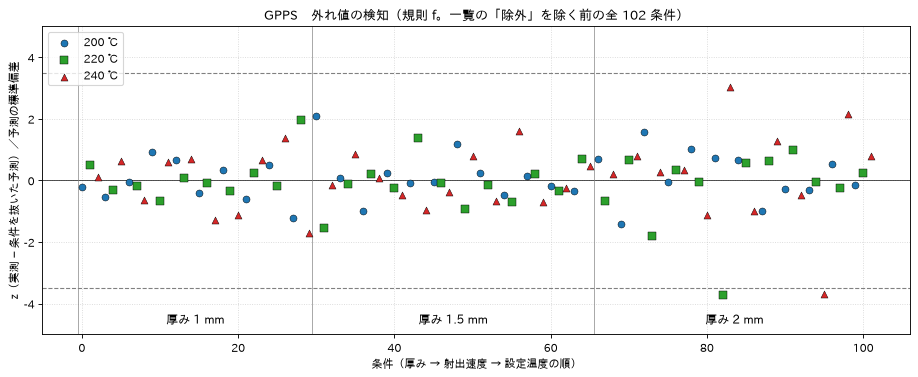

>> 判定：OK　[GPPS] （参考）規則 f で拾った条件：なし。この材料は参考表示だけで、一覧には登録しない
  問題の候補：6 件（一覧に未登録 6 件。規則ごと {'c 同じ条件内のばらつきが大きい': 6}）→ データ確認/問題の候補.csv


,材料,規則,組,設定温度,厚み,射出速度,ショット,内容,一覧の ID
0,GPPS,c 同じ条件内のばらつきが大きい,3data,200,1.0,280,,ln η の標準偏差 = 0.107（3 ショット）,
1,GPPS,c 同じ条件内のばらつきが大きい,5data,200,1.5,200,,ln η の標準偏差 = 0.115（5 ショット）,
2,GPPS,c 同じ条件内のばらつきが大きい,3data,200,1.5,280,,ln η の標準偏差 = 0.120（3 ショット）,
3,GPPS,c 同じ条件内のばらつきが大きい,3data,240,1.0,280,,ln η の標準偏差 = 0.111（3 ショット）,
4,GPPS,c 同じ条件内のばらつきが大きい,3data,240,1.0,320,,ln η の標準偏差 = 0.117（3 ショット）,
5,GPPS,c 同じ条件内のばらつきが大きい,5data,240,2.0,40,,ln η の標準偏差 = 0.103（5 ショット）,


In [54]:
# セル4：外れ値の検知（規則 f）と、問題の候補
PLIST = read_problem_list()
D_ALL = load_all(MATERIALS, exclude=False)            # 一覧の「除外」を除く前
for mat in MATERIALS:
    chk_dir = result_dir(mat, "データ確認")
    pool_all = pd.concat([D_ALL[(mat, "5data")], D_ALL[(mat, "3data")]], ignore_index=True)
    pool_ex = pd.concat([TRAIN[mat], TEST[mat]], ignore_index=True)
    f_all, f_ex = outlier_scan(pool_all), outlier_scan(pool_ex)
    ftab = pd.concat([f_all.assign(除外後に再計算=False), f_ex.assign(除外後に再計算=True)], ignore_index=True)
    ftab.insert(0, "材料", MAT_NAMES[mat])
    to_csv(ftab, os.path.join(chk_dir, "外れ値の検知_規則f.csv"))
    flag = ftab[ftab["flag"]].drop_duplicates(subset=["cond"]).copy()
    flag["一覧の ID"] = [registered(mat, r["grp"], {"Tset": r["Tset"], "H": r["H"], "v": r["v"]}, PLIST) for _, r in flag.iterrows()]
    cand = candidates(mat, pool_ex, PLIST)
    to_csv(cand, os.path.join(chk_dir, "問題の候補.csv"))
    # 図：条件ごとの z（除く前の全条件）
    order = f_all.sort_values(["H", "v", "Tset"]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 5))
    for t, (col, mk) in t_style(order["Tset"].unique()).items():
        m = (order["Tset"] == t).to_numpy()
        ax.scatter(np.flatnonzero(m), order.loc[m, "z"], color=col, marker=mk, s=40, edgecolors="k", linewidths=0.4, label=f"{int(t)} ℃", zorder=3)
    fl = order[order["flag"]]
    if len(fl):
        ax.scatter(fl.index, fl["z"], s=260, facecolors="none", edgecolors="red", linewidths=2, label="規則 f で拾った条件", zorder=4)
        for i, r in fl.iterrows():
            ax.annotate(f"{int(r['Tset'])} ℃・{r['H']:g} mm・{int(r['v'])} mm/s", (i, r["z"]), textcoords="offset points", xytext=(8, 4), fontsize=10, color="red")
    for z0 in (-OUTLIER_Z, OUTLIER_Z):
        ax.axhline(z0, color="gray", ls="--", lw=1)
    ax.axhline(0, color="k", lw=0.6)
    ymax = max(5.0, float(order["z"].abs().max()) * 1.1)
    for h, g in order.groupby("H"):
        ax.axvline(g.index.min() - 0.5, color="gray", lw=0.6)
        ax.text(g.index.to_numpy().mean(), -ymax * 0.93, f"厚み {h:g} mm", ha="center", fontsize=11)
    ax.set_ylim(-ymax, ymax)
    ax.set_xlabel("条件（厚み → 射出速度 → 設定温度の順）")
    ax.set_ylabel("z（実測 − 条件を抜いた予測）／予測の標準偏差")
    ax.set_title(f"{MAT_NAMES[mat]}　外れ値の検知（規則 f。一覧の「除外」を除く前の全 {len(order)} 条件）")
    ax.legend(loc="upper left", fontsize=10)
    ax.grid(True, ls=":", alpha=0.5)
    save_fig(fig, chk_dir, "外れ値の検知_規則f")
    txt = "、".join(f"{int(r['Tset'])} ℃・{r['H']:g} mm・{int(r['v'])} mm/s（{r['grp']}、z = {r['z']:.1f}、残差 {r['resid']:+.2f}、{r['一覧の ID'] or '未登録'}）" for _, r in flag.iterrows()) or "なし"
    unreg = flag[flag["一覧の ID"] == ""]
    if mat in OUTLIER_REGISTER:
        judge(len(unreg) == 0, f"規則 f（|z| > {OUTLIER_Z} かつ |残差| > {OUTLIER_RESID}）で拾った条件は、すべて問題データ一覧に登録済み：{txt}。未登録があれば、一覧に「除外」で登録して、最初から実行し直す（4 件以上なら相談）", mat, "外れ値")
    else:
        judge(len(flag) == 0, f"（参考）規則 f で拾った条件：{txt}。この材料は参考表示だけで、一覧には登録しない", mat, "外れ値")
    n_un = int((cand["一覧の ID"] == "").sum())
    print(f"  問題の候補：{len(cand)} 件（一覧に未登録 {n_un} 件。規則ごと {cand.groupby('規則').size().to_dict()}）→ データ確認/問題の候補.csv")
    if len(cand):
        display(cand[~cand["規則"].str.startswith("g")].head(20))

## 4. 参考：P3_3 の性質（リークの目安）

本体の検討では、粘度の算出式に入っている圧力（P3_1）を説明変数に入れると、GPR が「算出式」を覚えてしまう（**リーク**）ことが分かっている。P3_3 がそれに当たるかを確かめる。
- **算出式の圧力か**：見かけのせん断応力 η·γ̇ を、a·H·P3_3 ＋ b·H（スリットの式の形）で表したときの最大の相対誤差。算出式の圧力なら 0.1% 未満になる（P3_1 は 0.03%）。
- **線形回帰の検証 R²**：ln η を ln P3_3 と ln γ̇ で線形回帰（5data で当てはめ）したときの 3data の R²。ln γ̇ だけの場合と並べる。
- P3_1・P3_2 の列があれば、ln P3_3 との相関（P3_2：センサ4が最大値になった時刻のセンサ3の圧力）。

**判定**：算出式の誤差が 5% を超えれば、P3_3 は算出式の圧力ではない（OK）。ただし、P3_3 は流れの結果で、成形の前には分からない値であることに変わりはない。

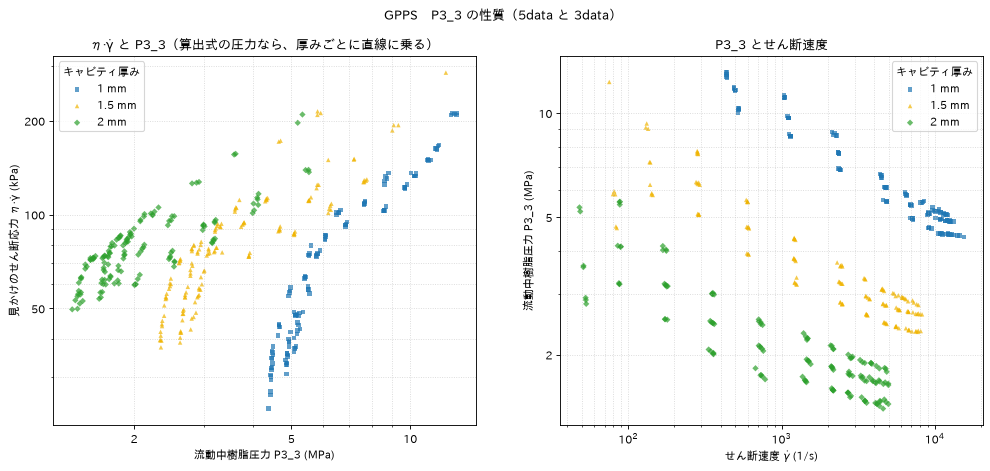

>> 判定：OK　[GPPS] P3_3 は粘度の算出式の圧力ではない（η·γ̇ = a·H·P3_3 + b·H で表すと、誤差が最大 166%。算出式の圧力なら 0.1% 未満）


,材料,算出式の形で表したときの最大誤差 [%],検証 R²（ln P3_3・ln γ̇）,"係数（ln P3_3, ln γ̇）",検証 R²（ln γ̇ だけ）
0,GPPS,166.4,0.9878,"(0.22, -1.20)",0.9874


In [55]:
# セル5：P3_3 の性質
rows = []
for mat in MATERIALS:
    chk_dir = result_dir(mat, "データ確認")
    pool = pd.concat([TRAIN[mat], TEST[mat]], ignore_index=True)
    tau = (pool["eta"] * pool["gd"]).to_numpy()                       # 見かけのせん断応力 [Pa]
    A = np.column_stack([pool["H"] * pool["P33"] * 1e6, pool["H"]])
    coef, *_ = np.linalg.lstsq(A, tau, rcond=None)
    rel = float(np.max(np.abs(A @ coef / tau - 1)))

    def r2_test(cols):
        Xtr = np.column_stack([np.ones(len(TRAIN[mat]))] + [TRAIN[mat][c] for c in cols])
        b, *_ = np.linalg.lstsq(Xtr, TRAIN[mat]["ln_eta"], rcond=None)
        Xte = np.column_stack([np.ones(len(TEST[mat]))] + [TEST[mat][c] for c in cols])
        return float(r2_score(TEST[mat]["ln_eta"], Xte @ b)), b

    r_pg, b_pg = r2_test(["ln_P33", "ln_gd"])
    r_g, _ = r2_test(["ln_gd"])
    row = {"材料": MAT_NAMES[mat], "算出式の形で表したときの最大誤差 [%]": round(rel * 100, 1),
           "検証 R²（ln P3_3・ln γ̇）": round(r_pg, 4), "係数（ln P3_3, ln γ̇）": f"({b_pg[1]:.2f}, {b_pg[2]:.2f})", "検証 R²（ln γ̇ だけ）": round(r_g, 4)}
    for c in ["P31", "P32"]:
        if c in pool.columns and pool[c].notna().all():
            row[f"相関 ln P3_3 と ln P3_{c[-1]}"] = round(float(np.corrcoef(pool["ln_P33"], np.log(pool[c]))[0, 1]), 3)
    rows.append(row)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for h in sorted(pool["H"].unique()):
        m = (pool["H"] == h).to_numpy()
        kw = dict(s=16, color=H_COLORS.get(h, "gray"), marker=H_MARKS.get(h, "o"), alpha=0.7, edgecolors="none", label=f"{h:g} mm")
        axes[0].scatter(pool.loc[m, "P33"], tau[m] / 1e3, **kw)
        axes[1].scatter(pool.loc[m, "gd"], pool.loc[m, "P33"], **kw)
    axes[0].set_xlabel("流動中樹脂圧力 P3_3 (MPa)")
    axes[0].set_ylabel("見かけのせん断応力 η·γ̇ (kPa)")
    axes[0].set_title("η·γ̇ と P3_3（算出式の圧力なら、厚みごとに直線に乗る）")
    axes[1].set_xlabel(r"せん断速度 $\dot{\gamma}$ (1/s)")
    axes[1].set_ylabel("流動中樹脂圧力 P3_3 (MPa)")
    axes[1].set_title("P3_3 とせん断速度")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_yscale("log")
        log_ticks(ax)                                 # 目盛りの数字が重ならないようにする
        ax.grid(True, which="both", ls=":", alpha=0.5)
        ax.legend(title="キャビティ厚み")
    fig.suptitle(f"{MAT_NAMES[mat]}　P3_3 の性質（5data と 3data）")
    save_fig(fig, chk_dir, "P3_3の性質")
    judge(rel > 0.05, f"P3_3 は粘度の算出式の圧力ではない（η·γ̇ = a·H·P3_3 + b·H で表すと、誤差が最大 {rel * 100:.0f}%。算出式の圧力なら 0.1% 未満）", mat, "P3_3")
P33_TAB = pd.DataFrame(rows)
display(P33_TAB)
for mat in MATERIALS:
    to_csv(P33_TAB[P33_TAB["材料"] == MAT_NAMES[mat]], os.path.join(result_dir(mat, "データ確認"), "P3_3の性質.csv"))

## 4b. 学習する厚み（設定 `THICKNESS`）

`THICKNESS = None`（既定）なら、何もしない（全厚みの 5data で学習する）。厚みの数（例：`0.5`）を書いたときは、**この後の学習・検証・図を、その厚みのデータだけで行う**（学習：その厚みの 5data、検証：同じ厚みの 3data）。ここまでのデータの確認（外れ値・P3_3 の性質）は、全厚みのデータで行った（データそのものの確認なので、厚みによらない）。
- 検証の行の「低速側」「高速側」は、その厚みの学習データの射出速度の範囲で分け直す（例：通常版の 0.5 mm・1.0 mm の検証は、高速側だけ）。
- その厚みのデータがない材料（例：GPPS の 0.5 mm）は、この回は学習しない（`MATERIALS` から外す）。
- 結果は `<版>/厚みごと/厚み<厚み>mm/<モデルのフォルダ>/`。選んだ厚みのデータの概要を、そこに `学習した厚みのデータの概要.csv` として保存する。
- 厚みごとの比較のノート（6 節・9 節）の「厚みごとのモデル」と同じ考え方で、このノートでは、95% 区間の延長と、最良の θ・θ = 0 の念入りな最適化も行う。

**判定**：その厚みの学習・検証とも、設定温度が 3 水準以上ある／その厚みの検証データに、学習データの射出速度の範囲の外の条件がある。

In [56]:
# セル5b：学習する厚みを選ぶ（設定 THICKNESS。None なら全厚みのまま）
THICK_ROWS = []
if THICKNESS is None:
    print(f"THICKNESS = None：全厚みのデータで学習する（結果は {'/'.join(THICK_PARTS)}/ の下）")
else:
    h0 = float(THICKNESS)
    skipped = []
    for mat in MATERIALS:
        tr = TRAIN[mat][np.isclose(TRAIN[mat]["H"], h0)].reset_index(drop=True)     # 行の番号は 0 から振り直す（カーネル行列の図などが、行の番号で並べ替えるため）
        te = TEST[mat][np.isclose(TEST[mat]["H"], h0)].reset_index(drop=True)
        if len(tr) == 0 or len(te) == 0:
            hs = "・".join(f"{h:g}" for h in sorted(TRAIN[mat]["H"].unique()))
            print(f"【{MAT_NAMES[mat]}】厚み {h0:g} mm のデータがない（学習 {len(tr)} 行・検証 {len(te)} 行。データのある厚み：{hs} mm）ので、この回は学習しない")
            skipped.append(mat)
            continue
        TRAIN[mat], TEST[mat] = tr, add_groups(tr, te)         # 低速側・高速側は、その厚みの学習データの射出速度の範囲で分け直す
        n_t = (TRAIN[mat]["Tset"].nunique(), TEST[mat]["Tset"].nunique())
        judge(min(n_t) >= 3, f"厚み {h0:g} mm の学習・検証とも、設定温度が 3 水準以上ある（学習 {n_t[0]}・検証 {n_t[1]} 水準）", mat, "厚み")
        judge((TEST[mat]["group"] != "範囲内").any(), f"厚み {h0:g} mm の検証データに、学習データの射出速度の範囲（{TRAIN[mat]['v'].min():g}〜{TRAIN[mat]['v'].max():g} mm/s）の外の条件がある", mat, "厚み")
        row = {"材料": MAT_NAMES[mat], "厚み [mm]": h0, "学習の行数": len(TRAIN[mat]), "学習の条件数": TRAIN[mat]["cond"].nunique(),
               "検証の行数": len(TEST[mat]), "検証の条件数": TEST[mat]["cond"].nunique(),
               **{f"検証の{g}の行数": int((TEST[mat]["group"] == g).sum()) for g in ["低速側", "高速側", "範囲内"]},
               "設定温度": "・".join(f"{t:g}" for t in sorted(TRAIN[mat]["Tset"].unique())),
               "射出速度（学習）": "・".join(f"{v:g}" for v in sorted(TRAIN[mat]["v"].unique())), "射出速度（検証）": "・".join(f"{v:g}" for v in sorted(TEST[mat]["v"].unique()))}
        THICK_ROWS.append(row)
        to_csv(pd.DataFrame([row]), os.path.join(out_dir(mat), "学習した厚みのデータの概要.csv"))
    MATERIALS = [m for m in MATERIALS if m not in skipped]     # この後のセルは、この材料だけを学習する
    assert MATERIALS, f"厚み {h0:g} mm のデータがある材料がない（THICKNESS か MATERIALS を見直す）"
    display(pd.DataFrame(THICK_ROWS))
    print(f"この後は、厚み {h0:g} mm のデータだけで学習・検証する（材料：{'・'.join(MAT_NAMES[m] for m in MATERIALS)}。結果は {'/'.join(THICK_PARTS)}/ の下）")

THICKNESS = None：全厚みのデータで学習する（結果は 全厚み総合/ の下）


## 5. 学習

### 5.1 プロファイル尤度（シフトファクター θ の推定。時間がかかる）

シフトのあるモデル（B_Tset_Arr・B_Tff_WLF など）では、θ = (θ_h, θ_v)（アレニウス型は E_h・E_v [kJ/mol]、WLF 型は A1_h・A1_v。A は θ_h = 0）の格子の各点で GPR を学習し、対数周辺尤度（LML）を求める。手順は次の 4 つ（2026-11-03 に 2〜4 を直した。シフトファクター検討用のノートと同じ）：
1. **粗い格子**（設定 `FORM_CFG` の、その型の範囲）で全体を見る。前の格子点の解を初期値にして、局所解でのがたつきを減らす。
2. **細かい格子**：最良の点を中心に、細かい格子（アレニウス型は B が `FINE_B`・A が `FINE_A`、WLF 型は `FORM_CFG` の `"fine"`）を取って計算する。新しい点は、**最良の点から外へ向かって**たどり、最良の点の解から始める。最良の点が動いたら（斜めの尾根の上では、細かい格子の端に当たることがある）、新しい最良の点を中心に取り直す（最大 `MAX_REFINE` 回）。
3. **見直し**：すべての点を、最良の点の解から最適化し直し、LML が上がった点は、その値に置き換える（格子の点が、ずれをノイズで片付ける「悪い解」〔LML が数十低い〕に止まると、95% 区間が狭く出たり、尤度の図ににせの崖が出たりするため）。上がった点の数は、表の `n_review_up`、格子の表の列 `review_gain` に出る。
4. **区間の延長**：おおよその 95% 区間（最大から 1.92 以内）の点の隣に、まだ計算していない点があれば、細かい格子の点を 1 列ずつ足し、区間の端が細かい格子の中で決まるまで続ける（最大 `MAX_EXTEND` 回。粗い格子の範囲の外には出ない）。

見直しか区間の延長で最良の点が動いたら、2 へ戻る。C（`SHIFT_COL = None`）では、θ がないので、この節は計算しない。

**θ = 0 の意味**：シフトなし、つまり B_Tset なら「Tset を使わないモデル」、B_Tff なら「Tff を使わないモデル」。最良の LML と θ = 0 の LML の差が、その温度を（シフトの形で）入れる効果を表す。差が **B は 3.0 以上、A は 1.92 以上**なら、足した係数の効果が、尤度比検定の 5% 基準（B は係数 2 つで 2·ΔLML > 5.99、A は係数 1 つで 2·ΔLML > 3.84）で認められる（A の基準は、2026-11-03 のユーザー決定で 3.0 から 1.92 に変えた）。

**尾根**：θ_h と θ_v は別々には決まりにくく、尤度の山が斜めの帯（尾根）になる。尾根に沿って尤度がほとんど変わらないので、個々の係数の 95% 区間は、計算した範囲に左右される。**差 θ_v − θ_h** が最もよく決まるので、表では、この差の範囲も示す。

**判定**：最良の θ が、粗い格子の端にも、細かい格子の端にもない（端なら `FORM_CFG` の、その型の範囲を広げる。取り直しが収束していなければ `MAX_REFINE` を増やす）。

### 5.1b 最良の θ と θ = 0 の、念入りな最適化

ハイパーパラメータ（振幅・長さスケール・線形項・ノイズ）の尤度の面には、**局所解が多い**。格子の各点では、最適化のやり直しが少ない（`PROFILE_RESTARTS`）ので、LML が 1〜3 ほど、局所解でずれることがある。そのまま「最良の点」と「θ = 0」の LML を比べると、**差がずれて見える**。そこで、**最良の θ と θ = 0 の 2 点だけ**を、最適化のやり直し `N_RESTARTS` 回で、念入りに学習し直し（並列。格子の解も初期値の 1 つにする）、格子の値と大きいほうを、格子の表に入れる。**θ = 0 との LML の差（ΔLML）と 95% 区間は、どちらもこの表から求める**（2026-11-03 から。それまでは、区間は格子の値から求めていて、ΔLML と食い違うことがあった）。最良の θ の学習が、そのまま最終モデルになる。

**判定**：ΔLML が基準以上（B は 3.0、A は 1.92。尤度比検定の 5% 基準。小さければ、温度の効果はほかの入力が担っている。そのときは、シフトファクター検討用のノートで、ほかの列や C と比べる）／95% 区間の端が、細かい格子の中で決まった（決まらなければ `MAX_EXTEND` を増やす。粗い格子の範囲の端に届いたら、`FORM_CFG` の範囲を広げる）。

In [57]:
# セル6：プロファイル尤度（目安：材料 1 つで 5〜10 分）
PROF, BEST = {}, {}
t_all = time.time()
for mat in MATERIALS:
    for key in SHIFT_KEYS:
        thn, tvn, un = theta_names(kcfg(mat, key))
        t0 = time.time()
        pts, conv = run_profile(key, TRAIN[mat], kcfg(mat, key))
        PROF[(mat, key)] = pts
        BEST[(mat, key)] = b = profile_best(pts, key, kcfg(mat, key), conv)
        to_csv(pts.drop(columns="theta"), os.path.join(out_dir(mat, key), "プロファイル尤度_格子.csv"))
        print(f"{MAT_NAMES[mat]} {key}：{len(pts)} 点（うち区間の延長 {int((pts['stage'] == '区間の延長').sum())} 点）、{time.time() - t0:.0f} 秒（細かい格子の取り直しが{'収束' if conv else '収束せず'}。"
              f"見直しで LML が上がった点 {b['n_review_up']}〔最大 +{b['review_gain_max']:.1f}〕）。最良 {thn} = {b['th_best']:g}、{tvn} = {b['tv_best']:g} {un}"
              f"（差 {tvn} − {thn} = {b['diff_best']:g}〔{b['diff_lo']:g}〜{b['diff_hi']:g}〕）、格子の LML {b['LML_best']:.1f}")
print(f"合計 {(time.time() - t_all) / 60:.1f} 分" + ("" if SHIFT_KEYS else "（シフトのあるモデルがないので、計算なし）"))
for mat in MATERIALS:
    for key in SHIFT_KEYS:
        thn, tvn, un = theta_names(kcfg(mat, key))
        b = BEST[(mat, key)]
        judge((not b["at_edge"]) and b["refine_converged"], f"{key}：最良の θ が、粗い格子の端にも、細かい格子の端にもない（{thn} = {b['th_best']:g}、{tvn} = {b['tv_best']:g} {un}。取り直しが{'収束' if b['refine_converged'] else '収束せず'}）。端なら FORM_CFG（型ごとの格子）の範囲を広げる。収束していなければ MAX_REFINE を増やす", mat, "尤度")

GPPS B_Tset_Arr：315 点（うち区間の延長 0 点）、246 秒（細かい格子の取り直しが収束。見直しで LML が上がった点 1〔最大 +0.7〕）。最良 E_h = 1、E_v = 9 kJ/mol（差 E_v − E_h = 8〔6〜10〕）、格子の LML 936.2
合計 4.1 分
>> 判定：OK　[GPPS] B_Tset_Arr：最良の θ が、粗い格子の端にも、細かい格子の端にもない（E_h = 1、E_v = 9 kJ/mol。取り直しが収束）。端なら FORM_CFG（型ごとの格子）の範囲を広げる。収束していなければ MAX_REFINE を増やす


In [58]:
# セル6b：最良の θ と θ = 0 の念入りな最適化（並列。目安：数分）
from joblib import Parallel, delayed
t0 = time.time()
FITS, ZERO, LOSS = {}, {}, {}
jobs = [(mat, key, kind) for mat in MATERIALS for key in SHIFT_KEYS for kind in ("best", "zero")]
res = Parallel(n_jobs=min(N_JOBS, len(jobs)))(
    delayed(fit_job)(key, TRAIN[mat], kcfg(mat, key), (BEST[(mat, key)]["th_best"] if kind == "best" else 0.0), (BEST[(mat, key)]["tv_best"] if kind == "best" else 0.0),
                     N_RESTARTS, (BEST[(mat, key)]["theta_best"] if kind == "best" else BEST[(mat, key)]["theta_zero"]), INPUT_MODE, kind == "best")
    for mat, key, kind in jobs) if jobs else []
for (mat, key, kind), f in zip(jobs, res):
    if kind == "best":
        FITS[(mat, key)] = f
        LOSS[(mat, key)] = f["loss_runs"]
    else:
        ZERO[(mat, key)] = f
print(f"念入りな最適化：{len(jobs)} 回、{(time.time() - t0) / 60:.1f} 分")
for mat in (MATERIALS if SHIFT_KEYS else []):       # シフトのあるモデルがなければ（C だけなら）、飛ばす
    for key in SHIFT_KEYS:                          # 念入りな最適化の LML を格子の表に入れ、ΔLML と 95% 区間を、どちらもその表から出し直す（2026-11-03）
        PROF[(mat, key)], BEST[(mat, key)] = profile_careful(PROF[(mat, key)], BEST[(mat, key)], key, kcfg(mat, key), FITS[(mat, key)], ZERO[(mat, key)])
        to_csv(PROF[(mat, key)].drop(columns="theta"), os.path.join(out_dir(mat, key), "プロファイル尤度_格子.csv"))
    t = pd.DataFrame([{"材料": MAT_NAMES[mat], "モデル": key, "入力": VERSION_DIRS[INPUT_MODE], "型": FORM_JA[kcfg(mat, key)["type"]],
                       "θ の名前": "・".join(theta_names(kcfg(mat, key))[:2]), "単位": theta_names(kcfg(mat, key))[2], "支持の基準": lrt_limit(key),
                       **{k: v for k, v in BEST[(mat, key)].items() if k not in ("theta_best", "theta_zero")}} for key in SHIFT_KEYS])
    to_csv(t, os.path.join(out_dir(mat), "シフトファクターの推定.csv"))
    display(t[["材料", "モデル", "型", "θ の名前", "単位", "th_best", "th_lo", "th_hi", "tv_best", "tv_lo", "tv_hi", "diff_best", "diff_lo", "diff_hi", "LML_best", "LML_at_0", "dLML_vs_0", "支持の基準",
               "dLML_vs_0_grid", "at_edge", "refine_converged", "interval_closed", "interval_at_range", "n_review_up"]].round(2))
    for key in SHIFT_KEYS:
        b = BEST[(mat, key)]
        thn, tvn, un = theta_names(kcfg(mat, key))
        other = "Tff・P3_3" if layout(key)[1] == "Tset" else "Tset・P3_3"
        lim = lrt_limit(key)
        span = (f"{thn} {b['th_lo']:g}〜{b['th_hi']:g}・" if key.startswith("B") else "") + f"{tvn} {b['tv_lo']:g}〜{b['tv_hi']:g} {un}"
        print(f"{MAT_NAMES[mat]} {key}：念入りな最適化の LML {b['LML_best']:.1f}（格子 {b['LML_best_grid']:.1f}）、θ = 0 は {b['LML_at_0']:.1f}（格子 {b['LML_at_0_grid']:.1f}）→ ΔLML {b['dLML_vs_0']:+.2f}（格子では {b['dLML_vs_0_grid']:+.2f}）。95% 区間 {span}")
        judge(b["dLML_vs_0"] >= lim, f"{key}：温度のシフトが尤度で支持される（念入りに最適化した LML が、θ = 0〔{key.split('_')[1]} を使わない〕より {b['dLML_vs_0']:.2f} 大きい。基準 {lim:g} 以上"
              f"＝尤度比検定の 5% 基準〔係数 {1 if key.startswith('A') else 2} つ〕）。小さければ、温度の効果はほかの入力（{other}）が担っている", mat, "尤度")
        judge(b["interval_closed"] and not b["interval_at_range"], f"{key}：95% 区間（{span}）の端が、細かい格子の中で決まった（区間の外側の隣の点まで計算した"
              f"{'' if b['interval_closed'] else '。★ 計算していない隣の点が残った：MAX_EXTEND を増やす'}{'。★ 粗い格子の範囲の端に届いた：FORM_CFG の範囲を広げる' if b['interval_at_range'] else ''}）", mat, "尤度")

念入りな最適化：2 回、1.0 分


,材料,モデル,型,θ の名前,単位,th_best,th_lo,th_hi,tv_best,tv_lo,tv_hi,diff_best,diff_lo,diff_hi,LML_best,LML_at_0,dLML_vs_0,支持の基準,dLML_vs_0_grid,at_edge,refine_converged,interval_closed,interval_at_range,n_review_up
0,GPPS,B_Tset_Arr,アレニウス型,E_h・E_v,kJ/mol,1.0,1.0,1.0,9.0,7.0,11.0,8.0,6.0,10.0,936.21,913.63,22.58,3.0,22.58,False,True,True,False,1


GPPS B_Tset_Arr：念入りな最適化の LML 936.2（格子 936.2）、θ = 0 は 913.6（格子 913.6）→ ΔLML +22.58（格子では +22.58）。95% 区間 E_h 1〜1・E_v 7〜11 kJ/mol
>> 判定：OK　[GPPS] B_Tset_Arr：温度のシフトが尤度で支持される（念入りに最適化した LML が、θ = 0〔Tset を使わない〕より 22.58 大きい。基準 3 以上＝尤度比検定の 5% 基準〔係数 2 つ〕）。小さければ、温度の効果はほかの入力（Tff・P3_3）が担っている
>> 判定：OK　[GPPS] B_Tset_Arr：95% 区間（E_h 1〜1・E_v 7〜11 kJ/mol）の端が、細かい格子の中で決まった（区間の外側の隣の点まで計算した）


**図の見方**（`プロファイル尤度.png`）：色は LML − 最大値（明るいほど尤度が高い）。赤線の内側が、おおよその 95% 区間（最大から 1.92 以内）。★ が最良の点、× が θ = 0（シフトなし）。帯が斜めに伸びるときは、θ_h と θ_v が別々には決まりにくく、差 θ_v − θ_h だけがよく決まる（本体の手順5a と同じ）。

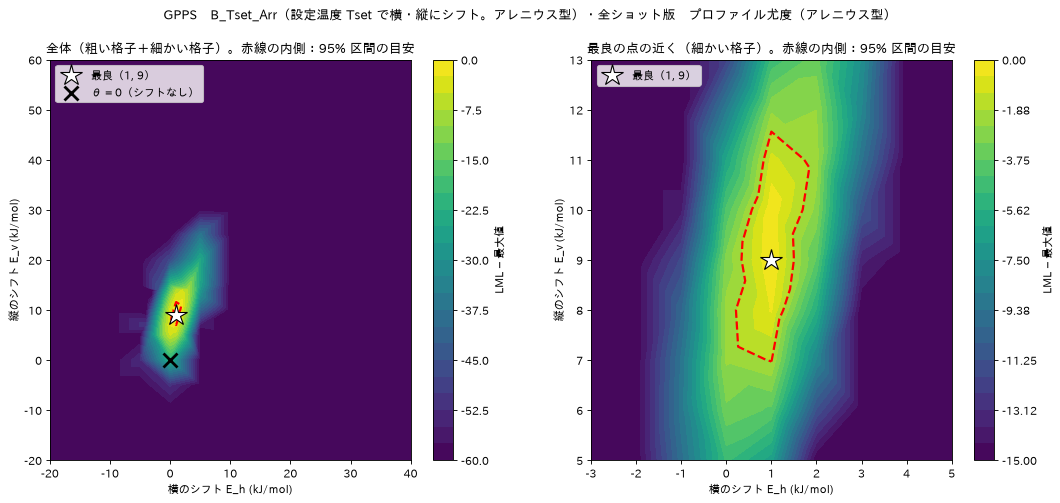

In [59]:
# セル7：尤度の面
for mat in MATERIALS:
    for key in SHIFT_KEYS:
        thn, tvn, un = theta_names(kcfg(mat, key))
        pts, b = PROF[(mat, key)], BEST[(mat, key)]
        val = (pts["LML"] - b["LML_best"]).to_numpy()
        if key.startswith("A"):
            fig, ax = plt.subplots(figsize=(9, 5.5))
            ax.plot(pts["tv"], val, "o-", color="#1f77b4")
            ax.axhline(-1.92, color="red", ls="--", label="最大 − 1.92（95% 区間の目安）")
            ax.axvline(0, color="k", lw=0.6)
            ax.set_xlabel(f"縦のシフト {tvn} ({un})")
            ax.set_ylabel("LML − 最大値")
            ax.set_ylim(max(val.min(), -60), 2)
            ax.legend()
            ax.grid(True, ls=":", alpha=0.5)
        else:
            fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
            rng = (kcfg(mat, key).get("fine") or FINE_B)[0]
            near = pts[pts["th"].between(b["th_best"] - rng, b["th_best"] + rng) & pts["tv"].between(b["tv_best"] - rng, b["tv_best"] + rng)]
            for ax, sub, lo, ttl in [(axes[0], pts, -60.0, "全体（粗い格子＋細かい格子）"), (axes[1], near, -15.0, "最良の点の近く（細かい格子）")]:
                v = np.maximum((sub["LML"] - b["LML_best"]).to_numpy(), lo)
                tri = mtri.Triangulation(sub["th"].to_numpy(), sub["tv"].to_numpy())
                cs = ax.tricontourf(tri, v, levels=np.linspace(lo, 0, 25), cmap="viridis")
                ax.tricontour(tri, v, levels=[-1.92], colors="red", linewidths=2)
                fig.colorbar(cs, ax=ax, label="LML − 最大値")
                ax.plot(b["th_best"], b["tv_best"], marker="*", color="white", ms=20, mec="k", ls="none", label=f"最良（{b['th_best']:g}, {b['tv_best']:g}）")
                if sub["th"].min() <= 0 <= sub["th"].max() and sub["tv"].min() <= 0 <= sub["tv"].max():
                    ax.plot(0, 0, marker="x", color="k", ms=12, mew=2.5, ls="none", label="θ = 0（シフトなし）")
                ax.set_xlabel(f"横のシフト {thn} ({un})")
                ax.set_ylabel(f"縦のシフト {tvn} ({un})")
                ax.set_title(f"{ttl}。赤線の内側：95% 区間の目安")
                ax.legend(loc="upper left", fontsize=10)
        fig.suptitle(f"{MAT_NAMES[mat]}　{model_title(key)}　プロファイル尤度（{FORM_JA[kcfg(mat, key)['type']]}）")
        save_fig(fig, out_dir(mat, key), "プロファイル尤度")

### 5.2 最終モデルの学習（6月のノートのセル5・6）

シフトのあるモデルは、5.1b の念入りな学習（最良の θ。最適化のやり直し `N_RESTARTS` 回）が、そのまま最終モデル。C（シフトなし）は θ がないので、ここで同じ回数で学習する。表は、学習したハイパーパラメータ（振幅、長さスケール、線形項、ノイズ）と対数周辺尤度（LML）。長さスケールが上限（100）に届いた入力は、粘度にほとんど効いていない（線形項が担う場合もある）。

**判定**：最終モデルの LML が、尤度の格子の最良以上／ノイズ分散が下限（`NOISE_LB`）に張り付いていない。

In [60]:
# セル8：最終モデルの学習（C。シフトのあるモデルは 5.1b で済み）
t0 = time.time()
NOSHIFT_KEYS = [k for k in KEYS if k not in SHIFT_KEYS]      # シフトのないモデル（C）
jobs = [(mat, key) for mat in MATERIALS for key in NOSHIFT_KEYS]
res = Parallel(n_jobs=min(N_JOBS, len(jobs)))(delayed(fit_job)(key, TRAIN[mat], kcfg(mat, key), 0.0, 0.0, N_RESTARTS, None, INPUT_MODE, True) for mat, key in jobs) if jobs else []
for (mat, key), f in zip(jobs, res):
    FITS[(mat, key)] = f
    LOSS[(mat, key)] = f["loss_runs"]
print(f"シフトのないモデルの学習：{len(jobs)} 回、{(time.time() - t0) / 60:.1f} 分")
KROWS = []
for mat in MATERIALS:
    for key in KEYS:
        f = FITS[(mat, key)]
        KROWS.append({"材料": MAT_NAMES[mat], **kernel_row(f)})
        print(f"{MAT_NAMES[mat]} {key}：{f['gp'].kernel_}")
KT = pd.DataFrame(KROWS)
display(KT.round(4))
for mat in MATERIALS:
    to_csv(KT[KT["材料"] == MAT_NAMES[mat]], os.path.join(out_dir(mat), "ハイパーパラメータ.csv"))
    for key in KEYS:
        r = KT[(KT["材料"] == MAT_NAMES[mat]) & (KT["model"] == key)].iloc[0]
        if key in SHIFT_KEYS:
            lb = BEST[(mat, key)]["LML_best"]
            judge(r["LML"] >= lb - 0.5, f"{key}：最終モデルの LML（{r['LML']:.1f}）が、尤度の格子の最良（{lb:.1f}）以上", mat, "学習")
        judge(not r["noise_at_lower_bound"], f"{key}：ノイズ分散（{r['noise_var']:.2e}）が下限 {NOISE_LB:g} に張り付いていない", mat, "学習")
        at = [c[3:] for c in KT.columns if c.startswith("ls_") and c != "ls_at_bound" and pd.notna(r[c]) and (r[c] > 99 or r[c] < 0.0105)]
        if at:
            print(f"  （参考）{MAT_NAMES[mat]} {key}：長さスケールが上限・下限に届いた入力：{'、'.join(at)}")

シフトのないモデルの学習：0 回、0.0 分
GPPS B_Tset_Arr：0.25**2 * Matern(length_scale=[0.221, 3.34, 12.8], nu=2.5) + 0.806**2 * DotProduct(sigma_0=3.95e-05) + WhiteKernel(noise_level=5.14e-05)


,材料,model,E_h,E_v,LML,amplitude,noise_var,noise_sd,noise_at_lower_bound,ls_at_bound,lin_amplitude,lin_sigma0,ls_ln γ̇ + ln a_h(Tset),ls_ln P3_3,ls_ln Tff
0,GPPS,B_Tset_Arr,1.0,9.0,936.2103,0.2502,0.0001,0.0072,False,False,0.8056,0.0,0.2212,3.3398,12.7939


>> 判定：OK　[GPPS] B_Tset_Arr：最終モデルの LML（936.2）が、尤度の格子の最良（936.2）以上
>> 判定：OK　[GPPS] B_Tset_Arr：ノイズ分散（5.14e-05）が下限 1e-06 に張り付いていない


### 5.3 損失関数の推移・特徴スケール・カーネル行列（6月のノートのセル7・7.5・8）

- **損失関数の推移**：負の対数周辺尤度（小さいほど良い）の、最適化のステップごとの値。青い太線が、最も良い解に着いた回（灰色は、ほかの初期値からの回）。
- **特徴スケール**：重要度 = 1 / 長さスケール（大きいほど、その入力の変化に粘度が敏感）。シフトのあるモデルでは、シフトに使った温度の効果は θ が担うので、ここには出ない。
- **カーネル行列**：学習データの点どうしの共分散（ノイズを除く）。並べる順を変えた 2 枚（左：設定温度 → 厚み → 射出速度、右：厚み → 設定温度 → 射出速度）。白線は、最初の量が変わる区切り。

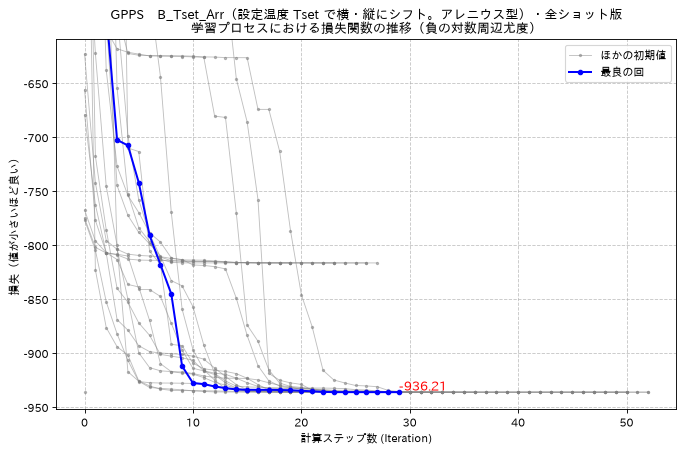

>> 判定：OK　[GPPS] 損失が減少して、学習が正常に進んだ（1 モデル）


In [61]:
# セル9：損失関数の推移（6月のノートのセル7）
for mat in MATERIALS:
    oks = []
    for key in KEYS:
        runs = [r for r in LOSS[(mat, key)] if len(r)]
        fig, ax = plt.subplots(figsize=(10, 6))
        if runs:
            best = int(np.argmin([r[-1] for r in runs]))
            for i, r in enumerate(runs):
                if i != best:
                    ax.plot(r, marker="o", ms=2, lw=0.8, color="gray", alpha=0.5, label="ほかの初期値" if i == (1 if best == 0 else 0) else None)
            rb = runs[best]
            ax.plot(rb, marker="o", ms=4, lw=1.8, color="blue", label="最良の回")
            ax.text(len(rb) - 1, rb[-1], f"{rb[-1]:.2f}", ha="left", va="bottom", color="red", fontsize=12)
            lo, hi = min(min(r) for r in runs), np.percentile(np.concatenate(runs), 90)
            ax.set_ylim(lo - 0.05 * (hi - lo + 1), hi + 0.05 * (hi - lo + 1))
            oks.append(rb[-1] <= rb[0])
        ax.set_title(f"{MAT_NAMES[mat]}　{model_title(key)}\n学習プロセスにおける損失関数の推移（負の対数周辺尤度）")
        ax.set_xlabel("計算ステップ数 (Iteration)")
        ax.set_ylabel("損失（値が小さいほど良い）")
        ax.grid(True, which="both", ls="--", alpha=0.7)
        ax.legend()
        save_fig(fig, out_dir(mat, key), "損失関数の推移", show=SHOW_FIGS and key == MAIN_KEY)
    judge(all(oks), f"損失が減少して、学習が正常に進んだ（{len(oks)} モデル）", mat, "学習")

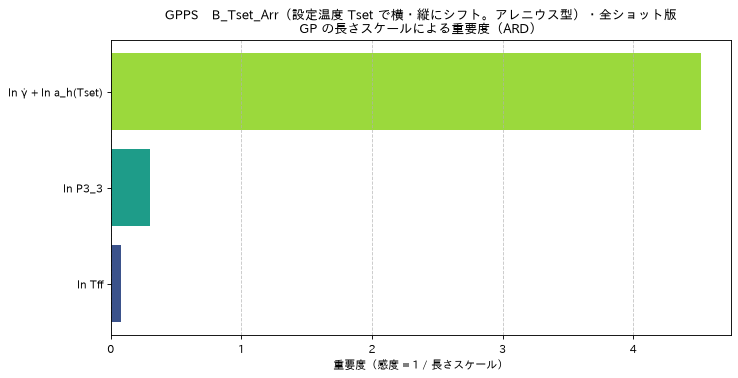

GPPS B_Tset_Arr：ln γ̇ + ln a_h(Tset) 0.221、ln P3_3 3.34、ln Tff 12.8（線形項の振幅 0.806）


In [62]:
# セル10：説明変数ごとの特徴スケール（6月のノートのセル7.5）
for mat in MATERIALS:
    for key in KEYS:
        prod, lin, _ = kernel_parts(FITS[(mat, key)]["gp"])
        ls = np.atleast_1d(prod.k2.length_scale)
        imp = pd.DataFrame({"説明変数": input_labels(key), "長さスケール": ls, "重要度（1/長さスケール）": 1.0 / ls}).sort_values("重要度（1/長さスケール）", ascending=False)
        fig, ax = plt.subplots(figsize=(10, 4.8))
        ax.barh(imp["説明変数"][::-1], imp["重要度（1/長さスケール）"][::-1], color=plt.cm.viridis(np.linspace(0.25, 0.85, len(imp))))
        ax.set_title(f"{MAT_NAMES[mat]}　{model_title(key)}\nGP の長さスケールによる重要度（ARD）")
        ax.set_xlabel("重要度（感度 = 1 / 長さスケール）")
        ax.grid(axis="x", ls="--", alpha=0.7)
        save_fig(fig, out_dir(mat, key), "特徴スケール", show=SHOW_FIGS and key == MAIN_KEY)
        print(f"{MAT_NAMES[mat]} {key}：" + "、".join(f"{r['説明変数']} {r['長さスケール']:.3g}" for _, r in imp.iterrows())
              + (f"（線形項の振幅 {np.sqrt(lin.k1.constant_value):.3g}）" if lin is not None else ""))

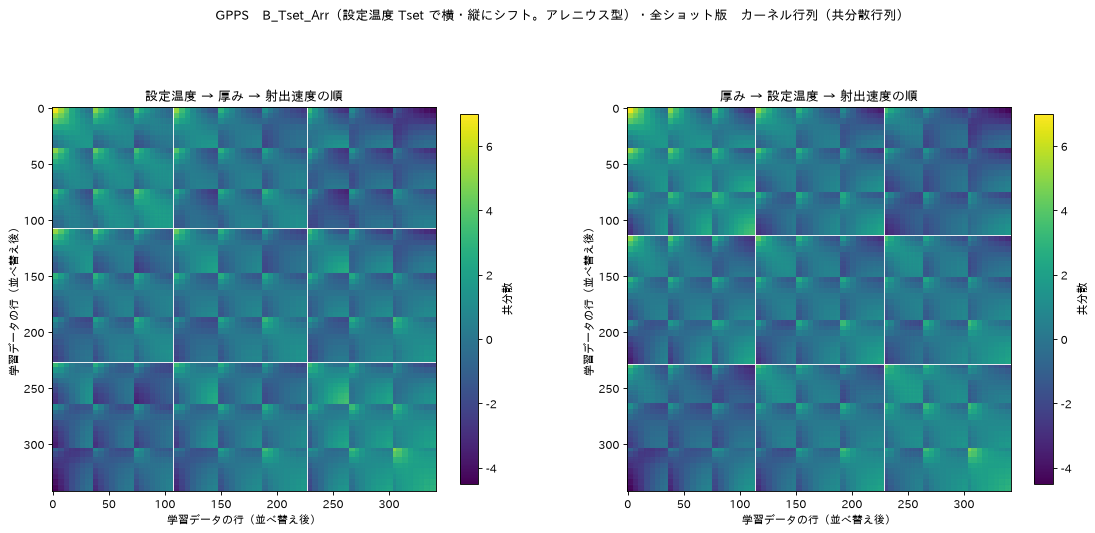

In [63]:
# セル11：カーネル行列のヒートマップ（6月のノートのセル8）
for mat in MATERIALS:
    tr = TRAIN[mat]
    for key in KEYS:
        f = FITS[(mat, key)]
        _, Xs, _ = design(tr, key, f["cfg"], f["th"], f["tv"], f["mode"])
        Xn = (Xs - f["mu_x"]) / f["sd_x"]
        fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
        for ax, cols, ttl in [(axes[0], ["Tset", "H", "v"], "設定温度 → 厚み → 射出速度の順"), (axes[1], ["H", "Tset", "v"], "厚み → 設定温度 → 射出速度の順")]:
            idx = tr.sort_values(cols + ["shot"]).index.to_numpy()
            K = f["gp"].kernel_.k1(Xn[idx])                          # ノイズを除いた共分散
            im = ax.imshow(K, cmap="viridis", interpolation="nearest")
            first = tr.loc[idx, cols[0]].to_numpy()
            for bb in np.flatnonzero(first[1:] != first[:-1]) + 0.5:
                ax.axhline(bb, color="w", lw=0.8)
                ax.axvline(bb, color="w", lw=0.8)
            ax.set_title(ttl)
            ax.set_xlabel("学習データの行（並べ替え後）")
            ax.set_ylabel("学習データの行（並べ替え後）")
            fig.colorbar(im, ax=ax, shrink=0.8, label="共分散")
        fig.suptitle(f"{MAT_NAMES[mat]}　{model_title(key)}　カーネル行列（共分散行列）")
        save_fig(fig, out_dir(mat, key), "カーネル行列", show=SHOW_FIGS and key == MAIN_KEY)

## 6. 温度のシフトファクターと、マスターカーブ

- **シフトファクターの図**（`シフトファクター.png`。C にはない）：左が横のシフト ln a_h(T)、右が縦のシフト ln a_v(T)。線が最良の θ、帯が尤度の 95% 区間（赤線の内側の θ の範囲）。点線は設定温度、薄い橙は Tff の範囲。B_Tset は設定温度、B_Tff は流動中樹脂温度で読む。ln a_v(T) > 0 は「その温度では、同じせん断速度で粘度が Tref より高い」。
- **マスターカーブ**（`マスターカーブ.png`）：条件平均の点を、最良の θ でずらしたもの（横：γ̇·a_h、縦：η/a_v）。温度のシフトが効いていれば、厚みごとに、温度の違う点が 1 本の曲線に近づく（シフト前は `流動曲線_シフト前.png`）。GP は、さらに P3_3 と、もう一方の温度でも補正する。
- **重ね合わせの残差**：厚みごとに、全温度の条件平均の点を 3 次式で当てはめた残差の RMSE（ln η）。シフト前より小さければ、シフトで曲線が重なった。

**判定**：縦のシフトの向きが「低温ほど粘い」（最も低い設定温度で ln a_v > 0）／重ね合わせの残差が、シフト前より小さい。

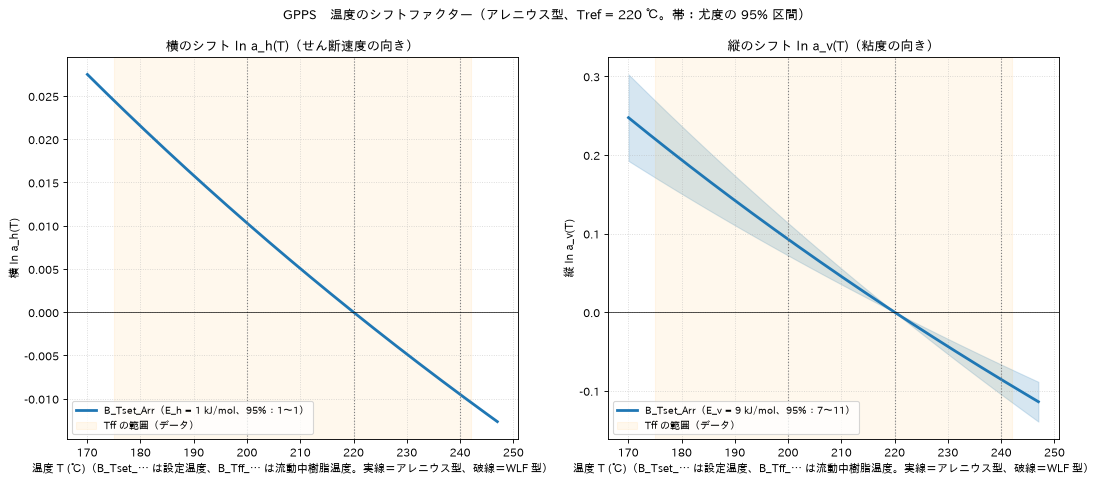

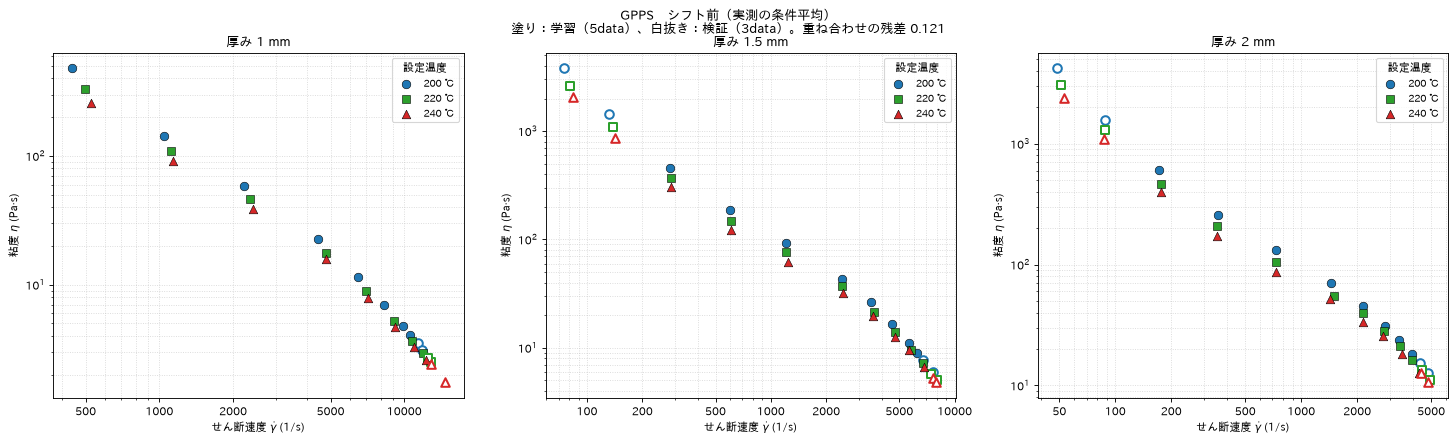

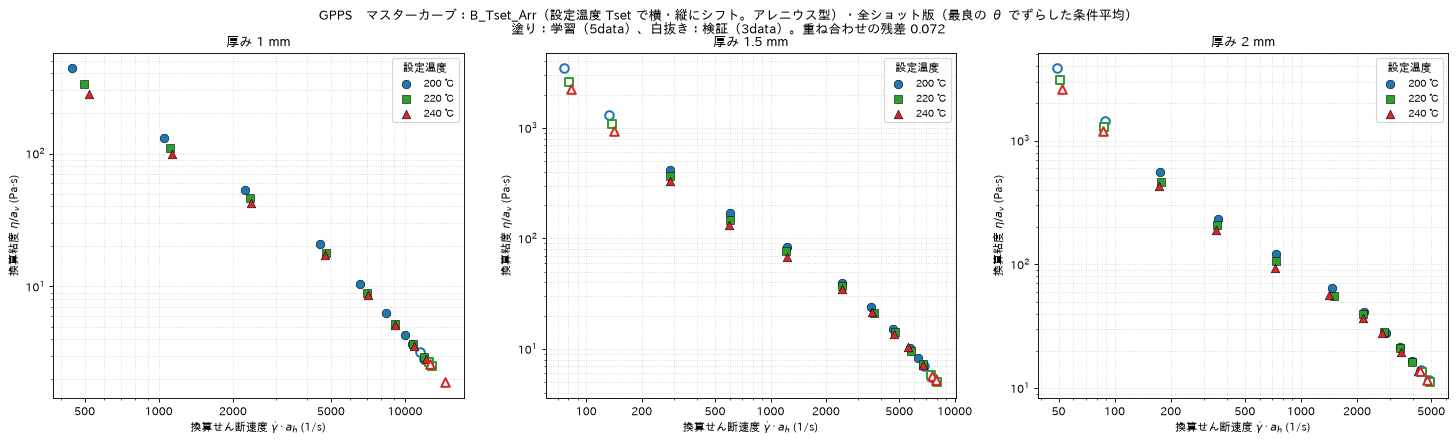

>> 判定：OK　[GPPS] B_Tset_Arr：縦のシフトの向きが「低温ほど粘い」（ln a_v(200 ℃) = +0.093。E_v = 9 kJ/mol）
>> 判定：OK　[GPPS] B_Tset_Arr：シフトで温度ごとの曲線が近づく（重ね合わせの残差 0.121 → 0.072）


,材料,モデル,型,Tref [℃],係数の名前,横の係数,縦の係数,単位,縦の倍率 a_v(200)/a_v(240),横の倍率 a_h(200)/a_h(240),重ね合わせの残差（シフト後）,重ね合わせの残差（シフト前）
0,GPPS,B_Tset_Arr,アレニウス型,220.0,E_h・E_v,1.0,9.0,kJ/mol,1.195,1.02,0.072,0.121


In [64]:
# セル12：シフトファクターとマスターカーブ
SHIFT_ROWS = []
for mat in MATERIALS:
    cfg0 = CFG[(mat, FORMS_USED[0])]                # 基準温度 Tref は、型によらず同じ
    pool = pd.concat([TRAIN[mat], TEST[mat]], ignore_index=True)
    train_c = set(TRAIN[mat]["cond"])
    tl, th_ = pool["Tset"].min(), pool["Tset"].max()
    if SHIFT_KEYS:                                  # シフトファクターの図（シフトのあるモデルがあるときだけ）
        Tg = np.linspace(min(pool["Tff"].min(), tl) - 5, max(pool["Tff"].max(), th_) + 5, 200)
        fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
        cols_ = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]
        for key, col in zip(SHIFT_KEYS, cols_ * 2):
            pts, b, cfg = PROF[(mat, key)], BEST[(mat, key)], kcfg(mat, key)
            thn, tvn, un = theta_names(cfg)
            inside = pts[pts["LML"] >= b["LML_best"] - 1.92]
            for ax, w, nm in [(axes[0], "th", thn), (axes[1], "tv", tvn)]:
                if w == "th" and key.startswith("A"):
                    continue
                cur = np.array([shift_ln(Tg, v, cfg) for v in inside[w]])
                ax.fill_between(Tg, cur.min(axis=0), cur.max(axis=0), color=col, alpha=0.18)
                ax.plot(Tg, shift_ln(Tg, b[f"{w}_best"], cfg), color=col, lw=2.5, ls="-" if cfg["type"] == "arrhenius" else "--",
                        label=f"{key}（{nm} = {b[f'{w}_best']:g} {un}、95%：{b[f'{w}_lo']:g}〜{b[f'{w}_hi']:g}）")
            SHIFT_ROWS.append({"材料": MAT_NAMES[mat], "モデル": key, "型": FORM_JA[cfg["type"]], "Tref [℃]": cfg["Tref"], "係数の名前": f"{thn}・{tvn}",
                               "横の係数": b["th_best"], "縦の係数": b["tv_best"], "単位": un,
                               f"縦の倍率 a_v({tl:g})/a_v({th_:g})": float(np.exp(shift_ln(tl, b["tv_best"], cfg) - shift_ln(th_, b["tv_best"], cfg))),
                               f"横の倍率 a_h({tl:g})/a_h({th_:g})": float(np.exp(shift_ln(tl, b["th_best"], cfg) - shift_ln(th_, b["th_best"], cfg)))})
        for ax, ttl in [(axes[0], "横のシフト ln a_h(T)（せん断速度の向き）"), (axes[1], "縦のシフト ln a_v(T)（粘度の向き）")]:
            for t in sorted(pool["Tset"].unique()):
                ax.axvline(t, color="gray", ls=":", lw=1)
            ax.axvspan(pool["Tff"].min(), pool["Tff"].max(), color="orange", alpha=0.07, label="Tff の範囲（データ）")
            ax.axhline(0, color="k", lw=0.6)
            ax.set_xlabel("温度 T (℃)（B_Tset_… は設定温度、B_Tff_… は流動中樹脂温度。実線＝アレニウス型、破線＝WLF 型）")
            ax.set_ylabel(ttl.split("（")[0].replace("のシフト ", " "))
            ax.set_title(ttl)
            ax.legend(fontsize=9, loc="best")
            ax.grid(True, ls=":", alpha=0.5)
        typ = "・".join(FORM_JA[f] + (f"〔D2 = Tg = {CFG[(mat, f)]['Tg']:g} ℃、A2 = {CFG[(mat, f)]['A2']:g} K〕" if f == "wlf" else "") for f in FORMS_USED)
        fig.suptitle(f"{MAT_NAMES[mat]}　温度のシフトファクター（{typ}、Tref = {cfg0['Tref']:g} ℃。帯：尤度の 95% 区間）")
        save_fig(fig, out_dir(mat), "シフトファクター")
    # マスターカーブ（シフト前と、モデルごと）
    Hs = sorted(pool["H"].unique())
    ncol = 2 if len(Hs) == 4 else len(Hs)
    nrow = int(np.ceil(len(Hs) / ncol))
    ts = t_style(pool["Tset"].unique())
    sup = {}
    for key in [None] + SHIFT_KEYS:
        b = BEST.get((mat, key), {"th_best": 0.0, "tv_best": 0.0})
        t = shifted_cond_means(pool, key, kcfg(mat, key) if key else cfg0, b["th_best"] if (key or "").startswith("B") else 0.0, b["tv_best"])
        sup[key] = superpose_rmse(t)
        fig, axes = plt.subplots(nrow, ncol, figsize=(7.5 * ncol, 5.6 * nrow), squeeze=False)
        for ax, h in zip(axes.flat, Hs):
            for tt, (col, mk) in ts.items():
                m = (t["H"] == h) & (t["Tset"] == tt)
                trm, tem = m & t["cond"].isin(train_c), m & ~t["cond"].isin(train_c)
                ax.scatter(np.exp(t.loc[trm, "x"]), np.exp(t.loc[trm, "y"]), color=col, marker=mk, s=60, edgecolors="k", linewidths=0.5, label=f"{int(tt)} ℃", zorder=3)
                ax.scatter(np.exp(t.loc[tem, "x"]), np.exp(t.loc[tem, "y"]), facecolors="white", edgecolors=col, marker=mk, s=60, linewidths=1.8, zorder=3)
            ax.set_xscale("log")
            ax.set_yscale("log")
            log_ticks(ax)
            ax.set_title(f"厚み {h:g} mm")
            ax.set_xlabel(r"せん断速度 $\dot{\gamma}$ (1/s)" if key is None else r"換算せん断速度 $\dot{\gamma}\cdot a_h$ (1/s)")
            ax.set_ylabel(r"粘度 $\eta$ (Pa·s)" if key is None else r"換算粘度 $\eta / a_v$ (Pa·s)")
            ax.grid(True, which="both", ls=":", alpha=0.5)
            ax.legend(fontsize=9, title="設定温度")
        for ax in list(axes.flat)[len(Hs):]:
            ax.axis("off")
        ttl = "シフト前（実測の条件平均）" if key is None else f"マスターカーブ：{model_title(key)}（最良の θ でずらした条件平均）"
        fig.suptitle(f"{MAT_NAMES[mat]}　{ttl}\n塗り：学習（5data）、白抜き：検証（3data）。重ね合わせの残差 {sup[key]:.3f}")
        save_fig(fig, out_dir(mat) if key is None else out_dir(mat, key), "流動曲線_シフト前" if key is None else "マスターカーブ",
                 show=SHOW_FIGS and key in (None, MAIN_KEY))
    for r in SHIFT_ROWS:
        if r["材料"] == MAT_NAMES[mat]:
            r["重ね合わせの残差（シフト後）"], r["重ね合わせの残差（シフト前）"] = sup[r["モデル"]], sup[None]
    for key in SHIFT_KEYS:
        b, cfg = BEST[(mat, key)], kcfg(mat, key)
        thn, tvn, un = theta_names(cfg)
        judge(shift_ln(tl, b["tv_best"], cfg) > 0, f"{key}：縦のシフトの向きが「低温ほど粘い」（ln a_v({tl:g} ℃) = {float(shift_ln(tl, b['tv_best'], cfg)):+.3f}。{tvn} = {b['tv_best']:g} {un}）", mat, "シフト")
        judge(sup[key] < sup[None], f"{key}：シフトで温度ごとの曲線が近づく（重ね合わせの残差 {sup[None]:.3f} → {sup[key]:.3f}）", mat, "シフト")
SHIFT_TAB = pd.DataFrame(SHIFT_ROWS)
display(SHIFT_TAB.round(3))
for mat in (MATERIALS if len(SHIFT_TAB) else []):   # シフトのあるモデルがなければ（C だけなら）、表はない
    to_csv(SHIFT_TAB[SHIFT_TAB["材料"] == MAT_NAMES[mat]].dropna(axis=1, how="all"), os.path.join(out_dir(mat), "シフトファクターの倍率.csv"))

## 7. 依存性グラフ（6月のノートのセル9・9-2）

1 つの説明変数だけを動かし、ほかは学習データの中央値（設定温度は Tref）に固定したときの、予測の平均（赤線）と 95% 予測区間（帯）。点は実測（5data と 3data。色は厚み）。ほかの変数を固定しているので、実際の成形では起こらない組み合わせも含む（例：せん断速度だけを大きくして、P3_3 は中央値のまま）。曲線は「その変数の効果の向きと大きさ」の目安として読む。

**温度の効果は 3 通りで見る**：Tset だけを動かす（Tff は固定。Tff を入力やシフトに使うモデルでは、設定温度を上げても、流動中樹脂温度は変わらないことになる）／Tff だけを動かす／**Tset と Tff を同時に動かす**（設定温度を上げると、流動中樹脂温度も同じだけ上がるとした。成形で起こることに近い）。判定には、同時に動かしたときの効果を使う。

**判定**：せん断速度を大きくすると粘度が下がる（ずり流動化）／Tset と Tff を同時に上げると粘度が下がる。Tset だけ・Tff だけを動かしたときの比は、参考として表示する。

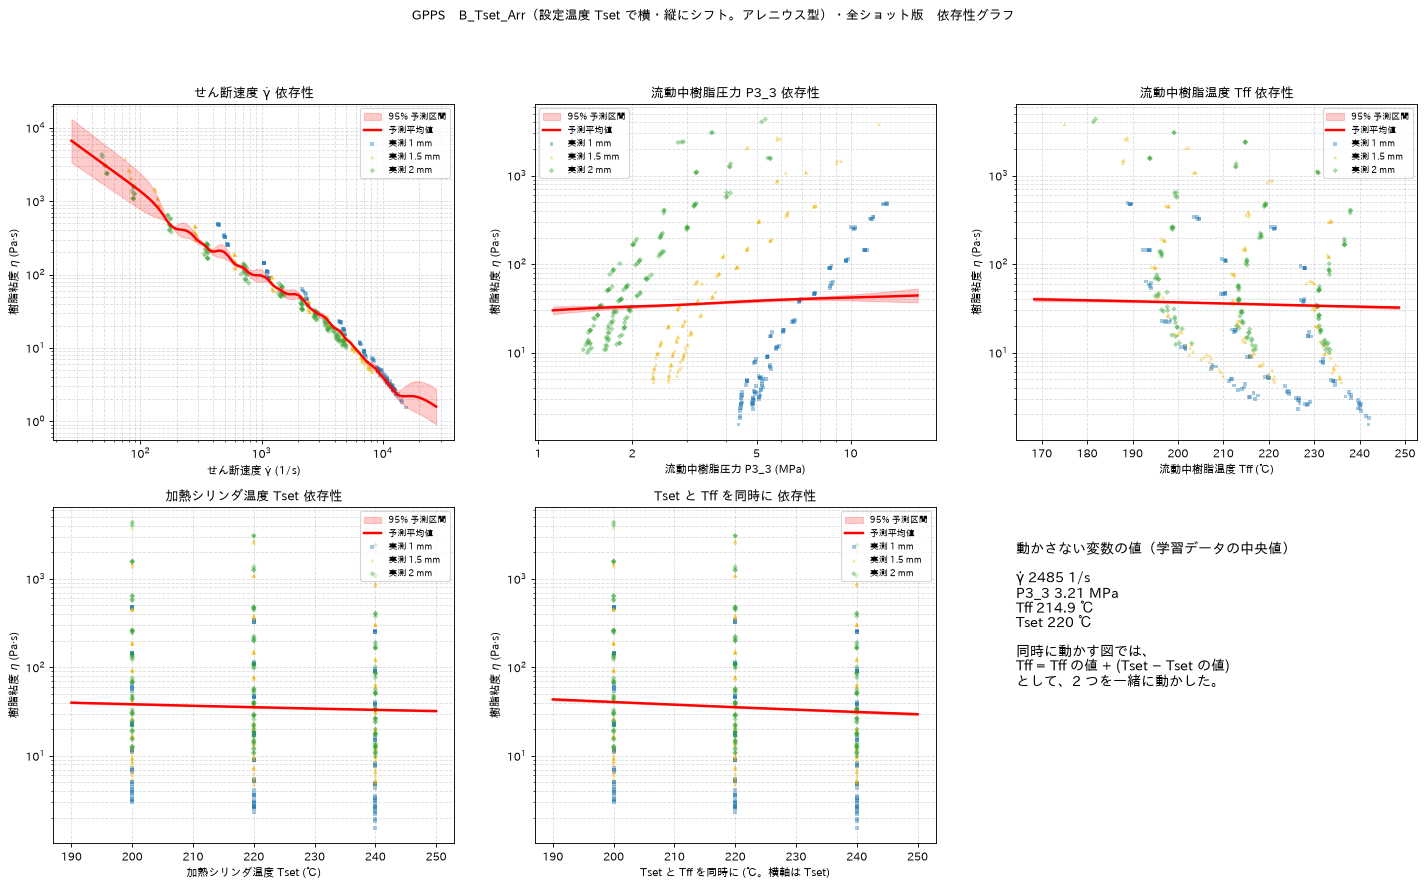

>> 判定：OK　[GPPS] せん断速度を大きくすると粘度が下がる（グラフの範囲の両端での粘度の比：B_Tset_Arr 4223.1 倍）
>> 判定：OK　[GPPS] Tset と Tff を同時に上げると粘度が下がる（η(200 ℃)/η(240 ℃)：B_Tset_Arr 1.294。γ̇・P3_3 は固定）
  （参考）Tset だけを動かしたときの η(200 ℃)/η(240 ℃)：B_Tset_Arr 1.156。Tff を入力やシフトに使うモデルでは、Tff が固定なので、設定温度の効果が小さく・逆向きに出ることがある


In [65]:
# セル13：依存性グラフ
DEP_VARS = ["gd", "P33", "Tff", "Tset", "Tboth"]
for mat in MATERIALS:
    tr, pool = TRAIN[mat], pd.concat([TRAIN[mat], TEST[mat]], ignore_index=True)
    base = base_point(tr, kcfg(mat, KEY))
    tl, th_ = pool["Tset"].min(), pool["Tset"].max()
    res_gd, res_both, res_only = [], [], []
    for key in KEYS:
        f = FITS[(mat, key)]
        fig, axes = plt.subplots(2, 3, figsize=(22, 12))
        for ax, var in zip(axes.flat, DEP_VARS):
            name, unit, logx = VAR_JA[var]
            g = var_grid(pool, var, 120)
            if var == "Tboth":      # 設定温度を上げると、流動中樹脂温度も同じだけ上がるとして、2 つを一緒に動かす
                X = model_inputs(**{**base, "Tset": g, "Tff": base["Tff"] + (g - base["Tset"])})
            else:
                X = model_inputs(**{**base, var: g})
            mu, sd, _, _ = predict(f, X)
            ax.fill_between(g, np.exp(mu - 1.96 * sd), np.exp(mu + 1.96 * sd), color="red", alpha=0.2, label="95% 予測区間", zorder=4)
            ax.plot(g, np.exp(mu), color="red", lw=2.2, label="予測平均値", zorder=5)
            xcol = "Tset" if var == "Tboth" else var
            for h in sorted(pool["H"].unique()):
                m = (pool["H"] == h).to_numpy()
                ax.scatter(pool.loc[m, xcol], pool.loc[m, "eta"], s=12, color=H_COLORS.get(h, "gray"), marker=H_MARKS.get(h, "o"), alpha=0.4, edgecolors="none", label=f"実測 {h:g} mm", zorder=2)
            if logx:
                ax.set_xscale("log")
            ax.set_yscale("log")
            log_ticks(ax, "xy" if logx else "y")
            ax.set_title(f"{name} 依存性")
            ax.set_xlabel(f"{name} {unit}")
            ax.set_ylabel(r"樹脂粘度 $\eta$ (Pa·s)")
            ax.grid(True, which="both", ls="--", alpha=0.4)
            ax.legend(fontsize=8, loc="best")
            if var == "gd":
                res_gd.append((key, float(np.exp(mu[0] - mu[-1]))))
            if var in ("Tset", "Tboth"):
                lo_i, hi_i = np.argmin(np.abs(g - tl)), np.argmin(np.abs(g - th_))
                (res_only if var == "Tset" else res_both).append((key, float(np.exp(mu[lo_i] - mu[hi_i]))))
        fixed = f"γ̇ {base['gd']:.0f} 1/s、P3_3 {base['P33']:.2f} MPa、Tff {base['Tff']:.1f} ℃、Tset {base['Tset']:g} ℃"
        axes.flat[5].axis("off")
        axes.flat[5].text(0.0, 0.9, "動かさない変数の値（学習データの中央値）\n\n" + fixed.replace("、", "\n") + "\n\n同時に動かす図では、\nTff = Tff の値 + (Tset − Tset の値)\nとして、2 つを一緒に動かした。",
                          va="top", fontsize=13)
        fig.suptitle(f"{MAT_NAMES[mat]}　{model_title(key)}　依存性グラフ")
        save_fig(fig, out_dir(mat, key), "依存性グラフ", show=SHOW_FIGS and key == MAIN_KEY)
    judge(all(r > 1 for _, r in res_gd), "せん断速度を大きくすると粘度が下がる（グラフの範囲の両端での粘度の比：" + "、".join(f"{k} {r:.1f} 倍" for k, r in res_gd) + "）", mat, "依存性")
    judge(all(r > 1 for _, r in res_both), f"Tset と Tff を同時に上げると粘度が下がる（η({tl:g} ℃)/η({th_:g} ℃)：" + "、".join(f"{k} {r:.3f}" for k, r in res_both) + "。γ̇・P3_3 は固定）", mat, "依存性")
    print(f"  （参考）Tset だけを動かしたときの η({tl:g} ℃)/η({th_:g} ℃)：" + "、".join(f"{k} {r:.3f}" for k, r in res_only) + "。Tff を入力やシフトに使うモデルでは、Tff が固定なので、設定温度の効果が小さく・逆向きに出ることがある")

## 8. 3data による予測検証（6月のノートのセル10）

5data で学習したモデルで、3data（射出速度の両端。低速側 3・5 mm/s、高速側 280・320 mm/s）を予測する。3data で測った P3_3・Tff を入力に使う。
- **指標**（ln η）：RMSE（小さいほど良い。0.1 は粘度で約 10%）、R²、95% 予測区間に入る割合（被覆率。0.95 に近いほど、予測のばらつきの見積もりが正しい）、NLPD（予測分布の当てはまり。小さいほど良い）。**R²（実数）**は、6月のノートと同じく粘度の実数値で計算した R²。
- **パリティ図**（`予測検証_3data_パリティ.png`）：横軸が実測、縦軸が予測の粘度。縦線が 95% 予測区間。破線（予測 = 実測）に近いほど良い。
- ほかのモデル（ほかの列のシフトや C）との比較は、シフトファクター検討用のノートで行う。
- **同じ形の図**（`予測検証_3data_パリティ_同じ形.png`。`VALID_SAME_SHAPE = True`）：低速側・高速側を区別せず、すべての点を同じ丸（`VALID_SAME_STYLE`。既定は黄緑の丸）で描いた図。区間の縦線も同じように描く。
- **パリティ図の見た目は、このセルの先頭の設定エリアで変えられる**（図の大きさ・解像度、文字の大きさ、範囲ごとの点の色と形、点の大きさ、区間の縦線の有無・色・太さ、軸の範囲、凡例の位置、タイトル・軸名、保存形式）。
  - **区間の縦線**：点の種類（低速側・高速側）によらず、同じ色（`VALID_ERR_COLOR`。既定は濃い灰色 `"0.3"`）・同じ太さ（`VALID_ERR_LINE`）で、点の後ろに描く。高速側は区間が狭く（上限/下限が 1.0〜1.5 倍ほど）、縦線が点より短いので、点に隠れて見えないことがある（描かれてはいる）。`VALID_ERR_ON_TOP = True` にすると、縦線を点の上に描く。
  - **点の色**（`VALID_POINT_COLOR`）：`True`＝色付き（今までどおり）、`False`＝色なし（塗りつぶし。低速側・高速側は点の形で見分ける）。塗りつぶしの色と濃さは `VALID_POINT_FILL`（既定は白）・`VALID_POINT_FILL_ALPHA`。
  - **点の枠線**：色付き・色なしとも、すべての点に枠線を付ける。太さは `VALID_POINT_EDGE`（既定 1.5 pt。0 で枠線なし）、色は `VALID_POINT_EDGE_COLOR`（既定は黒）。
  - **グラフエリアの縦横比**（`VALID_ASPECT`）：`"equal"`（既定）＝縦軸と横軸の 1 桁を同じ長さにする（両軸の範囲が同じなので正方形）、数＝縦 ÷ 横 の比（例：`0.75` で横長）、`None`＝図の大きさ（`VALID_FIGSIZE`）いっぱいに広げる。
  - **凡例を別の画像にする**（`VALID_LEGEND_SEPARATE = True`）：凡例をグラフに付けず、`予測検証_3data_パリティ_凡例.png` に保存する。既定は `False`（今までどおり、グラフの中に凡例。図の数は今までと同じ）。
  - **凡例の背景**：白の塗りつぶし（`VALID_LEGEND_FACE`。既定は白）で、不透明（`VALID_LEGEND_ALPHA = 1.0`。後ろの補助線が透けない）。
  - **目盛り線の向き**（`VALID_TICK_DIR`）：`"in"`（既定）＝グラフエリアの内側、`"out"`＝外側、`"inout"`＝両側。`VALID_TICK_MIRROR = True` で、上と右の辺にも目盛り線を付ける（セル16 の図と同じ）。
  - **グラフエリアだけの画像**（`VALID_AREA_ONLY = True`。既定）：それぞれの図について、グラフエリア（軸の枠の中。点・区間の縦線・破線・補助線・目盛り線）だけの画像 `予測検証_3data_パリティ_グラフエリアのみ.png`・`…_同じ形_グラフエリアのみ.png` も保存する。タイトル・軸名・凡例・目盛りの数字は付けない（`VALID_AREA_TICK_LABELS = True` で目盛りの数字を残す）。グラフエリアの大きさは通常の図と同じなので、資料で重ねて使える。凡例が要るときは `VALID_LEGEND_SEPARATE = True` で凡例だけの画像も作る。
  - 設定だけを直して、このセルだけを実行し直せる（学習はやり直さない）。そのときは、続けてセル15 も実行する（`予測検証_3data_指標.csv` に Cross-WLF の行を戻すため）。

**判定**：被覆率が 0.8 以上。


【GPPS】3data の ln η の RMSE


範囲,全体,低速側,高速側
モデル,,,
B_Tset_Arr,0.1213,0.1758,0.0668


95% 予測区間に入る割合（被覆率）


範囲,全体,低速側,高速側
モデル,,,
B_Tset_Arr,0.825,1.0,0.714


,モデル,R2,R2_real,NLPD,mean_sd,ノイズの標準偏差
0,B_Tset_Arr,0.9982,0.9673,-0.4837,0.1245,0.0072


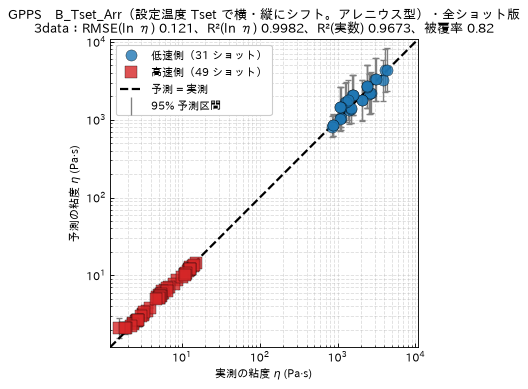

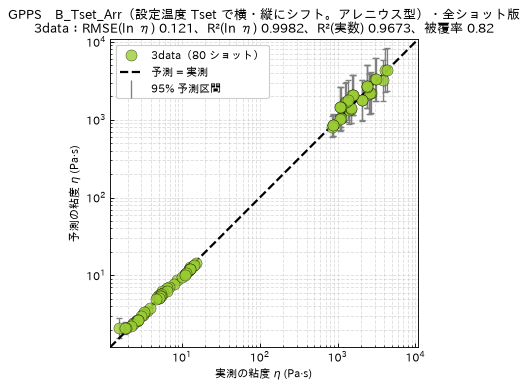

>> 判定：OK　[GPPS] 95% 予測区間に入る割合が、どのモデルも 0.8 以上（B_Tset_Arr 0.82）
保存したパリティ図：4 枚（凡例だけ・グラフエリアだけの画像を含む。モデルのフォルダの 予測検証_3data_パリティ.png・…_同じ形.png）


In [66]:
# セル14：3data による予測検証
# ==========================================
# ▼▼ 設定エリア（3data のパリティ図の見た目。このセルの設定だけを直して、このセルだけを実行し直せる） ▼▼
# ==========================================
VALID_FIGSIZE = (5, 5)            # 図の大きさ（幅, 高さ）[インチ]
VALID_ASPECT = "equal"              # グラフエリアの縦横比。"equal"＝縦軸と横軸の 1 桁を同じ長さにする（両軸の範囲が同じなので正方形。今まで）／数＝縦 ÷ 横 の比（例：0.75＝横長、1.2＝縦長）／None＝図の大きさいっぱいに広げる
VALID_DPI = None                    # 保存する画像の解像度（None なら FIG_DPI〔既定 600 dpi〕）
VALID_FONT = {"axis": 10, "legend": 10, "title": 12, "tick": 10}   # 軸名・凡例・タイトル・目盛り数字の文字サイズ
VALID_GROUPS = {"低速側": ("#1f77b4", "o"), "高速側": ("#d62728", "s"), "範囲内": ("#2ca02c", "^")}   # 3data の範囲ごとの（色, 点の形）。形は "o" 丸・"s" 四角・"^" 三角・"D" ひし形 など
VALID_MARKER = 10                   # 点の大きさ
VALID_ALPHA = 0.8                   # 点の塗りの濃さ（1 で不透明。色付きのときだけ。枠線は不透明のまま）
VALID_POINT_COLOR = True            # データ点に色を付けるか。True：色付き（今までどおり）／False：色なし（塗りつぶし〔VALID_POINT_FILL〕と枠線。低速側・高速側は点の形で見分ける）
VALID_POINT_EDGE = 0.3              # 点の枠線の太さ [pt]（色付き・色なしとも、すべての点に枠線を付ける。0 で枠線なし）
VALID_POINT_EDGE_COLOR = "black"    # 点の枠線の色
VALID_POINT_FILL = "white"          # 色なしのときの、点の塗りつぶしの色。"white"・"lightgray"・"0.8"（0＝黒〜1＝白の灰色）・"#ffe0e0" など
VALID_POINT_FILL_ALPHA = 1.0        # 色なしのときの、塗りつぶしの濃さ（0〜1。1 で不透明。枠線は不透明のまま）
VALID_ERRBAR = True                 # 95% 予測区間の縦線を描くか
VALID_ERR_COLOR = "0.5"             # 縦線の色（点の種類〔低速側・高速側〕によらず同じ色）。"0.3" は濃い灰色（0＝黒〜1＝白）。"black"・"red"・"#404040" なども書ける
VALID_ERR_LINE = 1.2                # 縦線と、端の横棒の太さ（点の種類によらず同じ太さ）
VALID_ERR_ALPHA = 1.0               # 縦線の濃さ（0〜1）
VALID_ERR_ON_TOP = False            # False：縦線を点の後ろに描く（区間が点より短い高速側では、縦線が点に隠れることがある）／True：点の上に描く
VALID_CAPSIZE = 3                   # 縦線の端の横棒の長さ（0 で横棒なし）
VALID_DIAG_LINE = 2.0               # 「予測 = 実測」の破線の太さ
VALID_LIM = None                    # 両軸（粘度 [Pa·s]）の範囲。(下限, 上限)＝固定（縦軸と横軸は同じ範囲）／None＝データと区間を含む範囲を VALID_MARGIN 倍に広げる
VALID_MARGIN = 1.3                  # 自動の範囲の、上下の余白の倍率
VALID_LEGEND_SEPARATE = False       # True：凡例をグラフに付けず、凡例だけを別の画像（予測検証_3data_パリティ_凡例.png）に保存する／False：グラフの中に凡例を付ける（今までどおり）
VALID_LEGEND_LOC = "upper left"     # 凡例の位置（グラフの中に付けるとき）。"upper left"・"lower right"・"best" など
VALID_LEGEND_FACE = "white"         # 凡例の背景の塗りつぶしの色。"white"・"0.9"（0＝黒〜1＝白の灰色）・"#fff8e0" など
VALID_LEGEND_ALPHA = 1.0            # 凡例の背景の濃さ（0〜1。1 で不透明＝後ろの補助線が透けない。matplotlib の既定は 0.8）
VALID_SHOW_TITLE = True             # タイトル（材料・モデル・3data の指標）を付けるか
VALID_SHOW_XLABEL = True            # 軸名を付けるか
VALID_SHOW_YLABEL = True
VALID_XLABEL = r"実測の粘度 $\eta$ (Pa·s)"   # 軸名の文字
VALID_YLABEL = r"予測の粘度 $\eta$ (Pa·s)"
VALID_GRID = True                   # 目盛りの補助線を描くか
VALID_TICK_DIR = "in"               # 軸の目盛り線の向き。"in"＝グラフエリアの内側／"out"＝外側（今まで）／"inout"＝両側
VALID_TICK_MIRROR = False           # True：上と右の辺にも目盛り線を付ける（セル16 の図と同じ）／False：下と左の辺だけ
VALID_FORMATS = ["png"]             # 保存形式。"png"・"pdf"・"svg" から選ぶ
VALID_AREA_ONLY = True              # True：グラフエリア（軸の枠の中）だけの画像（…_グラフエリアのみ.png。タイトル・軸名・凡例・目盛りの数字なし）も、それぞれの図について保存する
VALID_AREA_TICK_LABELS = False      # True：グラフエリアだけの画像にも、目盛りの数字を残す
VALID_SHOW_MODELS = [MAIN_KEY]      # 画面にも表示するモデル
VALID_SAME_SHAPE = True             # True：低速側・高速側を区別せず、すべての点を同じ形で描いた図（予測検証_3data_パリティ_同じ形.png）も作る
VALID_SAME_STYLE = ("yellowgreen", "o")   # その図の点の（色, 形）。"yellowgreen" は黄緑、"o" は丸。色なし（VALID_POINT_COLOR = False）のときは、色は使わず塗りつぶし〔VALID_POINT_FILL〕と枠線
VALID_SAME_LABEL = "3data"          # その図の凡例の点の名前
# ==========================================
val_kw = dict(figsize=VALID_FIGSIZE, aspect=VALID_ASPECT, dpi=VALID_DPI, font=VALID_FONT, groups=VALID_GROUPS, marker=VALID_MARKER, alpha=VALID_ALPHA, point_color=VALID_POINT_COLOR,
              point_edge=VALID_POINT_EDGE, point_edge_color=VALID_POINT_EDGE_COLOR, point_fill=VALID_POINT_FILL, point_fill_alpha=VALID_POINT_FILL_ALPHA, errbar=VALID_ERRBAR, err_color=VALID_ERR_COLOR,
              err_line=VALID_ERR_LINE, err_alpha=VALID_ERR_ALPHA, err_on_top=VALID_ERR_ON_TOP, capsize=VALID_CAPSIZE, diag_line=VALID_DIAG_LINE, lim=VALID_LIM,
              margin=VALID_MARGIN, legend_separate=VALID_LEGEND_SEPARATE, legend_loc=VALID_LEGEND_LOC, legend_face=VALID_LEGEND_FACE, legend_alpha=VALID_LEGEND_ALPHA,
              show_title=VALID_SHOW_TITLE, show_xlabel=VALID_SHOW_XLABEL, show_ylabel=VALID_SHOW_YLABEL, xlabel=VALID_XLABEL, ylabel=VALID_YLABEL, grid=VALID_GRID,
              tick_dir=VALID_TICK_DIR, tick_mirror=VALID_TICK_MIRROR, formats=VALID_FORMATS, area_only=VALID_AREA_ONLY, area_tick_labels=VALID_AREA_TICK_LABELS)
JUDGES[:] = [j for j in JUDGES if j["節"] != "検証"]     # このセルだけを実行し直したとき、判定が二重に記録されないように
PRED, MROWS = {}, []
for mat in MATERIALS:
    te = TEST[mat]
    for key in KEYS:
        mu, sd, sdf, nsd = predict(FITS[(mat, key)], te)
        PRED[(mat, key)] = te[["file", "cond", "Tset", "H", "v", "group", "eta", "gd", "P33", "Tff", "ln_eta"]].assign(
            予測_ln_eta=mu, 予測標準偏差=sd, 潜在関数の標準偏差=sdf, 予測η=np.exp(mu), 下限95=np.exp(mu - 1.96 * sd), 上限95=np.exp(mu + 1.96 * sd))
        to_csv(PRED[(mat, key)], os.path.join(out_dir(mat, key), "予測検証_3data_予測値.csv"))
        MROWS += metrics_rows(mat, key, te, mu, sd, sdf, {"ノイズの標準偏差": nsd})
MT = pd.DataFrame(MROWS)
n_val_saved = 0
for mat in MATERIALS:
    t = MT[MT["材料"] == MAT_NAMES[mat]]
    to_csv(t, os.path.join(out_dir(mat), "予測検証_3data_指標.csv"))
    print(f"\n【{MAT_NAMES[mat]}】3data の ln η の RMSE")
    display(t.pivot_table(index="モデル", columns="範囲", values="RMSE", sort=False).round(4))
    print("95% 予測区間に入る割合（被覆率）")
    display(t.pivot_table(index="モデル", columns="範囲", values="coverage95", sort=False).round(3))
    display(t[t["範囲"] == "全体"][["モデル", "R2", "R2_real", "NLPD", "mean_sd", "ノイズの標準偏差"]].round(4))
    for key in KEYS:
        r = t[(t["モデル"] == key) & (t["範囲"] == "全体")].iloc[0]
        title = f"{MAT_NAMES[mat]}　{model_title(key)}\n3data：RMSE(ln η) {r['RMSE']:.3f}、R²(ln η) {r['R2']:.4f}、R²(実数) {r['R2_real']:.4f}、被覆率 {r['coverage95']:.2f}"
        n_val_saved += len(parity_plot(PRED[(mat, key)], title, out_dir(mat, key), "予測検証_3data_パリティ", show=SHOW_FIGS and key in VALID_SHOW_MODELS, **val_kw))
        if VALID_SAME_SHAPE:    # 低速側・高速側を区別せず、すべての点を同じ形で描いた図
            n_val_saved += len(parity_plot(PRED[(mat, key)], title, out_dir(mat, key), "予測検証_3data_パリティ_同じ形", show=SHOW_FIGS and key in VALID_SHOW_MODELS,
                                           same_style=VALID_SAME_STYLE, same_label=VALID_SAME_LABEL, **val_kw))
    if "C" in KEYS:                                 # 基準の C（シフトなし）と比べる（C とシフトのあるモデルの両方を学習したとき）
        rc = float(t[(t["モデル"] == "C") & (t["範囲"] == "全体")]["RMSE"].iloc[0])
        for key in SHIFT_KEYS:
            rk = float(t[(t["モデル"] == key) & (t["範囲"] == "全体")]["RMSE"].iloc[0])
            judge(rk <= 1.1 * rc, f"{key} の 3data の RMSE（全体）{rk:.4f} が、C（{rc:.4f}）の 1.1 倍以内", mat, "検証")
    cov = t[t["範囲"] == "全体"].set_index("モデル")["coverage95"]
    judge(bool((cov >= 0.8).all()), "95% 予測区間に入る割合が、どのモデルも 0.8 以上（" + "、".join(f"{k} {v:.2f}" for k, v in cov.items()) + "）", mat, "検証")
print(f"保存したパリティ図：{n_val_saved} 枚（凡例だけ・グラフエリアだけの画像を含む。モデルのフォルダの 予測検証_3data_パリティ.png・…_同じ形.png）")

## 9. 参考：Cross-WLF との比較（6月のノートのセル10.5・11）

Cross-WLF 式（D3 = 0）：η0 = D1·exp(−A1(T − D2)/(A2 + T − D2))、η = η0 / (1 + (η0·γ̇/τ*)^(1−n))。設定 `CWLF_FIXED` で固定した係数以外を、5data に（ln η の最小二乗で）当てはめ、3data で評価する。温度 T は `CWLF_T`（既定は 6月と同じ流動中樹脂温度）。予測区間は、学習データの残差の標準偏差で付ける。

**図の見方**（`CrossWLFとの比較_パリティ.png`）：同じ 3data で、Cross-WLF（青）と GPR（このノートのモデル、赤）の予測を重ねる。`予測検証_RMSEの比較.png` は、このノートのモデルと Cross-WLF の RMSE を、全体・低速側・高速側で並べたもの。


【GPPS】Cross-WLF（温度 Tff）：n = 0.04185（探索）、tau_star = 4.869e+04（探索）、D1 = 1e+30（探索（範囲の端））、D2 = 373.1（固定）、A1 = 80（探索（範囲の端））、A2 = 51.6（固定）、学習の残差 0.353


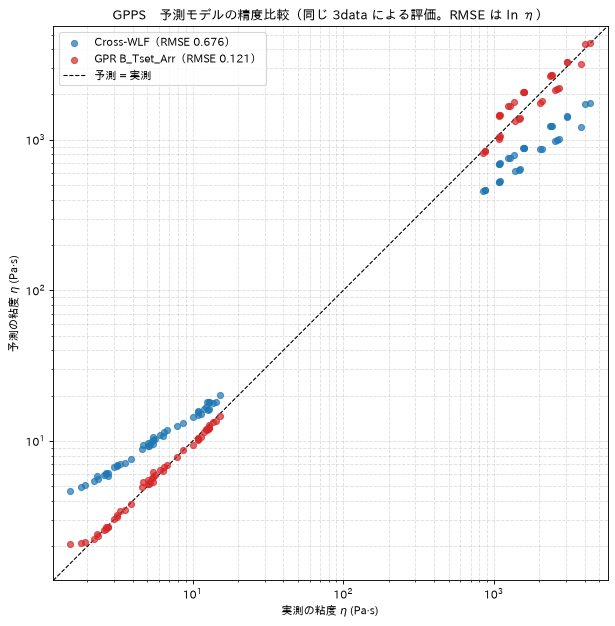

>> 判定：OK　[GPPS] （参考）GPR B_Tset_Arr の 3data の RMSE（0.121）が、Cross-WLF（0.676。温度 Tff）以下


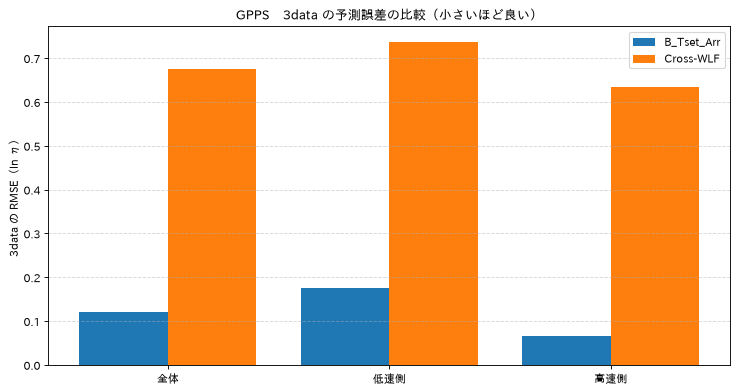

In [67]:
# セル15：Cross-WLF との比較
CW, CROWS = {}, []
for mat in MATERIALS:
    try:
        cw = fit_cross_wlf(TRAIN[mat], CWLF_T, CWLF_FIXED[mat])
    except Exception as e:
        print(f"{MAT_NAMES[mat]}：Cross-WLF の当てはめに失敗しました（{e}）。CWLF_FIXED の固定値を見直す")
        judge(False, f"Cross-WLF の当てはめに失敗（{e}）", mat, "Cross-WLF")
        continue
    CW[mat] = cw
    mu, sd = predict_cross_wlf(cw, TEST[mat])
    rows = metrics_rows(mat, "Cross-WLF", TEST[mat], mu, sd, np.full(len(mu), np.nan))
    CROWS += rows
    prm = pd.DataFrame([{"係数": k, "値": v, "扱い": ("探索（範囲の端）" if k in cw["at_bound"] else "探索") if k in cw["free"] else "固定"} for k, v in cw["params"].items()])
    to_csv(prm, os.path.join(out_dir(mat), "CrossWLF_係数.csv"))
    print(f"\n【{MAT_NAMES[mat]}】Cross-WLF（温度 {CWLF_T}）：" + "、".join(f"{r['係数']} = {r['値']:.4g}（{r['扱い']}）" for _, r in prm.iterrows()) + f"、学習の残差 {cw['resid_sd']:.3f}")
    p = PRED[(mat, MAIN_KEY)]
    r_cw = rows[0]["RMSE"]
    r_gp = float(MT[(MT["材料"] == MAT_NAMES[mat]) & (MT["モデル"] == MAIN_KEY) & (MT["範囲"] == "全体")]["RMSE"].iloc[0])
    fig, ax = plt.subplots(figsize=(9.5, 9))
    ax.scatter(TEST[mat]["eta"], np.exp(mu), color="#1f77b4", s=30, alpha=0.7, label=f"Cross-WLF（RMSE {r_cw:.3f}）", zorder=2)
    ax.scatter(p["eta"], p["予測η"], color="#d62728", s=30, alpha=0.7, label=f"GPR {MAIN_KEY}（RMSE {r_gp:.3f}）", zorder=3)
    lim = [min(TEST[mat]["eta"].min(), np.exp(mu).min(), p["予測η"].min()) / 1.3, max(TEST[mat]["eta"].max(), np.exp(mu).max(), p["予測η"].max()) * 1.3]
    ax.plot(lim, lim, "k--", lw=1, label="予測 = 実測")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    log_ticks(ax)
    ax.set_xlabel(r"実測の粘度 $\eta$ (Pa·s)")
    ax.set_ylabel(r"予測の粘度 $\eta$ (Pa·s)")
    ax.set_title(f"{MAT_NAMES[mat]}　予測モデルの精度比較（同じ 3data による評価。RMSE は ln η）")
    ax.grid(True, which="both", ls="--", alpha=0.4)
    ax.legend(loc="upper left")
    save_fig(fig, out_dir(mat), "CrossWLFとの比較_パリティ")
    judge(r_gp <= r_cw, f"（参考）GPR {MAIN_KEY} の 3data の RMSE（{r_gp:.3f}）が、Cross-WLF（{r_cw:.3f}。温度 {CWLF_T}）以下", mat, "Cross-WLF")
CT = pd.DataFrame(CROWS)
MT_ALL = pd.concat([MT, CT], ignore_index=True)
for mat in MATERIALS:
    t = MT_ALL[MT_ALL["材料"] == MAT_NAMES[mat]]
    to_csv(t, os.path.join(out_dir(mat), "予測検証_3data_指標.csv"))
    pv = t[~t["範囲"].str.contains("感度")].pivot_table(index="モデル", columns="範囲", values="RMSE", sort=False)
    fig, ax = plt.subplots(figsize=(11, 5.5))
    w = 0.8 / len(pv.index)
    for i, (k, row) in enumerate(pv.iterrows()):
        ax.bar(np.arange(len(pv.columns)) + i * w, row.to_numpy(), width=w, label=k)
    ax.set_xticks(np.arange(len(pv.columns)) + w * (len(pv.index) - 1) / 2)
    ax.set_xticklabels(pv.columns)
    ax.set_ylabel("3data の RMSE（ln η）")
    ax.set_title(f"{MAT_NAMES[mat]}　3data の予測誤差の比較（小さいほど良い）")
    ax.grid(axis="y", ls="--", alpha=0.5)
    ax.legend()
    save_fig(fig, out_dir(mat), "予測検証_RMSEの比較")

## 10. せん断速度 ― 粘度の学習結果グラフ（6月のノートのセル9-2 と同じ見せ方）

線は予測の平均、帯は 95% 区間、塗りつぶしの点は学習（5data）、白抜きの点は検証（3data）、× は問題データ一覧の「感度確認」の条件。点は、ショットごとの計測値（設定 `FLOW_POINTS = "cond"` にすると、条件平均の点になる）。予測線の P3_3・Tff は、同じ設定温度・厚みの条件平均（5data と 3data）を ln γ̇ で内挿した値（データの範囲の外は、端の値のまま）。
- **レイアウト**：`"temperature"`＝設定温度ごとに 1 枚（厚みごとの線。6月のノートと同じ）、`"thickness"`＝厚みごとに 1 枚（設定温度ごとの線）。
- **全厚み共通の図**（`FLOW_COMMON = True`）：①`…_全厚み共通_<温度>C.png`＝加熱シリンダ温度ごとに 1 枚。全キャビティ厚みの**学習データ**の点（色は厚み）を重ね、**厚みによらない共通の平均関数と 95% 区間**を 1 本描く（6月のセル9-2 と同じ見せ方。検証の点は描かない）。②`…_全厚み共通_全温度.png`＝①の曲線と帯を、**全温度を 1 枚に重ねて**、温度ごとに線・帯の色を変えた総合図（温度ごとの平均関数と予測幅を、1 つのグラフで比べられる。線・帯の色は、低い温度から**赤・青・緑**。点の色・形は厚み）。**グラフの画像には、タイトルも凡例も付けず**、凡例は別の画像（`…_全厚み共通_全温度_凡例.png`（日本語）と `…_全温度_凡例_English.png`（英語）。予測平均値_温度、95% 予測区間_温度、キャビティ厚み、固定した値）に保存する。図の大きさ（12 × 10 インチ。6月は 15 × 10）・文字・点の大きさ（300）・両軸の 10 の累乗の目盛りは、6月のセル9-2 と同じ。曲線は、せん断速度だけを動かし、P3_3 は学習データの中央値、Tff はその設定温度の学習データの中央値に固定したもの（温度ごとの図では図の右上の枠に、総合図では凡例の画像に、固定した値を書く）。厚みの違いは、P3_3・Tff の違いを通してしか入らないので、厚みごとの点は、共通の曲線の上下に散らばる。
- `THICKNESS` で厚みを選んだときは、厚みが 1 つなので、全厚み共通の図は既定では作らない（`FLOW_COMMON = True` にすれば作れる）。
- **凡例を別の画像にする**（`FLOW_LEGEND_SEPARATE = True`。既定）：このセルで作る**すべての図**で、グラフ本体には凡例を付けず、凡例だけを `<図の名前>_凡例.png` に保存する（全厚み共通の温度ごとの図の「固定した値」も、凡例の画像に書く。タイトルは `FLOW_SHOW_TITLE` のとおり）。`False` にすると、今までどおりグラフの中に凡例を付ける。
- **点の色**（`FLOW_POINT_COLOR`）：`True`＝色付き（今までどおり）、`False`＝色なし（**塗りつぶしと黒い枠線**。検証〔3data〕の点は灰色の枠線。厚み・温度は点の形で見分ける）。塗りつぶしの色は `FLOW_POINT_FILL`（既定は白。`"lightgray"`・`"0.8"`〔0＝黒〜1＝白の灰色〕・`"#ffe0e0"` など）、塗りつぶしの濃さは `FLOW_POINT_FILL_ALPHA`（0〜1。既定 1＝不透明。小さくすると、点の後ろの予測線・帯が透けて見える）。予測線と帯の色は変わらない。
- **点の枠線の太さ**（`FLOW_POINT_EDGE`）：数を書くと、色付き・色なしとも、すべての点（学習・検証、全厚み共通の図の点）の枠線がその太さ [pt] になる（0 で枠線なし）。`None`（既定）なら今までどおり（色付き：学習 0.6・検証 2.5・全厚み共通の図 0.5、色なし：1.5）。予測線の太さは `FLOW_LINE`。
- 保存先は、モデルのフォルダの中の `せん断速度_粘度/`（図は 600 dpi）。
- **このセルの先頭の設定エリアだけを直して、このセルだけを実行し直せる**（全体を一度実行した後で。学習はやり直さない）。

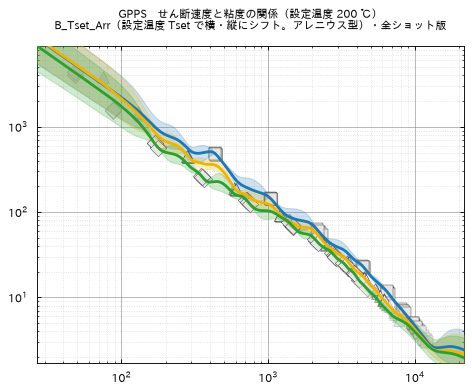

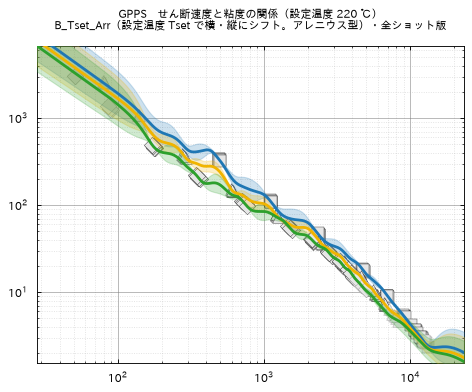

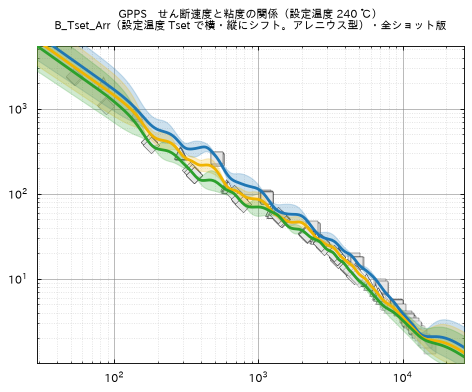

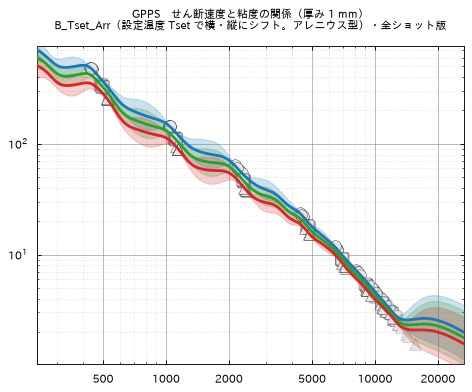

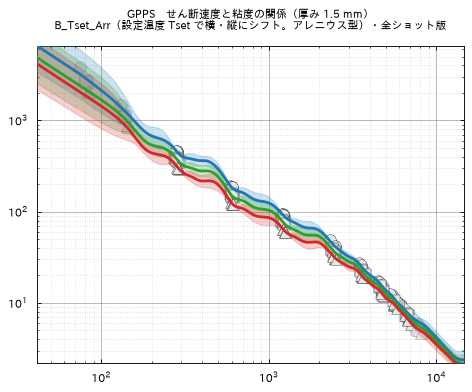

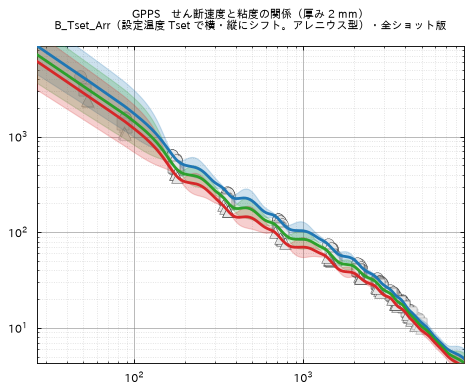

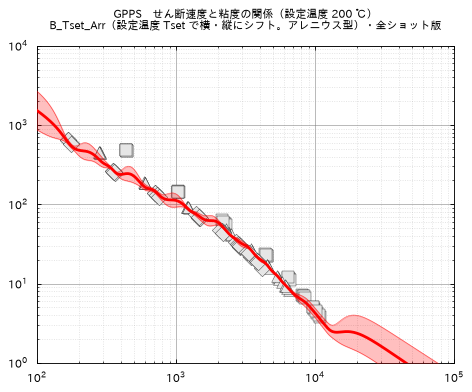

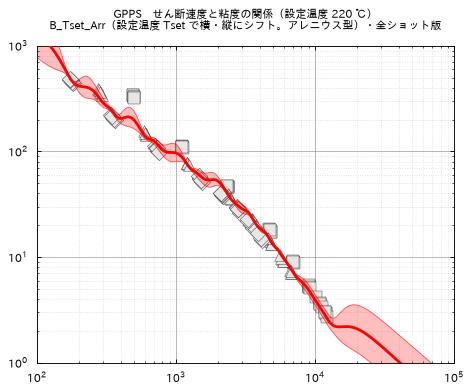

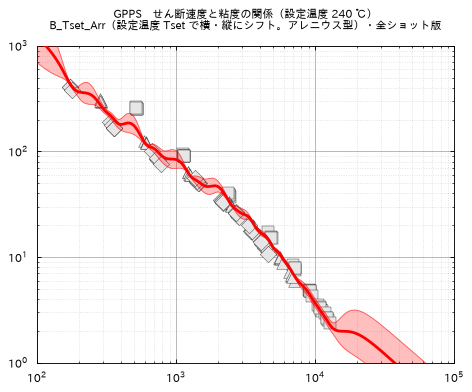

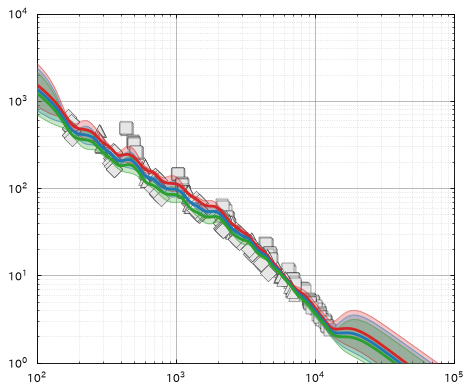

保存した図：42 枚（凡例だけの画像を含む。モデルのフォルダの せん断速度_粘度/ と せん断速度_粘度_拡張版/）


In [68]:
# セル16：せん断速度 ― 粘度の学習結果グラフ
# ==========================================
# ▼▼ 設定エリア（グラフの見た目。このセルの設定だけを直して、このセルだけを実行し直せる） ▼▼
# ==========================================
FLOW_MODELS = KEYS                  # 描くモデル（このノートで学習したモデル）
FLOW_MATERIALS = MATERIALS          # 描く材料
FLOW_LAYOUTS = ["temperature", "thickness"]   # "temperature"：設定温度ごとに 1 枚（厚みごとの線）／"thickness"：厚みごとに 1 枚（設定温度ごとの線）
FLOW_COMMON = THICKNESS is None     # True：全厚み共通の図も作る。加熱シリンダ温度ごとに 1 枚（…_全厚み共通_<温度>C.png）と、全温度を 1 枚に重ねた総合図（…_全厚み共通_全温度.png。温度ごとに色分け）。検証（3data）の点は描かない。既定は、全厚みで学習したときだけ True（THICKNESS で厚みを選んだときは、厚みが 1 つなので作らない。True にすれば作れる。図の名前は「全厚み共通」のまま）
FLOW_COMMON_XLIM = None                  # 全厚み共通の図の横軸（せん断速度 [1/s]）の範囲。(下限, 上限)＝固定／None＝データを含む 10 の累乗の範囲（目盛りは、6月のセル9-2 と同じ 10 の累乗）
FLOW_COMMON_YLIM = None                    # 同じ、縦軸（粘度 [Pa·s]）の範囲。例：(0.1, 10000)
FLOW_COMMON_NCOL = 1                # 総合図の凡例の列数（凡例が大きくて点に重なるときは 2 にする）
FLOW_BAND = "predict"               # 帯："predict"＝95% 予測区間（ショット間のばらつき込み）／"latent"＝95% 信頼区間（平均の不確かさだけ）／None＝帯なし
FLOW_POINTS = "shot"                # 点："shot"＝ショットごとの計測値（既定。10-26 に変更）／"cond"＝条件平均
FLOW_SHOW_TEST = True               # 検証（3data）の点を、白抜きで重ねるか
FLOW_MARK_SENS = True               # 問題データ一覧の「感度確認」の条件を、× で重ねるか
FLOW_X_RANGE = None                 # 軸の範囲を自動で決めるときの目安 [1/s]（予測線の範囲。None なら、各線のデータの範囲を FLOW_EXTEND 倍）。予測線と帯は、どの場合も、グラフエリアの端（軸の範囲。FLOW_XLIM・FLOW_COMMON_XLIM で変えても追従）まで描く
FLOW_EXTEND = 1.3                  # 自動の軸の範囲を決めるときの、データの範囲の延長の倍率
FLOW_XLIM = {"temperature": None, "thickness": None}   # 横軸（せん断速度 [1/s]）の範囲。(下限, 上限)＝固定（10 の累乗の目盛り）／None＝その図のデータに合わせる（目盛りは、範囲が 2.5 桁以下なら 1・2・5 × 10ⁿ、それより広いか、目盛りの数字が重なるなら 10 の累乗。10-26）
FLOW_YLIM = {"temperature": None, "thickness": None}   # 縦軸（粘度 [Pa·s]）の範囲。同じ書き方
FLOW_FIGSIZE = (6, 5)             # 図の大きさ（幅, 高さ）[インチ]（6月は 15 × 10。10-15 に 12 × 10 へ変更）
FLOW_DPI = None                     # 保存する PNG の解像度（None なら FIG_DPI〔既定 600 dpi〕）
FLOW_FONT = {"axis": 15, "legend": 10, "title": 10, "tick": 10}   # 軸名・凡例・タイトル・目盛り数字の文字サイズ（6月のセル9-2 と同じ）
FLOW_MARKER = 100                   # 点の大きさ（条件平均のとき。面積）
FLOW_MARKER_SHOT = 110               # 点の大きさ（ショットごとのとき）
FLOW_LINE = 2.5                     # 予測線の太さ
FLOW_POINT_COLOR = False             # データ点に色を付けるか。True：色付き（今までどおり）／False：色なし（塗りつぶし〔FLOW_POINT_FILL〕と黒い枠線。検証〔3data〕の点は灰色の枠線。点の形で厚み・温度を見分ける）
FLOW_POINT_EDGE = 0.3              # 点の枠線の太さ [pt]。数なら、色付き・色なしとも、すべての点（学習・検証）をその太さにする（0 で枠線なし）／None＝今までどおり（色付き：学習 0.6・検証 2.5・全厚み共通の図 0.5、色なし：1.5）
FLOW_POINT_FILL = "0.9"               # 色なしのときの、点の塗りつぶしの色。"white"（既定）・"lightgray"・"0.8"（0＝黒〜1＝白の灰色）・"#ffe0e0" など
FLOW_POINT_FILL_ALPHA = 1.0         # 色なしのときの、塗りつぶしの濃さ（0〜1。1 で不透明。小さくすると点の後ろの予測線・帯が透ける。枠線は不透明のまま）
FLOW_LEGEND_SEPARATE = True         # True：凡例をグラフ本体に付けず、凡例だけを別の画像（<図の名前>_凡例.png）に保存する（全厚み共通の温度ごとの図の「固定した値」も、凡例の画像に書く）／False：グラフの中に凡例を付ける（総合図〔…_全温度〕は、どちらでも凡例を別の画像にする）
FLOW_SHOW_TITLE = True              # タイトルを付けるか
FLOW_SHOW_XLABEL = False            # 軸名を付けるか（6月のノートと同じく、既定は付けない）
FLOW_SHOW_YLABEL = False
FLOW_FORMATS = ["png"]              # 保存形式。"png"・"pdf"・"svg" から選ぶ
FLOW_SHOW_MODELS = [MAIN_KEY]       # 画面にも表示するモデル（全部表示すると重い）
FLOW_EXTENDED = True                # True：軸の範囲を広げた拡張版（せん断速度_粘度_拡張版/ フォルダ。ここまでの設定はそのまま使う）も作る
FLOW_EXT_XLIM = (1.0e2, 1.0e5)          # 拡張版の横軸（せん断速度 [1/s]）の範囲。予測線と帯は、この範囲いっぱいに描く
FLOW_EXT_YLIM = (0.5, 1000.0)         # 拡張版の縦軸（粘度 [Pa·s]）の範囲
# ==========================================
n_saved = 0
pt_kw = dict(point_color=FLOW_POINT_COLOR, point_edge=FLOW_POINT_EDGE, point_fill=FLOW_POINT_FILL, point_fill_alpha=FLOW_POINT_FILL_ALPHA,
             legend_separate=FLOW_LEGEND_SEPARATE)   # 点の色・枠線・塗りつぶしと、凡例を別の画像にするか（すべての図で共通）
for mat in FLOW_MATERIALS:
    pool = pd.concat([TRAIN[mat], TEST[mat]], ignore_index=True)
    train_c = set(TRAIN[mat]["cond"])
    for key in FLOW_MODELS:
        saved = flow_plot(FITS[(mat, key)], mat, pool, train_c, out_dir(mat, key, "せん断速度_粘度"), "せん断速度_粘度",
                          layouts=FLOW_LAYOUTS, band=FLOW_BAND, points=FLOW_POINTS, show_test=FLOW_SHOW_TEST, mark_sens=FLOW_MARK_SENS,
                          x_range=FLOW_X_RANGE, extend=FLOW_EXTEND, xlim=FLOW_XLIM, ylim=FLOW_YLIM, figsize=FLOW_FIGSIZE, dpi=FLOW_DPI, font=FLOW_FONT,
                          marker=FLOW_MARKER, marker_shot=FLOW_MARKER_SHOT, line=FLOW_LINE, show_title=FLOW_SHOW_TITLE, show_xlabel=FLOW_SHOW_XLABEL,
                          show_ylabel=FLOW_SHOW_YLABEL, formats=FLOW_FORMATS, show=SHOW_FIGS and key in FLOW_SHOW_MODELS, **pt_kw)
        n_saved += len(saved)
        if FLOW_COMMON:        # 加熱シリンダ温度ごとに、全厚みの点を重ね、厚みによらない共通の平均関数と区間を 1 本描く（6月のセル9-2 と同じ）
            saved = flow_plot_common(FITS[(mat, key)], mat, pool, train_c, out_dir(mat, key, "せん断速度_粘度"), "せん断速度_粘度", tr=TRAIN[mat],
                                     band=FLOW_BAND, points=FLOW_POINTS, common_xlim=FLOW_COMMON_XLIM, common_ylim=FLOW_COMMON_YLIM, legend_ncol=FLOW_COMMON_NCOL, x_range=FLOW_X_RANGE, extend=FLOW_EXTEND, figsize=FLOW_FIGSIZE, dpi=FLOW_DPI,
                                     font=FLOW_FONT, marker=FLOW_MARKER, marker_shot=FLOW_MARKER_SHOT, line=FLOW_LINE, show_title=FLOW_SHOW_TITLE,
                                     show_xlabel=FLOW_SHOW_XLABEL, show_ylabel=FLOW_SHOW_YLABEL, formats=FLOW_FORMATS, show=SHOW_FIGS and key in FLOW_SHOW_MODELS, **pt_kw)
            n_saved += len(saved)
        if FLOW_EXTENDED:      # 拡張版：軸の範囲だけを変えて、同じ図（厚みごと・設定温度ごと・全厚み共通・総合）を別フォルダに保存する
            ext_dir = out_dir(mat, key, "せん断速度_粘度_拡張版")
            ext_kw = dict(band=FLOW_BAND, points=FLOW_POINTS, x_range=FLOW_X_RANGE, extend=FLOW_EXTEND, figsize=FLOW_FIGSIZE, dpi=FLOW_DPI, font=FLOW_FONT, marker=FLOW_MARKER,
                          marker_shot=FLOW_MARKER_SHOT, line=FLOW_LINE, show_title=FLOW_SHOW_TITLE, show_xlabel=FLOW_SHOW_XLABEL, show_ylabel=FLOW_SHOW_YLABEL, formats=FLOW_FORMATS, show=False, **pt_kw)
            saved = flow_plot(FITS[(mat, key)], mat, pool, train_c, ext_dir, "せん断速度_粘度_拡張版", layouts=FLOW_LAYOUTS, show_test=FLOW_SHOW_TEST, mark_sens=FLOW_MARK_SENS,
                              xlim={"thickness": FLOW_EXT_XLIM, "temperature": FLOW_EXT_XLIM}, ylim={"thickness": FLOW_EXT_YLIM, "temperature": FLOW_EXT_YLIM}, **ext_kw)
            n_saved += len(saved)
            if FLOW_COMMON:
                saved = flow_plot_common(FITS[(mat, key)], mat, pool, train_c, ext_dir, "せん断速度_粘度_拡張版", tr=TRAIN[mat], common_xlim=FLOW_EXT_XLIM, common_ylim=FLOW_EXT_YLIM,
                                         legend_ncol=FLOW_COMMON_NCOL, **ext_kw)
                n_saved += len(saved)
print(f"保存した図：{n_saved} 枚（凡例だけの画像を含む。モデルのフォルダの せん断速度_粘度/ と せん断速度_粘度_拡張版/）")

### 10.2 6月のセル9-2 と全く同じ図（目的変数に対する各説明変数の依存性）

6月のノートのセル9-2 と同じ図を、**学習データ（5data）の全ショットの点**と学習済みモデルで作る。説明変数（せん断速度・P3_3・Tff・Tset）ごとに 1 枚。その変数だけを動かし、ほかは**学習データの平均**（対数の変数は、対数の平均）に固定した、予測平均（赤線）と 95% 区間（帯。6月と同じく、ノイズを含む予測区間）。点の色・形は厚み。大きさ（12 × 10 インチ。6月は 15 × 10）、文字、点（300）、10 の累乗の目盛り、凡例、タイトルは、6月と同じ。保存先は、モデルのフォルダの中の `依存性グラフ_セル9-2/`。**このセルの先頭の設定だけを直して、このセルだけを実行し直せる**。固定した値と軸の範囲を変えられる。

In [69]:
# セル16-2：6月のセル9-2 と同じ依存性グラフ
# ==========================================
# ▼▼ 設定エリア（6月のセル9-2 と同じ） ▼▼
# ==========================================
DEP92_MODELS = KEYS                       # 描くモデル
DEP92_MATERIALS = MATERIALS               # 描く材料
DEP92_FIGSIZE = (12, 10)                  # 図の大きさ [インチ]
DEP92_DPI = None                          # PNG の解像度（None なら FIG_DPI〔既定 600 dpi〕）
DEP92_FONT = dict(axis_fs=24, legend_fs=24, title_fs=24, tick_fs=28)     # 軸名・凡例・タイトル・目盛りの文字の大きさ
DEP92_MARKER = dict(plot_marker=300, legend_marker=300)                  # 点の大きさ（グラフ上・凡例内）
DEP92_YLIM = (0.1, 10000.0)               # 粘度の軸の範囲 [Pa·s]（None なら自動）
DEP92_XLIM = {"gd": (10.0, 100000.0)}     # 横軸の範囲：変数（"gd"・"P33"・"Tff"・"Tset"）→ (下限, 上限)。書かない変数は、データの範囲の両側に 10% 広げる
DEP92_SHOW_XLABEL, DEP92_SHOW_YLABEL = False, False   # 軸名を付けるか（6月と同じ：付けない）
# ==========================================
n92 = 0
for mat in DEP92_MATERIALS:
    for key in DEP92_MODELS:
        n92 += len(dependency_plots_92(FITS[(mat, key)], mat, TRAIN[mat], out_dir(mat, key, "依存性グラフ_セル9-2"), figsize=DEP92_FIGSIZE, dpi=DEP92_DPI,
                                       ylim=DEP92_YLIM, xlim=DEP92_XLIM, show_xlabel=DEP92_SHOW_XLABEL, show_ylabel=DEP92_SHOW_YLABEL, show=False, **DEP92_FONT, **DEP92_MARKER))
print(f"保存した図：{n92} 枚（モデルのフォルダの 依存性グラフ_セル9-2/）")

保存した図：4 枚（モデルのフォルダの 依存性グラフ_セル9-2/）


## 11. 3次元グラフ（6月のノートのセル12〜15）

2 つの説明変数を動かし、ほかは学習データの中央値（設定温度は Tref）に固定したときの、予測の粘度（log10）の曲面。保存先は、モデルのフォルダの中の `3次元グラフ/`。**このセルの先頭の設定エリアだけを直して、このセルだけを実行し直せる**。

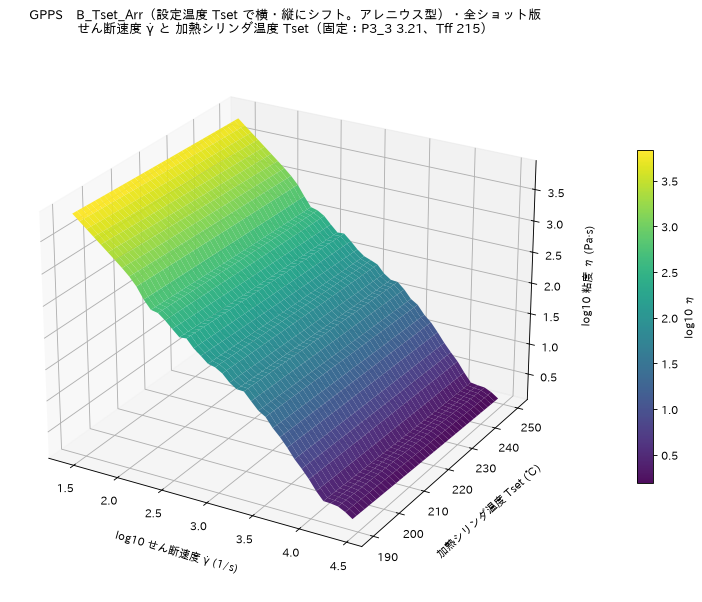

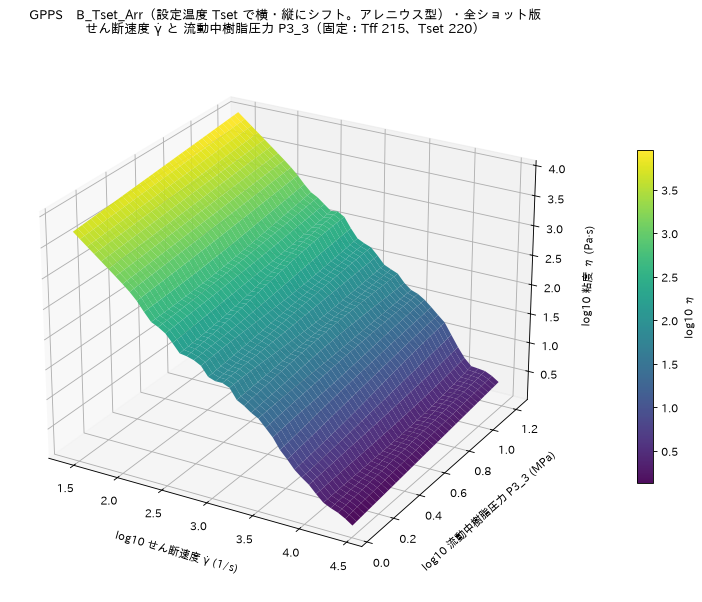

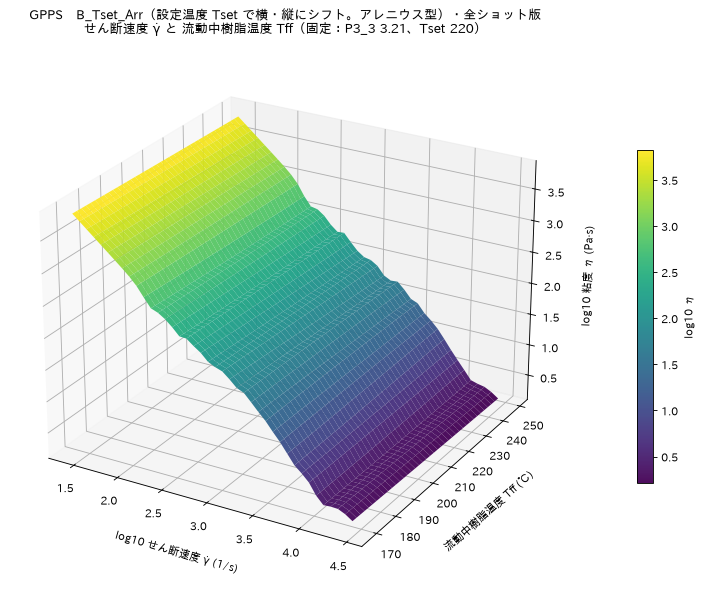

3次元グラフを保存しました


In [70]:
# セル17：3次元グラフ
# ==========================================
# ▼▼ 設定エリア（このセルの設定だけを直して、このセルだけを実行し直せる） ▼▼
# ==========================================
SURF_MODELS = KEYS                                       # 描くモデル
SURF_PAIRS = [("gd", "Tset"), ("gd", "P33"), ("gd", "Tff")]   # 動かす 2 つの変数（gd：せん断速度、P33：P3_3、Tff：流動中樹脂温度、Tset：設定温度）
SURF_N = 40                                              # 格子の細かさ
SURF_VIEW = (25, -60)                                    # 視点（仰角, 方位角）[度]
SURF_FIX = {}                                            # 固定する値を変えるとき。例：{"P33": 5.0, "Tff": 220.0}（空なら学習データの中央値、設定温度は Tref）
SURF_SHOW_MODELS = [MAIN_KEY]                            # 画面にも表示するモデル
# ==========================================
for mat in MATERIALS:
    pool = pd.concat([TRAIN[mat], TEST[mat]], ignore_index=True)
    base = {**base_point(TRAIN[mat], kcfg(mat, KEY)), **SURF_FIX}
    for key in SURF_MODELS:
        for va, vb in SURF_PAIRS:
            ga, gb = var_grid(pool, va, SURF_N), var_grid(pool, vb, SURF_N)
            A, B = np.meshgrid(ga, gb)
            mu, _, _, _ = predict(FITS[(mat, key)], model_inputs(**{**base, va: A, vb: B}))
            Z = (mu / np.log(10)).reshape(A.shape)
            xa = np.log10(A) if VAR_JA[va][2] else A
            yb = np.log10(B) if VAR_JA[vb][2] else B
            fig = plt.figure(figsize=(12, 9))
            ax = fig.add_subplot(111, projection="3d")
            surf = ax.plot_surface(xa, yb, Z, cmap="viridis", edgecolor="none", alpha=0.95)
            lab = lambda v: ("log10 " if VAR_JA[v][2] else "") + VAR_JA[v][0] + " " + VAR_JA[v][1]
            ax.set_xlabel(lab(va), labelpad=12)
            ax.set_ylabel(lab(vb), labelpad=12)
            ax.set_zlabel("log10 粘度 η (Pa·s)", labelpad=10)
            ax.view_init(*SURF_VIEW)
            fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1, label="log10 η")
            others = "、".join(f"{VAR_JA[k][0].split(' ')[-1]} {v:.3g}" for k, v in base.items() if k not in (va, vb))
            ax.set_title(f"{MAT_NAMES[mat]}　{model_title(key)}\n{VAR_JA[va][0]} と {VAR_JA[vb][0]}（固定：{others}）")
            save_fig(fig, out_dir(mat, key, "3次元グラフ"), f"3次元_{va}_{vb}", show=SHOW_FIGS and key in SURF_SHOW_MODELS)
print("3次元グラフを保存しました")

## 12. 学習済みモデルの保存（6月のノートのセル16）

モデルのフォルダに `学習済みモデル_<モデル>.joblib` として保存する（学習データ・検証データの場所も記録する。Git には入れない。このノートを実行すれば、いつでも作り直せる）。使い方（このノートの「共通の部品」のセルを実行した後で。ノートの外で使うときは、先に `import sys; sys.path.insert(0, "04_補助スクリプト"); from mat_common import *` で、同じ部品を読み込む）：

```python
import joblib
obj = joblib.load(r"…/全ショット版/全厚み総合/B_Tset_Arr_アレニウス型の温度シフトに加熱シリンダ温度採用/学習済みモデル_B_Tset_Arr.joblib")
X = model_inputs(gd=[1000, 5000], P33=[5.0, 3.0], Tff=[210.0, 215.0], Tset=[210.0, 210.0])   # γ̇ [1/s]、P3_3 [MPa]、Tff [℃]、Tset [℃]
mu, sd, sd_latent, noise_sd = predict(obj["fit"], X)       # ln η の予測平均と、予測標準偏差（ノイズ込み）
eta = np.exp(mu)                                         # 粘度 [Pa·s]。95% 予測区間は np.exp(mu ± 1.96 * sd)
```
入力の取り方がショットごと（`INPUT_MODE = "shot"`。既定）のモデルでは、入れる γ̇・P3_3・Tff は、1 ショットで測った値にする。条件平均（`"cond"`）のモデルでは、予測したい条件の平均の値（測った値の平均）にする。

記録の「学習した厚み」は、`THICKNESS` の値（`None` は全厚み）。記録の「学習データのファイル」は、厚みを選ぶ前のファイル（厚みを選んだときは、その中の、その厚みの行だけで学習した）。

In [71]:
# セル18：学習済みモデルの保存
import joblib
import sklearn
for mat in MATERIALS:
    for key in KEYS:
        path = os.path.join(out_dir(mat, key), f"学習済みモデル_{key}.joblib")
        joblib.dump({"fit": FITS[(mat, key)], "材料": MAT_NAMES[mat], "モデル": key, "説明": model_title(key), "入力": input_labels(key), "入力の取り方": INPUT_MODE,
                     "シフトファクター": kcfg(mat, key), "学習データのファイル": show_path(SOURCES[mat]["5data"]), "検証データのファイル": show_path(SOURCES[mat]["3data"]),
                     "scikit-learn": sklearn.__version__, "作成日": time.strftime("%Y-%m-%d"), "学習した厚み": THICKNESS}, path)
        print("保存:", show_path(path))

保存: 05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習結果\3回目_03_GPPS実験_学習結果\全ショット版\全厚み総合\B_Tset_Arr_アレニウス型の温度シフトに加熱シリンダ温度採用\学習済みモデル_B_Tset_Arr.joblib


## 13. まとめ

判定の一覧（★ の行を確かめる）と、モデルの主な結果（θ と 95% 区間、3data の RMSE・被覆率。参考の Cross-WLF も）。モデルのフォルダの `判定の一覧.csv`・`まとめ.csv` に保存する（`まとめ.csv` の「厚み」は、学習した厚み。全厚みなら「全厚み」）。

In [72]:
# セル19：まとめ
JT = pd.DataFrame(JUDGES)
print(f"判定 {len(JT)} 件のうち、★要確認 {int((JT['判定'] != 'OK').sum())} 件")
display(JT[JT["判定"] != "OK"])
SUM = []
for mat in MATERIALS:
    for key in KEYS + (["Cross-WLF"] if mat in CW else []):
        row = {"材料": MAT_NAMES[mat], "モデル": key, "入力": VERSION_DIRS[INPUT_MODE], "厚み": "全厚み" if THICKNESS is None else f"{THICKNESS:g} mm"}
        if key in SHIFT_KEYS:
            thn, tvn, un = theta_names(kcfg(mat, key))
            row["型"] = FORM_JA[kcfg(mat, key)["type"]]
            b = BEST[(mat, key)]
            row.update({"θ": f"{thn} {b['th_best']:g}［{b['th_lo']:g}〜{b['th_hi']:g}］・{tvn} {b['tv_best']:g}［{b['tv_lo']:g}〜{b['tv_hi']:g}］{un}", "LML": round(b["LML_best"], 1),
                        "θ=0 との LML の差": round(b["dLML_vs_0"], 2), "支持の基準": lrt_limit(key), "尤度で支持": bool(b["dLML_vs_0"] >= lrt_limit(key))})
        elif key == "C":
            row["LML"] = round(float(KT[(KT["材料"] == MAT_NAMES[mat]) & (KT["model"] == "C")]["LML"].iloc[0]), 1)
        t = MT_ALL[(MT_ALL["材料"] == MAT_NAMES[mat]) & (MT_ALL["モデル"] == key)].set_index("範囲")
        for s in ["全体", "低速側", "高速側"]:
            if s in t.index:
                row[f"RMSE {s}"] = round(float(t.loc[s, "RMSE"]), 4)
        row["被覆率 全体"] = round(float(t.loc["全体", "coverage95"]), 3)
        row["R²(実数) 全体"] = round(float(t.loc["全体", "R2_real"]), 4)
        SUM.append(row)
SUM = pd.DataFrame(SUM)
display(SUM)
for mat in MATERIALS:
    to_csv(JT[JT["材料"].isin([MAT_NAMES[mat], ""])], os.path.join(out_dir(mat), "判定の一覧.csv"))
    to_csv(SUM[SUM["材料"] == MAT_NAMES[mat]], os.path.join(out_dir(mat), "まとめ.csv"))
print("結果の置き場所：" + "、".join(show_path(out_dir(m)) for m in MATERIALS))

判定 18 件のうち、★要確認 0 件


,節,材料,判定,内容


,材料,モデル,入力,厚み,型,θ,LML,θ=0 との LML の差,支持の基準,尤度で支持,RMSE 全体,RMSE 低速側,RMSE 高速側,被覆率 全体,R²(実数) 全体
0,GPPS,B_Tset_Arr,全ショット版,全厚み,アレニウス型,E_h 1［1〜1］・E_v 9［7〜11］kJ/mol,936.2,22.58,3.0,True,0.1213,0.1758,0.0668,0.825,0.9673
1,GPPS,Cross-WLF,全ショット版,全厚み,NaN,NaN,NaN,NaN,NaN,NaN,0.6759,0.7364,0.6346,0.588,0.5414


結果の置き場所：05_材料ごとの機械学習データと予測検証データ\03_GPPS実験\03_学習結果\3回目_03_GPPS実験_学習結果\全ショット版\全厚み総合\B_Tset_Arr_アレニウス型の温度シフトに加熱シリンダ温度採用
